# RFP 청킹 전략 비교 실험

## 1. 실험 목적 및 환경

### 1.1 실험 목적

본 실험은 공공 RFP 문서의 특성을 고려하여
길이 기반 청킹과 구조 기반 청킹의 차이를 분석하고,
RAG 검색에 적합한 청킹 전략을 선정하는 것을 목적으로 한다.

기존 EDA에서는 RFP 문서에 요구사항 ID, 표, 제목,
상세 설명 등 구조적 정보가 포함되어 있음을 확인하였다.

특히 요구사항 ID와 상세 설명이 분리되거나,
표의 구조적 관계가 손실되면 검색 결과의 문맥을
파악하기 어려워질 수 있다.

따라서 동일한 입력 데이터에 두 가지 청킹 방식을 적용하고,
다음 항목을 비교한다.

1. 생성된 Chunk 수와 글자 수 기준 길이 분포
2. 요구사항 ID와 상세 설명의 문맥 유지 여부
3. 표 내용과 구조의 보존 여부
4. 청킹 방식별 장단점 및 적용 가능성

실험 결과를 바탕으로 최종 청킹 전략을 선정한다.

### 1.2 실험 원칙

- 두 청킹 방식에 동일한 입력 데이터를 사용한다.
- 본 비교 실험에서는 글자 수를 기준으로 청킹을 수행한다. 실제 팀 청킹 모듈의 토큰 기반 결과는 별도 비교군으로 구분한다.
- 원본 텍스트와 메타데이터는 변경하지 않는다.
- 기존 전처리 산출물과 검색 색인을 수정하지 않는다.
- 실제 측정한 결과만 비교하고 기록한다.
- 검색 성능 평가는 청킹 자체의 품질 평가와 구분한다.

### 공개 전 검토 보완 — 2026-10-19

기존 분석의 표·그래프·수치는 유지하고 최종 전체 실행과 대조했다. 설정 셀(0부터 1, 3, 4, 148, 150)의 출력은 코드에 맞는 새 실행 결과로 갱신했다. 단일 커널의 전체 순서 실행 및 신규 검증 범위는 마지막 절에 기록한다. 1~9장의 직접 구현한 비교 실험의 길이 단위는 Python `len()`의 문자 수이며, 10장의 실제 팀 모듈 비교군은 별도로 토큰 수를 사용한다.

**코드 출처:** 기존 전처리 파이프라인은 Retriever 담당 팀원의 청킹 모듈을 사용했다. 이 노트북의 `length_based_chunking`, `structural_chunking`, `improved_structural_chunking`, `v12_structural_chunking`은 별도로 작성한 비교실험용 구현이다. 실제 팀 알고리즘과 동일하다는 주장은 하지 않는다. 기존 비교 결과와 마지막 팀 모듈 비교군은 분리한다.

**실행 설정:** `RFP_EXPERIMENT_ROOT`는 기존 실험 자료 루트, `RFP_NATIVE_ELEMENTS`는 Native elements.jsonl의 정확한 경로(생략 시 루트 아래 data/native/run-1/elements.jsonl), `RFP_V12_DIR`는 final_records.jsonl과 final_elements.jsonl이 있는 정확한 패키지 폴더다. `RFP_CHUNK_OUTPUT_DIR`는 새 산출물 전용 폴더이며 기본값은 현재 폴더 아래 work/chunking_review_outputs다. 외부 파일과 원본 전처리 데이터는 자동 생성하지 않는다. 첫 파일 선택과 Desktop 자동 탐색을 제거했다. 같은 v12라는 이름이어도 다른 패키지의 파일 해시가 다르면 같은 입력이 아니다.

**표본 범위:** Native는 본문·표·제목이 있는 그룹 중 Element 수가 가장 많은 1개, v12는 요구사항 ID·제목 경로·Record 수 순으로 정렬한 첫 문서다. 무작위 표본이 아니므로 96/98개 문서 전체의 우열로 일반화하지 않는다. 동률이면 입력 파일의 순서가 선택에 영향을 줄 수 있어 마지막 실행 증거에 파일·대표입력 해시를 남긴다. Native와 v12는 버전·표현·대표문서가 달라 전후 성능 개선의 통제 비교가 아니다.

| 조건 | 길이 기반 | Native 구조 기반 | v12 구조 기반 |
|---|---|---|---|
| 길이 제한 | 500자 | 500자 | 500자 |
| Overlap | 50자 | 0자 | 0자 |
| 입력 | search_text를 줄바꿈으로 연결 | 본문 search_text, 표는 cells 재구성 | 같은 선택 Record의 search_text |
| 순서 | 공통 선택 요소/Record 순서 | source_order, 표는 row/col 순 | hwp_element_index, raw_start 순 |
| 표 분할 | 문자 창으로 분할 | 행 단위, 500자 초과 행은 문자 분할 | Record가 500자를 넘으면 문자 분할; 셀 격자 미사용 |
| 요구사항 경계 | 고려 안 함 | 명시적 ID 경계 검사 없음 | 비어 있지 않은 metadata ID 집합이 서로소이면 분리 |

동일 최대 길이만으로 통제 비교가 되지 않는다. 특히 Native 표 재구성·Overlap·경계 정책 차이가 동시에 존재한다. v12도 일부 ID를 공유하면 합쳐질 수 있으며 메타데이터가 비어 있으면 ID 경계 조건이 작동하지 않는다. v12 대표문서의 좌표 중복/겹침은 기존 분석대로 유지하며 임의 중복 제거하지 않았다. raw_start/raw_end는 소속 원문 요소의 좌표 체계를 함께 확인해야 하며 서로 다른 요소 간 수치만으로 겹침 오류를 판정하지 않는다.

**보존 검증의 범위:** 공백·표 구분 기호를 제거한 문자열의 동일성은 남은 문자(숫자 포함)의 순서 비교다. 공백·기호의 의미, 원본 HWP/PDF 문자 인식 정확도, 표 격자·병합·행열, 요구사항 소속, 출처 좌표·Chunk span 전달까지 인증하지 않는다. 셀 문자열의 포함 여부는 셀 중복·위치·소속을 검증하지 않는다. ID 뒤 남은 글자 수는 설명 연결의 보조 지표이며 실제 설명 여부를 판단하지 않는다. 여러 ID가 같은 Chunk에 있어도 요약표·상호참조일 수 있어 소속 오류율로 해석하지 않는다. Retriever/Generation 성능은 측정하지 않았다.


### 최종 검증 실행 안내 (2026-10-19)

Desktop 최신 212셀을 기준으로 팀 결과 계약 검사 1셀을 추가했다. 파일 전체를 위에서 아래로 새 커널에서 실행한다. 필수 환경변수는 `RFP_EXPERIMENT_ROOT`, `RFP_V12_DIR`, `RFP_TEAM_SRC`이며, `RFP_NATIVE_ELEMENTS`, `RFP_CHUNK_OUTPUT_DIR`, `TIKTOKEN_CACHE_DIR`로 정확한 입력·출력·토크나이저 캐시를 지정한다. 개인 경로가 포함된 환경 설정은 커밋하지 않는다.

Python 3.10 이상이 필요하다(`Path.is_relative_to` 사용). 이 검증에서는 Python 3.13.5를 사용한다. 노트북에는 pandas, matplotlib, IPython, ipykernel이 필요하며 팀 소스의 간접 import를 위해 numpy, pydantic, pydantic-settings, python-dotenv, psycopg[binary], psycopg-pool, pgvector, tiktoken이 필요하다. 외부 팀 소스와 동일 SHA의 소스 트리 및 Native/v12 파일은 이 저장소에 새로 포함하지 않는다. 캐시가 없으면 tiktoken이 다운로드를 시도할 수 있으므로 오프라인 실행은 o200k_base 캐시를 먼저 준비한다. 이 검증의 전체 패키지 버전은 마지막 절에 기록한다.

팀 소스는 기록한 chunking.py SHA와 같아야 하며, 다른 소스에 기존 숫자를 그대로 적용하지 않는다. 팀 검증 생략이나 assertion 실패는 최종 검증 통과로 처리하지 않는다. 기존 그래프와 분석 표는 보존하고, 설정 코드와 맞지 않는 과거 설정 출력만 새 실행 출력으로 갱신한다. 나머지 저장 결과는 이번 재실행의 수치 대조를 거친 역사 출력이다.


In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# 외부 실험 자료를 포함한 루트를 명시한다. 현재 작업 폴더를 루트로 가정하지 않는다.
if not os.environ.get("RFP_EXPERIMENT_ROOT"):
    raise RuntimeError("RFP_EXPERIMENT_ROOT를 기존 실험 자료 루트로 설정하세요.")
PROJECT_ROOT = Path(os.environ["RFP_EXPERIMENT_ROOT"]).expanduser().resolve()
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError("설정한 실험 자료 루트가 없습니다.")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = Path(os.environ.get("RFP_CHUNK_OUTPUT_DIR", "work/chunking_review_outputs")).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("실험 자료 루트 확인 완료")
print("데이터 디렉터리 존재 여부:", DATA_DIR.is_dir())
print("실험 결과 저장 디렉터리 준비 완료")


실험 자료 루트 확인 완료
데이터 디렉터리 존재 여부: True
실험 결과 저장 디렉터리 준비 완료


## 2. 실험 데이터 확인

### 2.1 데이터 확인

청킹은 긴 문서를 검색하기 좋은 크기로 나누는 작업이다.

이번 실험에서는 같은 문서를 두 가지 방법으로 나누고
어떤 방법이 RFP 문서의 내용을 더 잘 유지하는지 비교한다.

먼저 기존 전처리 결과 중 Record와 Element를 확인한다.

- **Record:** 원본 문서에서 추출하고 정리한 내용
- **Element:** 본문, 표 등 문서의 구성에 따라 나눈 내용
- **Chunk:** 검색에 사용하기 위해 최종적으로 나눈 내용

Record와 Element를 확인한 후
두 청킹 방법에 사용할 데이터를 선택한다.

In [2]:
# 자동 탐색의 첫 파일 선택 대신 실제 입력 파일을 명시한다.
native_input = Path(os.environ.get(
    "RFP_NATIVE_ELEMENTS", str(DATA_DIR / "native" / "run-1" / "elements.jsonl")
)).expanduser().resolve()
if not native_input.is_file():
    raise FileNotFoundError("Native elements 입력을 RFP_NATIVE_ELEMENTS로 설정하세요.")
found_files = {"Record": [], "Element": [native_input], "Chunk": []}
for name, matches in found_files.items():
    print(f"{name}: {len(matches)}개 지정")
print("입력 파일은 읽기 전용으로 사용하며 경로는 표시하지 않습니다.")


Record: 0개 지정
Element: 1개 지정
Chunk: 0개 지정
입력 파일은 읽기 전용으로 사용하며 경로는 표시하지 않습니다.


In [3]:
element_files = found_files["Element"]
if len(element_files) != 1:
    raise ValueError("Native Element 입력을 하나만 지정하세요.")
element_path = element_files[0]
print("Element 입력 파일 지정 완료")
print(f"파일 크기: {element_path.stat().st_size / (1024 * 1024):.2f} MB")


Element 입력 파일 지정 완료
파일 크기: 80.08 MB


### 2.2 Element 데이터 구조 확인

Element는 문서의 본문, 표 등을 구분해서 저장한 데이터다.

구조 기반 청킹을 하려면 Element에
문서의 종류와 위치, 제목 등의 정보가 있는지 확인해야 한다.

먼저 데이터에 어떤 항목이 저장되어 있는지 살펴본다.

이 단계에서는 원문 내용은 출력하지 않는다.

In [7]:
import json

# 첫 번째 Element만 읽기
with open(element_path, "r", encoding="utf-8") as f:
    first_element = json.loads(f.readline())

# 최상위 항목 이름 확인
print("Element 데이터 항목:")
for key in first_element.keys():
    print("-", key)

# 메타데이터 구조 확인
if "metadata" in first_element:
    metadata = first_element["metadata"]

    if isinstance(metadata, dict):
        print("\n메타데이터 항목:")
        for key in metadata.keys():
            print("-", key)

Element 데이터 항목:
- element_id
- source_order
- kind
- parent_id
- raw_text
- search_text
- location
- table
- replacement_chars
- extraction_id


### 2.3 청킹에 필요한 정보 확인

길이 기반 청킹은 주로 텍스트의 길이를 기준으로 나눈다.

반면 구조 기반 청킹은 본문과 표의 구분,
문서의 순서와 위치 같은 정보도 필요하다.

따라서 현재 Element에 어떤 구조 정보가 있는지 확인한다.

이 단계에서는 실제 원문은 출력하지 않는다.

In [8]:
# Element의 종류 확인
print("Element 종류(kind):")
print(type(first_element.get("kind")).__name__)

# 원본 순서 정보 확인
print("\n원본 순서(source_order):")
print(type(first_element.get("source_order")).__name__)

# location 내부 구조 확인
location = first_element.get("location")

print("\nlocation 자료형:")
print(type(location).__name__)

if isinstance(location, dict):
    print("location 내부 항목:")
    for key, value in location.items():
        print(f"- {key}: {type(value).__name__}")

# table 내부 구조 확인
table = first_element.get("table")

print("\ntable 자료형:")
print(type(table).__name__)

if isinstance(table, dict):
    print("table 내부 항목:")
    for key, value in table.items():
        print(f"- {key}: {type(value).__name__}")

Element 종류(kind):
str

원본 순서(source_order):
int

location 자료형:
dict
location 내부 항목:
- format: str
- section: int
- path: str
- section_path: list

table 자료형:
NoneType


### 2.4 Element 종류와 구조 정보 확인

지금까지는 Element 한 개의 저장 형태를 확인했다.

이번에는 전체 Element를 살펴보고
본문과 표가 각각 얼마나 있는지 확인한다.

또한 문서의 제목 경로와 표 구조 정보가
얼마나 저장되어 있는지도 확인한다.

이 결과를 바탕으로 구조 기반 청킹에
어떤 정보를 활용할 수 있을지 판단한다.

In [9]:
from collections import Counter
import json
import pandas as pd

kind_counts = Counter()

total_elements = 0
section_path_count = 0
table_info_count = 0

with open(element_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        element = json.loads(line)
        total_elements += 1

        # Element 종류
        kind_counts[element.get("kind", "unknown")] += 1

        # 제목 경로 정보
        location = element.get("location") or {}

        if location.get("section_path"):
            section_path_count += 1

        # 표 구조 정보
        if element.get("table") is not None:
            table_info_count += 1

# 종류별 분포
df_kind = pd.DataFrame(
    kind_counts.items(),
    columns=["Element 종류", "개수"]
)

df_kind["비율(%)"] = (
    df_kind["개수"] / total_elements * 100
).round(2)

display(df_kind.sort_values("개수", ascending=False))

print(f"\n전체 Element: {total_elements:,}개")
print(f"제목 경로가 있는 Element: {section_path_count:,}개")
print(f"표 구조 정보가 있는 Element: {table_info_count:,}개")

,Element 종류,개수,비율(%)
0,paragraph,38255,67.47
1,table,11377,20.07
3,heading,6074,10.71
2,toc,993,1.75



전체 Element: 56,699개
제목 경로가 있는 Element: 55,064개
표 구조 정보가 있는 Element: 12,159개


### 2.5 문서 구분 정보 확인

청킹을 할 때는 서로 다른 문서의 내용이 섞이지 않아야 한다.

따라서 Element에 문서를 구분할 수 있는 정보가
저장되어 있는지 확인한다.

이후 하나의 RFP 문서를 선택하여
길이 기반과 구조 기반 청킹을 비교할 예정이다.

In [10]:
# 문서 구분에 사용할 수 있는 정보 확인
# 실제 값은 출력하지 않고 항목 이름만 확인한다.

print("Element 최상위 항목:")
print(list(first_element.keys()))

print("\nlocation 내부 항목:")
location = first_element.get("location") or {}

if isinstance(location, dict):
    print(list(location.keys()))

print("\nextraction_id 자료형:")
print(type(first_element.get("extraction_id")).__name__)

print("\nparent_id 자료형:")
print(type(first_element.get("parent_id")).__name__)

Element 최상위 항목:
['element_id', 'source_order', 'kind', 'parent_id', 'raw_text', 'search_text', 'location', 'table', 'replacement_chars', 'extraction_id']

location 내부 항목:
['format', 'section', 'path', 'section_path']

extraction_id 자료형:
str

parent_id 자료형:
NoneType


## 3. 청킹 실험 데이터 선정

### 3.1 문서별 데이터 확인

지금까지 Element에 본문, 제목, 표 등의 정보가
저장되어 있다는 것을 확인했다.

이번에는 같은 문서에 속한 Element를 묶어
문서별 데이터 구성을 살펴본다.

길이 기반과 구조 기반 청킹을 공정하게 비교하기 위해
두 방식에 동일한 문서를 사용한다.

원본 파일명과 실제 내용은 출력하지 않는다.

In [11]:
from collections import defaultdict, Counter
import json
import pandas as pd

# 문서별 Element 종류 집계
doc_stats = defaultdict(Counter)

with open(element_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        element = json.loads(line)

        location = element.get("location") or {}
        doc_path = location.get("path")

        # 원본 경로가 없는 데이터는 별도로 구분
        if not doc_path:
            continue

        kind = element.get("kind", "unknown")
        doc_stats[doc_path][kind] += 1

# 문서별 개수만 정리 (원본 파일명 제외)
rows = []

for counts in doc_stats.values():
    rows.append({
        "본문": counts.get("paragraph", 0),
        "표": counts.get("table", 0),
        "제목": counts.get("heading", 0),
        "목차": counts.get("toc", 0),
        "전체": sum(counts.values())
    })

df_docs = pd.DataFrame(rows)

print(f"문서 구분값 수: {len(df_docs):,}개")

display(
    df_docs.describe().round(1)
)

문서 구분값 수: 9,898개


,본문,표,제목,목차,전체
count,9898.0,9898.0,9898.0,9898.0,9898.0
mean,3.9,1.1,0.6,0.1,5.7
std,9.3,3.4,1.6,0.8,11.0
min,0.0,0.0,0.0,0.0,1.0
25%,0.0,0.0,0.0,0.0,1.0
50%,1.0,0.0,0.0,0.0,1.0
75%,2.0,1.0,0.0,0.0,3.0
max,55.0,33.0,17.0,16.0,71.0


### 3.2 문서 구분 기준 확인

Element를 원본 경로로 묶었더니 9,898개 그룹이 나왔다.

하지만 원본 RFP 문서는 98개이므로,
현재 사용한 값이 실제 문서 ID인지 확인할 필요가 있다.

이번에는 다른 식별 정보도 비교하여
같은 문서의 Element를 올바르게 묶을 방법을 찾는다.

In [12]:
import json

extraction_ids = set()
location_paths = set()
location_sections = set()

with open(element_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        element = json.loads(line)
        location = element.get("location") or {}

        extraction_id = element.get("extraction_id")
        location_path = location.get("path")
        location_section = location.get("section")

        if extraction_id is not None:
            extraction_ids.add(extraction_id)

        if location_path is not None:
            location_paths.add(location_path)

        if location_section is not None:
            location_sections.add(location_section)

print("서로 다른 extraction_id 수:", len(extraction_ids))
print("서로 다른 location.path 수:", len(location_paths))
print("서로 다른 location.section 수:", len(location_sections))

서로 다른 extraction_id 수: 96
서로 다른 location.path 수: 9898
서로 다른 location.section 수: 9


### 3.3 청킹 실험 대상 선정

같은 문서에 속한 데이터를 구분하기 위해
`extraction_id`를 기준으로 Element를 묶어본다.

본문, 제목, 표가 함께 있는 데이터를 선택하면
두 청킹 방식의 차이를 더 쉽게 확인할 수 있다.

원본 문서명과 식별자는 공개하지 않는다.

In [13]:
from collections import defaultdict, Counter
import json
import pandas as pd

# extraction_id별 Element 종류 집계
group_stats = defaultdict(Counter)

with open(element_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        element = json.loads(line)
        group_id = element.get("extraction_id")

        if group_id is None:
            continue

        kind = element.get("kind", "unknown")
        group_stats[group_id][kind] += 1

# 원본 ID를 출력하지 않고 익명 번호 부여
rows = []

for group_id, counts in group_stats.items():
    rows.append({
        "그룹 ID": group_id,
        "본문": counts.get("paragraph", 0),
        "표": counts.get("table", 0),
        "제목": counts.get("heading", 0),
        "전체": sum(counts.values())
    })

df_groups = pd.DataFrame(rows)

# 본문·표·제목이 모두 존재하는 그룹만 선택
candidates = df_groups[
    (df_groups["본문"] > 0) &
    (df_groups["표"] > 0) &
    (df_groups["제목"] > 0)
].copy()

# 데이터가 풍부한 그룹부터 정렬
candidates = candidates.sort_values(
    "전체", ascending=False
).reset_index(drop=True)

# 외부 출력에는 실제 그룹 ID를 노출하지 않음
candidates.insert(
    0,
    "실험 후보",
    [f"후보 {i+1}" for i in range(len(candidates))]
)

print("실험 후보 수:", len(candidates))

display(
    candidates[
        ["실험 후보", "본문", "표", "제목", "전체"]
    ].head(10)
)

실험 후보 수: 96


,실험 후보,본문,표,제목,전체
0,후보 1,1353,175,148,1699
1,후보 2,1150,163,107,1441
2,후보 3,910,410,86,1433
3,후보 4,1011,91,62,1164
4,후보 5,663,173,96,968
5,후보 6,564,228,78,880
6,후보 7,754,12,113,879
7,후보 8,590,183,38,811
8,후보 9,545,151,98,803
9,후보 10,562,190,49,801


#### 분석 결과 및 해석

전체 96개 그룹에서 본문, 표, 제목이 모두 포함된 것을 확인하였다.

그중 후보 1은 전체 1,699개 Element로 구성되어 있으며,
본문 1,353개, 표 175개, 제목 148개를 포함하고 있다.

본문뿐 아니라 표와 제목도 충분히 포함되어 있어
두 청킹 방식의 차이를 비교하기에 적합하다고 판단하였다.

따라서 후보 1을 첫 번째 실험 대상으로 선정하였다.

다만 현재 데이터는 Native 추출 결과이므로,
최종 전처리 데이터와는 구분하여 분석한다.


Element에 저장된 식별 정보를 비교한 결과는 다음과 같다.

| 구분 항목 | 서로 다른 값의 개수 |
|---|---:|
| extraction_id | 96개 |
| location.path | 9,898개 |
| location.section | 9개 |

`location.path`를 기준으로 데이터를 묶었을 때
9,898개의 그룹이 생성되었다.

이는 원본 문서 98개와 큰 차이가 있어,
해당 값을 문서 구분 기준으로 사용하기는 어렵다고 판단하였다.

반면 `extraction_id`는 96개로 나타나
문서별 데이터를 구분할 수 있는 후보로 확인되었다.

다만 현재 분석 중인 파일은 Native 추출 데이터이므로,
`extraction_id`가 실제 문서 하나와 정확하게 대응하는지는
추가 확인이 필요하다.

**다음 단계**

`extraction_id`를 임시 기준으로 Element를 묶고,
본문·표·제목이 포함된 실험 대상을 선정한다.

## 4. 청킹 실험 데이터 준비

### 4.1 대표 데이터 불러오기

앞서 선정한 후보 1의 Element를 불러온다.

길이 기반과 구조 기반 청킹에
같은 데이터를 사용하기 위한 준비 과정이다.

원본 파일이나 데이터는 수정하지 않는다.

In [14]:
import json
from collections import Counter

# 후보 1의 실제 extraction_id
selected_group_id = candidates.iloc[0]["그룹 ID"]

# 후보 1에 속한 Element만 불러오기
selected_elements = []

with open(element_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        element = json.loads(line)

        if element.get("extraction_id") == selected_group_id:
            selected_elements.append(element)

# 원본 순서대로 정렬
selected_elements.sort(key=lambda x: x.get("source_order", 0))

print("선택한 Element 수:", len(selected_elements))

print("\nElement 종류별 개수:")
for kind, count in Counter(
    e.get("kind") for e in selected_elements
).items():
    print(f"- {kind}: {count}")

print("\n원본 순서 정렬 완료")

선택한 Element 수: 1699

Element 종류별 개수:
- paragraph: 1353
- table: 175
- heading: 148
- toc: 23

원본 순서 정렬 완료


### 4.3 실험 데이터 최종 확인

앞에서 선택한 데이터는 총 1,699개의 Element로 구성되어 있다.

길이 기반과 구조 기반 청킹을 비교하기 전에
선택한 데이터가 하나의 문서에 속하는지 확인한다.

또한 청킹에 사용할 텍스트가 있는지 확인한다.

이 단계에서는 원문 내용이나 파일명을 출력하지 않는다.

In [15]:
from collections import Counter

# 선택한 그룹의 문서 식별 정보 확인
extraction_ids = {
    e.get("extraction_id")
    for e in selected_elements
    if e.get("extraction_id") is not None
}

# 원본 위치 정보의 형식 확인
location_formats = Counter(
    (e.get("location") or {}).get("format", "unknown")
    for e in selected_elements
)

# 검색용 텍스트 확인
text_count = sum(
    bool((e.get("search_text") or "").strip())
    for e in selected_elements
)

empty_count = len(selected_elements) - text_count

print("서로 다른 extraction_id:", len(extraction_ids))
print("원본 형식별 Element 수:", dict(location_formats))
print("검색용 텍스트가 있는 Element:", text_count)
print("검색용 텍스트가 없는 Element:", empty_count)

서로 다른 extraction_id: 1
원본 형식별 Element 수: {'pdf': 1699}
검색용 텍스트가 있는 Element: 1699
검색용 텍스트가 없는 Element: 0


#### 분석 결과 및 해석

선택한 데이터는 총 1,699개의 Element로 구성되어 있다.

모든 Element의 `extraction_id`가 동일하고,
원본 형식은 PDF로 확인되었다.

또한 1,699개 Element 모두 검색용 텍스트가 있어
청킹 실험에 사용할 수 있는 상태이다.

따라서 이 데이터를 첫 번째 비교 실험 대상으로 선정하였다.

길이 기반과 구조 기반 청킹에 동일한 데이터를 사용하여
분할 방식에 따른 차이를 확인할 예정이다.

단, 동일한 추출 그룹이라는 사실만으로
원본 문서와의 일대일 대응이 검증된 것은 아니다.

## 5. 길이 기반 청킹 실험

### 5.1 청킹 방법

길이 기반 청킹은 정해진 길이에 맞춰
긴 텍스트를 여러 개의 Chunk로 나누는 방법이다.

Chunk가 너무 길면 검색과 모델 입력에 부담이 될 수 있고,
너무 짧으면 관련 내용이 여러 Chunk로 나뉠 수 있다.

이를 보완하기 위해 앞 Chunk의 일부 내용을
다음 Chunk에 다시 포함하는 Overlap을 사용할 수 있다.

이번 실험에서는 동일한 검색용 텍스트를 사용하여
길이 기반 청킹 결과를 확인한다.

In [16]:
# 청킹에 사용할 텍스트만 추출
texts = [
    element["search_text"]
    for element in selected_elements
]

# 전체 글자 수
total_chars = sum(len(text) for text in texts)

print(f"Element 수: {len(texts):,}개")
print(f"전체 글자 수: {total_chars:,}자")
print(f"평균 글자 수: {total_chars / len(texts):,.1f}자")
print(f"가장 긴 Element: {max(len(text) for text in texts):,}자")

Element 수: 1,699개
전체 글자 수: 108,531자
평균 글자 수: 63.9자
가장 긴 Element: 1,362자


#### 분석 결과 및 해석

청킹에 사용할 Element 1,699개의 텍스트 길이를 확인하였다.

| 항목 | 결과 |
|---|---:|
| 전체 Element | 1,699개 |
| 전체 글자 수 | 108,531자 |
| 평균 글자 수 | 63.9자 |
| 가장 긴 Element | 1,362자 |

Element 하나의 평균 길이는 약 64자로 짧은 편이다.

따라서 Element를 하나씩 Chunk로 만들면
관련 내용이 여러 개로 나뉘어 문맥이 부족할 수 있다.

반대로 여러 Element를 길이만 기준으로 합치면
서로 다른 제목이나 요구사항이 섞일 가능성이 있다.

이에 따라 길이 기반 청킹과 구조 기반 청킹을 각각 실행하여
어떤 방식이 문서의 내용을 더 잘 유지하는지 비교한다.

※ 위 결과는 글자 수 기준이며, 실제 토큰 수와는 다르다.

### 5.2 길이 기반 청킹 실행

길이 기반 청킹은 문서의 내용을 일정한 길이로 나누는 방법이다.

이번 실험에서는 500자씩 나누고,
앞 Chunk의 마지막 50자를 다음 Chunk에도 포함한다.

이렇게 겹치는 부분을 두는 이유는
Chunk가 나뉘는 부분에서 문맥이 갑자기 끊어지는 것을 줄이기 위해서다.

다만 글자 수만 기준으로 나누기 때문에
제목이나 표, 요구사항이 중간에서 분리될 수 있다.

이번 실험에서 사용한 500자와 50자는 비교를 위한 임시 설정이다.

In [17]:
# 길이 기반 청킹 설정
CHUNK_SIZE = 500
CHUNK_OVERLAP = 50

# 동일한 추출 그룹의 검색용 텍스트를 원본 순서대로 연결
full_text = "\n".join(
    element["search_text"]
    for element in selected_elements
)

def length_based_chunking(text, chunk_size, overlap):
    chunks = []

    # 다음 Chunk를 시작할 위치
    step = chunk_size - overlap

    for start in range(0, len(text), step):
        end = start + chunk_size

        chunk = text[start:end]

        if chunk.strip():
            chunks.append(chunk)

        if end >= len(text):
            break

    return chunks


length_chunks = length_based_chunking(
    full_text,
    CHUNK_SIZE,
    CHUNK_OVERLAP
)

print("길이 기반 Chunk 수:", len(length_chunks))
print("첫 번째 Chunk 글자 수:", len(length_chunks[0]))
print("마지막 Chunk 글자 수:", len(length_chunks[-1]))
print("최대 Chunk 글자 수:", max(map(len, length_chunks)))

길이 기반 Chunk 수: 245
첫 번째 Chunk 글자 수: 500
마지막 Chunk 글자 수: 429
최대 Chunk 글자 수: 500


#### 분석 결과 및 해석

대표 PDF 추출 그룹의 검색용 텍스트를 500자씩 나누고,
앞 Chunk의 마지막 50자를 다음 Chunk에 포함하였다.

그 결과 총 245개의 Chunk가 생성되었다.

| 항목 | 결과 |
|---|---:|
| Chunk 크기 | 500자 |
| Overlap | 50자 |
| 생성된 Chunk | 245개 |
| 첫 번째 Chunk 길이 | 500자 |
| 마지막 Chunk 길이 | 429자 |

길이 기반 청킹을 통해 긴 문서를 일정한 크기로 나눌 수 있었다.

하지만 이 방법은 문서의 제목이나 표 구조를 고려하지 않는다.

따라서 Chunk의 크기가 적절하더라도
관련 내용이 중간에 나뉘었을 가능성이 있다.

다음 단계에서는 실제 분할 위치를 확인하여
문서 구조가 얼마나 유지되었는지 분석한다.

### 5.3 길이 기반 청킹의 구조 분리 분석

길이 기반 청킹은 정해진 글자 수에 따라 문서를 나눈다.

따라서 하나의 제목, 본문, 표가
두 개 이상의 Chunk로 나뉠 수 있다.

이번에는 Chunk가 나뉘는 위치를 확인하여
어떤 종류의 Element가 중간에 잘렸는지 분석한다.

원문 내용은 출력하지 않고, 분리된 개수만 확인한다.

In [19]:
from collections import Counter
import pandas as pd

# full_text를 만들 때 사용한 Element별 위치 계산
element_positions = []

current_pos = 0

for element in selected_elements:
    text = element["search_text"]

    start = current_pos
    end = start + len(text)

    element_positions.append({
        "kind": element.get("kind", "unknown"),
        "start": start,
        "end": end,
    })

    # Element 사이에 추가한 줄바꿈 1자
    current_pos = end + 1

# 원본 텍스트 연결 방식과 위치 계산이 일치하는지 확인
assert current_pos - 1 == len(full_text)

# Chunk가 실제로 나뉘는 위치
# Overlap 때문에 다음 Chunk가 시작되는 위치와
# 이전 Chunk가 끝나는 위치를 구분한다.
chunk_boundaries = [
    i * (CHUNK_SIZE - CHUNK_OVERLAP) + CHUNK_SIZE
    for i in range(len(length_chunks) - 1)
]

# 분할 위치가 Element 내부에 있는지 확인
split_counts = Counter()

for boundary in chunk_boundaries:
    for element in element_positions:
        if element["start"] < boundary < element["end"]:
            split_counts[element["kind"]] += 1
            break

df_splits = pd.DataFrame(
    [
        {"Element 종류": kind, "분할 경계 수": count}
        for kind, count in split_counts.items()
    ]
)

display(df_splits.sort_values("분할 경계 수", ascending=False))

print("전체 Chunk 경계:", len(chunk_boundaries))
print("Element 내부에 위치한 경계:", sum(split_counts.values()))

,Element 종류,분할 경계 수
2,table,137
1,paragraph,89
0,toc,5
3,heading,5


전체 Chunk 경계: 244
Element 내부에 위치한 경계: 236


#### 분석 결과 및 해석

길이 기반 청킹으로 생성한 245개 Chunk의 분할 경계를 분석하였다.

| Element 종류 | 내부에 위치한 Chunk 경계 |
|---|---:|
| 표 | 137개 |
| 본문 | 89개 |
| 목차 | 5개 |
| 제목 | 5개 |
| **합계** | **236개** |

전체 244개 Chunk 경계 중 236개(96.7%)가
Element 내부에 위치한 것으로 확인되었다.

특히 표 내부에 위치한 경계가 137개로 가장 많았다.

이는 길이만 기준으로 문서를 나누면
표나 본문이 중간에서 분리될 수 있음을 보여준다.

다만 분할 경계가 있다고 해서
실제로 내용이 누락되거나 손상됐다는 뜻은 아니다.

이번 결과를 바탕으로 문서의 구조를 고려한 청킹을 진행하고,
두 방식의 차이를 비교하고자 한다.

## 6. 구조 기반 청킹 실험

### 6.1 구조 기반 청킹 방법

구조 기반 청킹은 글자 수뿐 아니라
문서의 제목, 본문, 표 등의 구성을 고려하여 나누는 방법이다.

길이 기반 청킹에서는 많은 분할 경계가
표와 본문 내부에 위치하는 것을 확인하였다.

이번에는 문서의 구조를 고려하여
관련 내용을 가능한 한 함께 묶어본다.

긴 내용은 설정한 크기에 맞춰 추가로 나누되,
표와 제목의 관계를 최대한 유지하도록 한다.

이후 길이 기반 청킹과 결과를 비교한다.

In [20]:
from collections import Counter
import pandas as pd

# 500자를 초과하는 Element 확인
long_elements = [
    element
    for element in selected_elements
    if len(element.get("search_text") or "") > CHUNK_SIZE
]

long_kind_counts = Counter(
    element.get("kind", "unknown")
    for element in long_elements
)

df_long = pd.DataFrame(
    [
        {"Element 종류": kind, "500자 초과 개수": count}
        for kind, count in long_kind_counts.items()
    ]
)

print("500자를 초과하는 Element:", len(long_elements))

if not df_long.empty:
    display(
        df_long.sort_values(
            "500자 초과 개수",
            ascending=False
        )
    )

500자를 초과하는 Element: 47


,Element 종류,500자 초과 개수
0,table,47


#### 분석 결과 및 해석

500자를 초과하는 Element를 확인한 결과,
총 47개가 발견되었으며 모두 표(table)였다.

전체 표 175개 중 약 26.9%가 500자를 초과하였다.

이는 구조 기반 청킹에서도
긴 표를 추가로 나누는 방법이 필요하다는 뜻이다.

따라서 이번 실험에서는 다음 방향을 고려한다.

- 짧은 표는 가능하면 하나의 Chunk로 유지한다.
- 긴 표는 행·열 관계를 고려하여 나눈다.
- 분할 후에도 표의 제목과 출처 정보를 유지한다.

단, 실제 표의 행·열 정보를 사용할 수 있는지는
다음 단계에서 확인해야 한다.

### 6.2 표 구조 정보 확인

구조 기반 청킹에서는 표의 내용을
가능하면 의미가 끊기지 않도록 나누는 것이 중요하다.

특히 긴 표를 나눌 때는
행과 열의 관계를 유지할 수 있어야 한다.

따라서 실제 데이터에 표의 구조 정보가
어떤 형태로 저장되어 있는지 확인한다.

원문 내용과 파일명은 출력하지 않는다.

In [21]:
# 500자를 초과하는 표 하나 선택
sample_table = long_elements[0]

# 표 관련 정보 확인
table_info = sample_table.get("table")

print("표 정보 자료형:", type(table_info).__name__)

if isinstance(table_info, dict):
    print("\n표 내부 항목:")
    for key, value in table_info.items():
        print(f"- {key}: {type(value).__name__}")

elif isinstance(table_info, list):
    print("표 정보 항목 수:", len(table_info))

    if table_info:
        print("첫 번째 항목 자료형:", type(table_info[0]).__name__)

        if isinstance(table_info[0], dict):
            print("첫 번째 항목의 필드:")
            print(list(table_info[0].keys()))

else:
    print("이 표에는 별도 구조 정보가 없습니다.")

표 정보 자료형: dict

표 내부 항목:
- rows: int
- cols: int
- caption: str
- cells: list
- merged_spans: str


#### 분석 결과 및 해석

긴 표의 데이터를 확인한 결과,
행과 열의 개수, 표 제목, 셀 정보가 저장되어 있었다.

| 항목 | 저장된 정보 |
|---|---|
| rows | 행 개수 |
| cols | 열 개수 |
| caption | 표 제목 |
| cells | 셀 정보 |
| merged_spans | 병합 셀 관련 정보 |

이는 표를 단순한 텍스트가 아니라
행과 열이 있는 구조로 분석할 수 있다는 뜻이다.

따라서 구조 기반 청킹에서는
표의 행과 열을 고려하여 나누는 방법을 검토할 수 있다.

다만 실제 셀 정보와 병합 관계가
올바르게 저장되어 있는지는 추가 확인이 필요하다.

### 6.3 표의 셀 정보 확인

긴 표를 행 단위로 나누려면
각 셀이 어느 행과 열에 있는지 알아야 한다.

따라서 `cells`에 저장된 정보가
어떤 형태인지 확인한다.

이 결과를 바탕으로 표를 나누는 방법을 결정한다.

원문 내용은 출력하지 않는다.

In [22]:
# 표의 셀 정보 확인
cells = table_info.get("cells")

print("cells 자료형:", type(cells).__name__)
print("cells 항목 수:", len(cells) if isinstance(cells, list) else "확인 불가")

if isinstance(cells, list) and cells:
    first_cell = cells[0]

    print("\n첫 번째 셀 자료형:", type(first_cell).__name__)

    if isinstance(first_cell, dict):
        print("\n첫 번째 셀 항목 및 자료형:")

        for key, value in first_cell.items():
            print(f"- {key}: {type(value).__name__}")

    elif isinstance(first_cell, list):
        print("첫 번째 항목 길이:", len(first_cell))

        if first_cell:
            print("내부 첫 번째 값 자료형:", type(first_cell[0]).__name__)

# 병합 셀 정보의 실제 내용은 출력하지 않음
merged_spans = table_info.get("merged_spans")

print("\nmerged_spans 자료형:", type(merged_spans).__name__)
print("병합 정보 존재 여부:", bool(merged_spans))

cells 자료형: list
cells 항목 수: 39

첫 번째 셀 자료형: dict

첫 번째 셀 항목 및 자료형:
- row: int
- col: int
- rowspan: int
- colspan: int
- text: str
- merged: bool

merged_spans 자료형: str
병합 정보 존재 여부: True


#### 분석 결과 및 해석

500자를 초과하는 표 하나를 확인한 결과,
39개의 셀 정보가 저장되어 있었다.

각 셀에는 행과 열의 위치, 셀 내용,
병합 여부와 병합 범위가 기록되어 있었다.

이는 표를 단순히 글자 수로 나누는 대신,
행과 열의 관계를 고려하여 나눌 수 있다는 뜻이다.

따라서 구조 기반 청킹에서는
표의 행을 기준으로 내용을 묶는 방식을 실험한다.

다만 병합 셀을 여러 행으로 나눌 경우
원래 의미가 달라질 수 있으므로 추가 확인이 필요하다.

### 6.4 표의 행 구성과 병합 셀 확인

구조 기반 청킹에서는 표의 행을 기준으로
관련 내용을 묶는 방법을 실험하려고 한다.

하지만 표에 병합된 셀이 있으면
하나의 셀이 여러 행이나 열에 걸쳐 있을 수 있다.

따라서 행별 셀 개수와 병합 셀 현황을 확인하여
표를 어떤 기준으로 나눌지 결정한다.

원문 내용은 출력하지 않는다.

In [23]:
from collections import Counter
import pandas as pd

cells = table_info["cells"]

# 행별로 시작하는 셀 개수
row_counts = Counter(
    cell["row"]
    for cell in cells
)

# 여러 행 또는 열에 걸친 셀 확인
merged_cells = [
    cell for cell in cells
    if cell.get("rowspan", 1) > 1
    or cell.get("colspan", 1) > 1
]

df_rows = pd.DataFrame([
    {
        "행 번호": row,
        "시작하는 셀 수": count
    }
    for row, count in sorted(row_counts.items())
])

display(df_rows)

print("전체 셀 수:", len(cells))
print("행별 시작 셀 수 합계:", sum(row_counts.values()))
print("여러 행·열에 걸친 셀:", len(merged_cells))
print("여러 행에 걸친 셀:", sum(c.get("rowspan", 1) > 1 for c in cells))
print("여러 열에 걸친 셀:", sum(c.get("colspan", 1) > 1 for c in cells))

,행 번호,시작하는 셀 수
0,0,3
1,1,3
2,2,3
3,3,3
4,4,3
5,5,3
6,6,3
7,7,3
8,8,3
9,9,3


전체 셀 수: 39
행별 시작 셀 수 합계: 39
여러 행·열에 걸친 셀: 0
여러 행에 걸친 셀: 0
여러 열에 걸친 셀: 0


#### 분석 결과 및 해석

선택한 표는 총 13행, 3열로 구성되어 있으며,
전체 셀 수는 39개이다.

각 행에는 3개의 셀이 있고,
여러 행이나 열에 걸쳐 병합된 셀은 확인되지 않았다.

따라서 이번 표는 행을 기준으로 나누는
구조 기반 청킹을 실험하기에 적합하다.

다만 이번 결과는 선택한 표 하나에 대한 분석이다.
다른 표에도 같은 구조가 적용된다고 볼 수는 없다.

다음 단계에서는 표의 행을 유지하면서
500자 이내로 나누는 방법을 구현한다.

### 6.5 표의 행을 기준으로 청킹하기

길이 기반 청킹은 글자 수를 기준으로 표를 나누기 때문에
하나의 행이 중간에서 잘릴 수 있다.

이번에는 같은 행에 있는 셀들을 함께 묶어
표의 내용을 나눠본다.

Chunk의 최대 길이는 길이 기반 청킹과 동일하게
500자로 설정한다.

이렇게 하면 표의 행이 중간에 분리되는 문제를
얼마나 줄일 수 있는지 비교할 수 있다.

In [24]:
from collections import defaultdict

# 행 번호별로 셀 묶기
table_rows = defaultdict(list)

for cell in table_info["cells"]:
    table_rows[cell["row"]].append(cell)

# 각 행을 열 번호 순서로 정렬
for row in table_rows:
    table_rows[row].sort(key=lambda c: c["col"])

# 행별 텍스트 생성
row_texts = []

for row, row_cells in sorted(table_rows.items()):
    row_text = " | ".join(
        str(cell.get("text") or "")
        for cell in row_cells
    )

    row_texts.append({
        "row": row,
        "text": row_text
    })

# 행 단위로 Chunk 생성
table_chunks = []
current_rows = []
current_length = 0

for row_data in row_texts:
    row_text = row_data["text"]

    # 현재 Chunk에 추가하면 500자를 넘는 경우
    if current_rows and current_length + len(row_text) + 1 > CHUNK_SIZE:
        table_chunks.append(current_rows)
        current_rows = []
        current_length = 0

    current_rows.append(row_data)
    current_length += len(row_text) + 1

# 마지막 Chunk 저장
if current_rows:
    table_chunks.append(current_rows)

print("원본 표 행 수:", len(table_rows))
print("생성된 Chunk 수:", len(table_chunks))

for i, chunk in enumerate(table_chunks, start=1):
    text = "\n".join(row["text"] for row in chunk)

    print(
        f"Chunk {i}: "
        f"{len(chunk)}개 행, "
        f"{len(text)}자"
    )

원본 표 행 수: 13
생성된 Chunk 수: 3
Chunk 1: 5개 행, 494자
Chunk 2: 4개 행, 495자
Chunk 3: 4개 행, 317자


#### 분석 결과 및 해석

13행 3열로 구성된 표를 행 단위로 나누었다.

그 결과 총 3개의 Chunk가 생성되었다.

| Chunk | 포함된 행 | 글자 수 |
|---|---:|---:|
| Chunk 1 | 5개 | 494자 |
| Chunk 2 | 4개 | 495자 |
| Chunk 3 | 4개 | 317자 |

모든 Chunk가 500자 이내로 생성되었으며,
13개 행이 빠짐없이 포함되었다.

길이 기반 청킹과 달리 행의 중간에서 나누지 않고,
행과 행 사이를 기준으로 분할하였다.

이를 통해 표의 행 단위 구조를 유지하면서도
설정한 길이 제한을 지킬 수 있음을 확인하였다.

다만 이번 결과는 병합 셀이 없는 표 하나에 대한 실험이다.
다른 표에서도 같은 결과가 나오는지는 추가 검증이 필요하다.

### 6.6 표 내용 전달 검증

구조 기반 청킹으로 표를 3개 Chunk로 나누었다.

하지만 Chunk가 정상적으로 만들어졌다는 사실만으로
원본 내용이 모두 전달되었다고 볼 수는 없다.

따라서 원본 표의 행과
생성된 Chunk에 포함된 행을 비교하여
누락이나 중복이 있는지 확인한다.

In [25]:
from collections import Counter

# 원본 표의 행 번호
original_rows = [row["row"] for row in row_texts]

# Chunk에 포함된 행 번호
chunked_rows = [
    row["row"]
    for chunk in table_chunks
    for row in chunk
]

# 원본과 결과 비교
missing_rows = Counter(original_rows) - Counter(chunked_rows)
duplicated_rows = Counter(chunked_rows) - Counter(original_rows)

# 텍스트도 원본과 같은 순서로 전달됐는지 확인
original_texts = [row["text"] for row in row_texts]

chunked_texts = [
    row["text"]
    for chunk in table_chunks
    for row in chunk
]

print("원본 행 수:", len(original_rows))
print("Chunk에 포함된 행 수:", len(chunked_rows))
print("누락된 행 수:", sum(missing_rows.values()))
print("추가·중복된 행 수:", sum(duplicated_rows.values()))
print("행 순서와 텍스트 일치:", original_texts == chunked_texts)
print(
    "500자 제한 준수:",
    all(
        len("\n".join(row["text"] for row in chunk)) <= CHUNK_SIZE
        for chunk in table_chunks
    )
)

원본 행 수: 13
Chunk에 포함된 행 수: 13
누락된 행 수: 0
추가·중복된 행 수: 0
행 순서와 텍스트 일치: True
500자 제한 준수: True


#### 분석 결과 및 해석

구조 기반 청킹으로 생성한 Chunk에
원본 표의 내용이 빠짐없이 전달되었는지 확인하였다.

| 검증 항목 | 결과 |
|---|---|
| 원본 행 수 | 13개 |
| Chunk에 포함된 행 수 | 13개 |
| 누락된 행 | 0개 |
| 추가·중복된 행 | 0개 |
| 행 순서와 텍스트 일치 | 일치 |
| 500자 제한 | 준수 |

검증 결과, 원본 표의 13개 행이
누락이나 중복 없이 3개의 Chunk에 포함되었다.

또한 행의 순서와 텍스트가 그대로 유지되었으며,
모든 Chunk가 500자 이내로 생성되었다.

따라서 이번 표에서는 행 단위로 분할하는 방식이
내용을 빠뜨리지 않으면서 행 구조를 유지할 수 있음을 확인하였다.

다만 병합 셀이 없는 표 하나에 대한 실험이므로,
다른 형태의 표에서도 같은 결과가 나오는지는 추가 확인이 필요하다.

### 6.7 긴 표의 병합 셀 확인

앞에서 500자를 초과하는 표 47개를 발견하였다.

지금까지 실험한 표에는 병합 셀이 없었지만,
다른 표에는 여러 행이나 열에 걸친 셀이 있을 수 있다.

병합된 셀을 고려하지 않고 행 단위로 나누면
표의 의미가 달라질 수 있다.

따라서 긴 표 전체의 병합 셀 여부를 확인하고,
추가 처리가 필요한 표가 있는지 살펴본다.

In [27]:
from collections import Counter

table_checks = Counter()

for element in long_elements:
    table = element.get("table") or {}
    cells = table.get("cells") or []

    table_checks["전체 긴 표"] += 1

    # 셀의 행·열 병합 여부 확인
    has_merge = any(
        cell.get("rowspan", 1) > 1
        or cell.get("colspan", 1) > 1
        for cell in cells
    )

    if has_merge:
        table_checks["병합 셀이 있는 표"] += 1
    else:
        table_checks["병합 셀이 확인되지 않은 표"] += 1

    if not cells:
        table_checks["셀 정보가 없는 표"] += 1

print("500자 초과 표:", table_checks["전체 긴 표"])
print("병합 셀이 있는 표:", table_checks["병합 셀이 있는 표"])
print(
    "병합 셀이 확인되지 않은 표:",
    table_checks["병합 셀이 확인되지 않은 표"]
)
print("셀 정보가 없는 표:", table_checks["셀 정보가 없는 표"])

500자 초과 표: 47
병합 셀이 있는 표: 0
병합 셀이 확인되지 않은 표: 47
셀 정보가 없는 표: 0


#### 분석 결과 및 해석

500자를 초과하는 표 47개의 셀 구조를 확인하였다.

| 검증 항목 | 결과 |
|---|---:|
| 500자 초과 표 | 47개 |
| 병합 셀이 확인된 표 | 0개 |
| 병합 셀이 확인되지 않은 표 | 47개 |
| 셀 정보가 없는 표 | 0개 |

모든 긴 표에 셀 정보가 저장되어 있었으며,
추출된 셀 정보에서는 병합된 셀이 확인되지 않았다.

따라서 이번 실험 데이터에서는
표의 행을 기준으로 나누는 방식을 적용해 볼 수 있다.

다만 원본 PDF의 표 구조가 완벽하게 추출되었다는 뜻은 아니다.

다음 단계에서는 전체 Element에 구조 기반 청킹을 적용하고,
길이 기반 청킹과 결과를 비교한다.

### 6.8 구조 기반 청킹을 위한 길이 제한 확인

앞에서 긴 표 47개에 행·열 정보가 있다는 것을 확인했다.

이제 표를 행 단위로 나눌 때도
500자 제한을 지킬 수 있는지 확인한다.

만약 행 하나가 500자를 초과하면,
그 행은 별도의 분할 방법이 필요하다.

이번에는 원문 내용 없이 행의 길이만 확인한다.

In [28]:
import pandas as pd

row_lengths = []

# 모든 표의 행 길이 확인
for element in selected_elements:
    if element.get("kind") != "table":
        continue

    table = element.get("table") or {}
    cells = table.get("cells") or []

    if not cells:
        continue

    rows = {}

    for cell in cells:
        row_id = cell.get("row")
        rows.setdefault(row_id, []).append(cell)

    for row_id, row_cells in rows.items():
        row_cells.sort(key=lambda c: c.get("col", 0))

        row_text = " | ".join(
            str(cell.get("text") or "")
            for cell in row_cells
        )

        row_lengths.append(len(row_text))

df_row_lengths = pd.Series(row_lengths)

print("확인한 전체 표 행 수:", len(df_row_lengths))
print("500자 초과 행 수:", (df_row_lengths > CHUNK_SIZE).sum())
print("가장 긴 행:", df_row_lengths.max(), "자")

확인한 전체 표 행 수: 1054
500자 초과 행 수: 15
가장 긴 행: 1290 자


#### 분석 결과 및 해석

전체 표에서 1,054개의 행을 확인하였다.

이 중 15개 행이 500자를 초과했으며,
가장 긴 행은 1,290자였다.

따라서 표의 행을 기준으로 나누더라도
모든 Chunk를 500자 이내로 만들 수는 없다.

이번 실험에서는 다음과 같은 방법을 적용한다.

- 짧은 표는 가능한 한 통째로 유지한다.
- 긴 표는 행과 행 사이에서 나눈다.
- 행 하나가 500자를 넘으면 추가로 나눈다.
- 이 비교용 함수의 반환값은 문자열뿐이므로 출처·행 번호의 Chunk 메타데이터 전달은 아직 구현·검증하지 않았다.

이를 통해 문서 구조를 최대한 유지하면서
길이 제한도 지키는 청킹을 실험한다.

### 6.9 전체 구조 기반 청킹 실행

앞에서 길이 기반 청킹은 글자 수만 기준으로 나누기 때문에
표와 본문이 중간에서 분리될 수 있음을 확인했다.

이번에는 본문, 제목, 표의 구조를 고려하여 Chunk를 생성한다.

청킹 규칙은 다음과 같다.

1. 제목이 나오면 새로운 Chunk를 시작한다.
2. 본문은 500자를 넘지 않는 범위에서 묶는다.
3. 짧은 표는 하나의 Chunk로 유지한다.
4. 긴 표는 행 단위로 나눈다.
5. 행 하나가 500자를 넘으면 추가로 분할한다.

두 방식의 비교를 위해 최대 길이는 500자로 동일하게 설정한다.

In [29]:
def _append_prose_chunk(chunks, current, text, size):
    """기존 본문 결합·분할 규칙을 그대로 적용한다."""
    if current and len(current) + 1 + len(text) <= size:
        return current + "\n" + text
    if current:
        chunks.append(current)
    if len(text) <= size:
        return text
    chunks.extend(split_long_text(text, size))
    return ""


def _render_table_rows(cells):
    """셀을 기존과 같은 행·열 순서의 문자열로 만든다."""
    rows = defaultdict(list)

    for cell in cells:
        rows[cell.get("row", 0)].append(cell)

    row_texts = []

    for row_id, row_cells in sorted(rows.items()):
        row_cells.sort(key=lambda c: c.get("col", 0))

        row_text = " | ".join(
            str(c.get("text") or "")
            for c in row_cells
        )

        row_texts.append(row_text)

    return row_texts


from collections import defaultdict

def split_long_text(text, size=500):
    """긴 텍스트를 지정한 글자 수로 나누기"""
    return [
        text[i:i + size]
        for i in range(0, len(text), size)
        if text[i:i + size].strip()
    ]


def split_table_rows(element, size=500):
    """표의 행을 기준으로 나누기"""
    table = element.get("table") or {}
    cells = table.get("cells") or []

    # 셀 구조가 없다면 텍스트를 길이 기준으로 나눔
    if not cells:
        return split_long_text(element.get("search_text") or "", size)

    row_texts = _render_table_rows(cells)

    chunks = []
    current = ""

    for row_text in row_texts:

        # 500자를 초과하는 행 처리
        if len(row_text) > size:

            if current:
                chunks.append(current)
                current = ""

            chunks.extend(split_long_text(row_text, size))
            continue

        # 기존 내용에 행을 추가할 수 있는 경우
        if not current:
            current = row_text

        elif len(current) + 1 + len(row_text) <= size:
            current += "\n" + row_text

        else:
            chunks.append(current)
            current = row_text

    if current:
        chunks.append(current)

    return chunks


def structural_chunking(elements, size=500):
    """제목, 본문, 표 구조를 고려하여 Chunk 생성"""
    chunks = []
    current = ""

    def flush():
        nonlocal current

        if current:
            chunks.append(current)
            current = ""

    for element in elements:
        kind = element.get("kind", "unknown")
        text = element.get("search_text") or ""

        if not text.strip():
            continue

        # 제목 또는 목차는 새 경계에서 시작
        if kind in {"heading", "toc"}:
            flush()
            current = text if len(text) <= size else ""

            if len(text) > size:
                chunks.extend(split_long_text(text, size))

        # 표는 본문과 구분하고 행 단위로 처리
        elif kind == "table":
            flush()
            chunks.extend(split_table_rows(element, size))

        # 일반 본문은 같은 Chunk에 묶기
        else:
            current = _append_prose_chunk(chunks, current, text, size)

    flush()
    return chunks


# 전체 Element에 구조 기반 청킹 적용
structure_chunks = structural_chunking(
    selected_elements,
    CHUNK_SIZE
)

print("구조 기반 Chunk 수:", len(structure_chunks))
print("가장 긴 Chunk:", max(map(len, structure_chunks)), "자")
print("500자 초과 Chunk 수:", sum(len(c) > CHUNK_SIZE for c in structure_chunks))

구조 기반 Chunk 수: 579
가장 긴 Chunk: 500 자
500자 초과 Chunk 수: 0


#### 분석 결과 및 해석

전체 1,699개 Element에 구조 기반 청킹을 적용한 결과,
579개의 Chunk가 생성되었다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성된 Chunk | 245개 | 579개 |
| 최대 길이 | 500자 | 500자 |
| 500자 초과 Chunk | 0개 | 0개 |

구조 기반 청킹은 제목, 본문, 표의 구분을 고려하기 때문에
길이 기반보다 더 많은 Chunk가 생성되었다.

두 방식 모두 설정한 500자 제한을 지켰다.

다만 Chunk 개수만으로 어떤 방식이 더 좋은지 판단할 수는 없다.

또한 두 방식은 Overlap 설정이 다르므로,
현재 결과만으로 공정한 성능 비교가 완료됐다고 볼 수 없다.

다음 단계에서는 구조 기반 청킹 과정에서
표의 내용이 빠지지 않았는지 확인한다.

### 6.10 전체 표의 내용 전달 검증

구조 기반 청킹에서는 표의 셀을 행과 열 순서에 따라
다시 묶어서 Chunk를 만들었다.

이 과정에서 셀 내용이 빠지거나,
설정한 길이를 초과한 Chunk가 생기지 않았는지 확인한다.

전체 표를 대상으로 검증하며,
원문 내용이나 파일명은 출력하지 않는다.

In [30]:
# 전체 표의 셀 내용 전달 확인

total_tables = 0
total_cells = 0
missing_cells = 0
over_limit_chunks = 0

for element in selected_elements:

    if element.get("kind") != "table":
        continue

    total_tables += 1

    table = element.get("table") or {}
    cells = table.get("cells") or []

    # 앞에서 만든 표 청킹 함수 사용
    chunks = split_table_rows(element, CHUNK_SIZE)

    # Chunk 사이에서 잘린 문자는 다시 이어 붙여 확인
    combined_text = "".join(chunks)

    # 각 셀의 텍스트가 결과에 들어 있는지 확인
    for cell in cells:
        cell_text = str(cell.get("text") or "")

        if not cell_text.strip():
            continue

        total_cells += 1

        if cell_text not in combined_text:
            missing_cells += 1

    # 길이 제한 확인
    over_limit_chunks += sum(
        len(chunk) > CHUNK_SIZE
        for chunk in chunks
    )

print(f"검증한 표: {total_tables:,}개")
print(f"확인한 비어 있지 않은 셀: {total_cells:,}개")
print(f"텍스트가 발견되지 않은 셀: {missing_cells:,}개")
print(f"500자 초과 Chunk: {over_limit_chunks:,}개")

검증한 표: 175개
확인한 비어 있지 않은 셀: 2,385개
텍스트가 발견되지 않은 셀: 0개
500자 초과 Chunk: 0개


#### 분석 결과 및 해석

전체 표 175개를 대상으로 구조 기반 청킹 결과를 확인하였다.

| 검증 항목 | 결과 |
|---|---:|
| 검증한 표 | 175개 |
| 확인한 셀 | 2,385개 |
| 텍스트가 발견되지 않은 셀 | 0개 |
| 500자 초과 Chunk | 0개 |

확인한 2,385개 셀의 텍스트가
청킹 결과에서 모두 발견되었다.

또한 생성된 Chunk는 모두 500자 제한을 지켰다.

이는 표의 행을 고려하면서도
정해진 길이 안에서 청킹할 수 있음을 보여준다.

다만 이번 검사는 셀 텍스트가 존재하는지만 확인한 것이다.
셀의 순서, 반복된 내용, 표 제목 등이
완전히 보존되었는지는 추가 검증이 필요하다.

### 6.11 표 텍스트 재구성 결과 비교

구조 기반 청킹에서는 표의 셀 정보를 이용해
텍스트를 다시 구성하였다.

이 과정에서 원래 검색용 텍스트와
차이가 발생했는지 확인한다.

이번에는 전체 표 175개를 비교하고,
원문 내용 대신 일치율과 글자 수 차이만 확인한다.

In [31]:
from difflib import SequenceMatcher
import pandas as pd
import re

def normalize_text(text):
    # 공백 차이는 비교에서 제외
    return re.sub(r"\s+", "", text or "")

table_comparisons = []

for element in selected_elements:
    if element.get("kind") != "table":
        continue

    original = normalize_text(element.get("search_text") or "")

    chunks = split_table_rows(element, CHUNK_SIZE)
    reconstructed = normalize_text("".join(chunks))

    similarity = SequenceMatcher(
        None,
        original,
        reconstructed,
        autojunk=False
    ).ratio()

    table_comparisons.append({
        "일치율(%)": round(similarity * 100, 2),
        "원래 글자 수": len(original),
        "재구성 글자 수": len(reconstructed),
        "완전 일치": original == reconstructed
    })

df_table_compare = pd.DataFrame(table_comparisons)

print("비교한 표:", len(df_table_compare))
print("완전 일치한 표:", df_table_compare["완전 일치"].sum())
print("일치하지 않은 표:", (~df_table_compare["완전 일치"]).sum())

print("\n텍스트 일치율 통계:")
display(df_table_compare["일치율(%)"].describe().round(2))

비교한 표: 175
완전 일치한 표: 38
일치하지 않은 표: 137

텍스트 일치율 통계:


count    175.00
mean      94.97
std        8.29
min       42.86
25%       93.28
50%       98.84
75%       99.88
max      100.00
Name: 일치율(%), dtype: float64

#### 분석 결과 및 해석

전체 표 175개의 원래 검색용 텍스트와
셀 정보를 이용해 다시 구성한 텍스트를 비교하였다.

| 항목 | 결과 |
|---|---:|
| 비교한 표 | 175개 |
| 완전히 일치한 표 | 38개 |
| 일치하지 않은 표 | 137개 |
| 평균 문자열 일치율 | 94.97% |
| 중앙값 | 98.84% |
| 최소 일치율 | 42.86% |

대부분의 표에서 높은 문자열 일치율을 보였지만,
완전히 일치하지 않은 표도 137개 확인되었다.

이는 표의 셀을 다시 조합하는 과정에서
원래 검색용 텍스트와 차이가 발생했음을 보여준다.

다만 차이의 원인이 단순한 표현 방식인지,
실제 내용이나 순서의 차이인지는 아직 확인되지 않았다.

따라서 구조 기반 청킹을 최종 선택하기 전에
일치율이 낮은 표의 차이를 추가로 확인할 필요가 있다.

### 6.12 문자열 차이 원인 분석

표의 셀을 다시 조합한 결과,
원래 검색용 텍스트와 완전히 일치하지 않는 경우가 발견되었다.

이번에는 일치율이 낮은 표를 중심으로
원래 텍스트와 재구성한 텍스트의 길이 차이를 확인한다.

문자열 차이가 단순한 표현 방식 때문인지,
내용 전달 과정에서 발생했는지 판단하기 위한 분석이다.

원문 텍스트와 파일명은 출력하지 않는다.

In [32]:
# 일치율이 낮은 표 확인
low_similarity = df_table_compare[
    df_table_compare["일치율(%)"] < 90
].copy()

# 원래 글자 수와 재구성 글자 수의 차이
low_similarity["글자 수 차이"] = (
    low_similarity["재구성 글자 수"]
    - low_similarity["원래 글자 수"]
)

print("일치율 90% 미만 표:", len(low_similarity))

if not low_similarity.empty:
    print("\n일치율이 낮은 표의 통계:")

    display(
        low_similarity[
            ["일치율(%)", "원래 글자 수",
             "재구성 글자 수", "글자 수 차이"]
        ].describe().round(2)
    )

    print("\n일치율이 가장 낮은 표 5개:")

    display(
        low_similarity[
            ["일치율(%)", "원래 글자 수",
             "재구성 글자 수", "글자 수 차이"]
        ]
        .sort_values("일치율(%)")
        .head(5)
    )

일치율 90% 미만 표: 30

일치율이 낮은 표의 통계:


,일치율(%),원래 글자 수,재구성 글자 수,글자 수 차이
count,30.00,30.00,30.00,30.00
mean,80.47,115.80,167.90,52.10
std,10.49,132.93,185.17,66.68
min,42.86,2.00,3.00,1.00
25%,76.98,3.00,4.00,1.00
50%,85.68,56.00,100.50,29.50
75%,86.66,220.25,325.75,73.00
max,89.83,440.00,580.00,292.00



일치율이 가장 낮은 표 5개:


,일치율(%),원래 글자 수,재구성 글자 수,글자 수 차이
172,42.86,45,165,120
133,63.55,166,347,181
68,65.35,33,68,35
10,66.36,288,580,292
134,69.57,64,120,56


#### 분석 결과 및 해석

전체 표 175개 중 문자열 일치율이 90% 미만인 표는 30개였다.

| 항목 | 결과 |
|---|---:|
| 일치율 90% 미만 표 | 30개 |
| 평균 일치율 | 80.47% |
| 최소 일치율 | 42.86% |
| 평균 글자 수 차이 | +52.1자 |
| 최대 글자 수 차이 | +292자 |

일치율이 낮은 표에서는 셀 정보를 다시 조합한 텍스트가
원래 검색용 텍스트보다 길어진 사례가 확인되었다.

이는 표를 재구성하는 과정에서 표현 방식이나
포함된 내용이 달라졌을 가능성을 보여준다.

따라서 원본 내용을 최대한 유지하려면
셀 정보를 다시 조합하는 방법이 적절한지 확인해야 한다.

다음 단계에서는 문자열 차이의 원인을 분석하고,
필요한 경우 구조 기반 청킹 방식을 개선한다.

### 6.13 표 텍스트 차이 원인 확인

표의 셀 정보를 다시 조합하면서
원래 검색용 텍스트와 차이가 발생한 사례를 확인하였다.

이번에는 차이가 큰 표에서
구분 기호와 문자 개수가 어떻게 달라졌는지 살펴본다.

이를 통해 단순한 표 표현 방식의 차이인지,
추가 검증이 필요한 내용의 차이인지 확인한다.

원문 내용은 출력하지 않는다.

In [33]:
from collections import Counter
import re
import pandas as pd

# 일치율이 가장 낮았던 표의 위치
sample_idx = df_table_compare["일치율(%)"].idxmin()

# 원래 순서의 표 목록
all_tables = [
    e for e in selected_elements
    if e.get("kind") == "table"
]

sample = all_tables[sample_idx]

# 원래 텍스트와 재구성 텍스트
original = sample.get("search_text") or ""
reconstructed = "".join(split_table_rows(sample, CHUNK_SIZE))

# 원문을 직접 출력하지 않고 문자 구성만 비교
def text_features(text):
    return {
        "전체 글자 수": len(text),
        "공백 제외 글자 수": len(re.sub(r"\s+", "", text)),
        "줄바꿈 수": text.count("\n"),
        "표 구분 기호(|)": text.count("|"),
        "숫자 개수": sum(ch.isdigit() for ch in text),
        "한글 글자 수": sum("가" <= ch <= "힣" for ch in text),
    }

df_features = pd.DataFrame({
    "원래 search_text": text_features(original),
    "셀 재구성 텍스트": text_features(reconstructed)
})

df_features["차이"] = (
    df_features["셀 재구성 텍스트"]
    - df_features["원래 search_text"]
)

display(df_features)

,원래 search_text,셀 재구성 텍스트,차이
전체 글자 수,65,449,384
공백 제외 글자 수,45,165,120
줄바꿈 수,0,29,29
표 구분 기호(|),5,125,120
숫자 개수,0,0,0
한글 글자 수,38,38,0


#### 분석 결과 및 해석

문자열 일치율이 가장 낮은 표의 문자 구성을 비교하였다.

| 항목 | 원래 텍스트 | 재구성 텍스트 |
|---|---:|---:|
| 전체 글자 수 | 65 | 449 |
| 표 구분 기호 | 5개 | 125개 |
| 줄바꿈 | 0개 | 29개 |
| 한글 글자 수 | 38개 | 38개 |
| 숫자 개수 | 0개 | 0개 |

재구성한 텍스트에는 표 구분 기호와 줄바꿈이
원래 텍스트보다 많이 포함되어 있었다.

반면 한글과 숫자의 개수는 동일하였다.

따라서 문자열 일치율이 낮아진 원인 중 하나는
표를 다시 표현하는 과정에서 추가된 구분 기호일 가능성이 있다.

다만 글자 수가 같다고 내용까지 동일한 것은 아니므로,
구분 기호를 제외한 실제 텍스트도 비교할 필요가 있다.

### 6.14 표 구분 기호 제외 후 텍스트 비교

앞선 분석에서는 표를 다시 구성하면서
구분 기호와 줄바꿈이 추가된 사례를 확인하였다.

이번에는 표 구분 기호와 공백을 제외하고
실제 문자 내용이 얼마나 일치하는지 확인한다.

이를 통해 표의 표현 방식 때문에 발생한 차이와
추가 검증이 필요한 내용 차이를 구분하고자 한다.

In [34]:
from difflib import SequenceMatcher
import re
import pandas as pd

def normalize_table_content(text):
    # 표 구분 기호와 공백 제거
    return re.sub(r"[\s|]+", "", text or "")

content_results = []

for element in all_tables:
    original = normalize_table_content(
        element.get("search_text") or ""
    )

    reconstructed = normalize_table_content(
        "".join(split_table_rows(element, CHUNK_SIZE))
    )

    similarity = SequenceMatcher(
        None, original, reconstructed, autojunk=False
    ).ratio()

    content_results.append({
        "일치율(%)": round(similarity * 100, 2),
        "완전 일치": original == reconstructed,
        "원래 글자 수": len(original),
        "재구성 글자 수": len(reconstructed)
    })

df_content_compare = pd.DataFrame(content_results)

print("전체 비교 표:", len(df_content_compare))
print("내용 완전 일치:", df_content_compare["완전 일치"].sum())
print("내용 불일치:", (~df_content_compare["완전 일치"]).sum())

print("\n구분 기호 제외 후 일치율:")
display(df_content_compare["일치율(%)"].describe().round(2))

전체 비교 표: 175
내용 완전 일치: 175
내용 불일치: 0

구분 기호 제외 후 일치율:


count    175.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: 일치율(%), dtype: float64

#### 분석 결과 및 해석

전체 표 175개를 대상으로 원래 `search_text`와
셀 정보를 다시 조합한 텍스트를 비교하였다.

처음에는 38개 표만 문자열이 완전히 일치했지만,
공백과 표 구분 기호(`|`)를 제외하고 비교하자
175개 표 모두 일치하였다.

| 검증 항목 | 결과 |
|---|---:|
| 전체 비교 표 | 175개 |
| 공백·구분 기호 제거 후 문자열 일치 | 175개 |
| 내용 불일치 | 0개 |
| 평균 일치율 | 100% |

이번 결과에서 문자열 차이의 주요 원인은
표를 다시 표현하면서 달라진 공백과 구분 기호로 확인되었다.

공백과 구분 기호를 제외한 문자들의 순서는
175개 표 모두 원래 검색용 텍스트와 같았다.

이는 이번 실험에서 셀 텍스트가
재구성 과정에 전달되었다는 근거가 된다.

다만 공백과 표 구분 기호도 문서의 의미에 영향을 줄 수 있으므로,
원본 표의 구조와 의미까지 완벽하게 보존되었다는 뜻은 아니다.

## 7. 길이 기반과 구조 기반 청킹 비교

### 7.1 Chunk 길이 분포 비교

두 청킹 방식으로 생성된 Chunk의 길이를 비교한다.

길이 기반 청킹은 정해진 길이에 맞춰 문서를 나누고,
구조 기반 청킹은 제목과 표 등의 구조를 고려하여 나눈다.

따라서 같은 500자 제한을 사용하더라도
생성된 Chunk의 개수와 길이는 달라질 수 있다.

이번에는 그래프를 통해 두 방식의 차이를 확인한다.

,항목,길이 기반,구조 기반
0,Chunk 수,245.0,579.0
1,평균 글자 수,499.7,204.8
2,중앙값,500.0,136.0
3,최소 글자 수,429.0,3.0
4,최대 글자 수,500.0,500.0


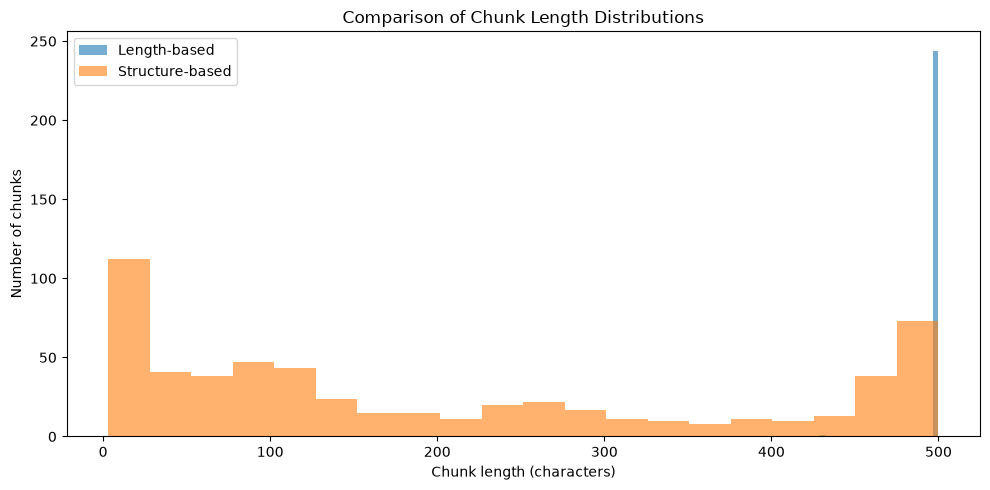

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# 각 Chunk의 글자 수 계산
length_sizes = [len(chunk) for chunk in length_chunks]
structure_sizes = [len(chunk) for chunk in structure_chunks]

# 비교 통계
df_chunk_stats = pd.DataFrame({
    "항목": ["Chunk 수", "평균 글자 수", "중앙값", "최소 글자 수", "최대 글자 수"],
    "길이 기반": [
        len(length_sizes),
        round(pd.Series(length_sizes).mean(), 1),
        pd.Series(length_sizes).median(),
        min(length_sizes),
        max(length_sizes)
    ],
    "구조 기반": [
        len(structure_sizes),
        round(pd.Series(structure_sizes).mean(), 1),
        pd.Series(structure_sizes).median(),
        min(structure_sizes),
        max(structure_sizes)
    ]
})

display(df_chunk_stats)

# 길이 분포 그래프
plt.figure(figsize=(10, 5))

plt.hist(length_sizes, bins=20, alpha=0.6, label="Length-based")
plt.hist(structure_sizes, bins=20, alpha=0.6, label="Structure-based")

plt.xlabel("Chunk length (characters)")
plt.ylabel("Number of chunks")
plt.title("Comparison of Chunk Length Distributions")
plt.legend()
plt.tight_layout()
plt.show()

#### 분석 결과 및 해석

같은 PDF 추출 데이터를 길이 기반과 구조 기반으로 나누어
Chunk 길이 분포를 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성된 Chunk | 245개 | 579개 |
| 최대 글자 수 | 500자 | 500자 |
| 분할 기준 | 글자 수 | 제목·본문·표 구조 |

길이 기반 청킹은 대부분의 Chunk가 500자에 집중되었다.

반면 구조 기반 청킹은 문서의 구조를 고려하여 나누기 때문에
Chunk 길이가 다양하게 나타났다.

특히 구조 기반 청킹에서는 짧은 Chunk가 많이 생성되었다.

이는 제목이나 표의 경계를 유지하는 대신,
일부 Chunk에 포함된 내용이 적어질 수 있음을 보여준다.

따라서 구조 기반 청킹이 문서 구조를 더 잘 유지하는지와 함께,
지나치게 짧은 Chunk가 검색에 영향을 주지는 않는지도 확인해야 한다.

※ 현재 두 방식은 Overlap 설정이 다르므로,
이번 그래프만으로 검색 성능의 우열을 판단할 수 없다.

### 7.2 짧은 Chunk 비율 비교

Chunk가 너무 짧으면 검색에 필요한 정보가
충분히 포함되지 않을 수 있다.

따라서 두 청킹 방식에서
100자 미만의 짧은 Chunk가 얼마나 생성되었는지 확인한다.

100자는 이번 실험에서 비교하기 위해 정한 기준이며,
검색에 적합한 최소 길이가 100자라는 뜻은 아니다.

In [36]:
import pandas as pd

SHORT_THRESHOLD = 100

results = []

for name, chunks in [
    ("길이 기반", length_chunks),
    ("구조 기반", structure_chunks)
]:
    sizes = [len(chunk) for chunk in chunks]

    short_count = sum(size < SHORT_THRESHOLD for size in sizes)

    results.append({
        "청킹 방식": name,
        "전체 Chunk": len(chunks),
        "100자 미만 Chunk": short_count,
        "100자 미만 비율(%)": round(
            short_count / len(chunks) * 100, 2
        ),
        "평균 글자 수": round(pd.Series(sizes).mean(), 1),
        "중앙값": pd.Series(sizes).median()
    })

df_short_chunks = pd.DataFrame(results)

display(df_short_chunks)

,청킹 방식,전체 Chunk,100자 미만 Chunk,100자 미만 비율(%),평균 글자 수,중앙값
0,길이 기반,245,0,0.0,499.7,500.0
1,구조 기반,579,231,39.9,204.8,136.0


#### 분석 결과 및 해석

길이 기반과 구조 기반 청킹에서 100자 미만의 짧은 Chunk가
얼마나 생성되었는지 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 전체 Chunk | 245개 | 579개 |
| 100자 미만 Chunk | 0개 | 231개 |
| 100자 미만 비율 | 0% | 39.9% |
| 평균 글자 수 | 499.7자 | 204.8자 |
| 중앙값 | 500자 | 136자 |

길이 기반 청킹은 대부분의 Chunk가 500자에 가까워
길이를 일정하게 유지하는 데 유리했다.

반면 구조 기반 청킹은 제목과 표의 경계를 고려했지만,
전체 Chunk의 39.9%가 100자 미만으로 생성되었다.

이는 문서 구조를 고려하는 과정에서
짧은 Chunk가 많이 만들어질 수 있음을 보여준다.

따라서 이번 실험에서는 두 방식의 장단점을 확인하였다.

- 길이 기반: 길이가 일정하지만 문서 요소 내부에서 분리될 수 있음
- 구조 기반: 구조적 경계를 고려하지만 짧은 Chunk가 많아질 수 있음

다음 단계에서는 구조 기반 Chunk가 짧아지는 원인을 확인하고,
관련 내용을 함께 묶을 수 있는지 검토한다.

※ 100자 미만을 검색에 부적합하다고 확정한 것은 아니며,
실제 검색 품질은 별도로 평가해야 한다.

### 7.3 짧은 Chunk 발생 원인 분석

구조 기반 청킹에서는 100자 미만의 짧은 Chunk가
전체의 39.9%를 차지하였다.

이러한 결과가 발생한 이유를 확인하기 위해
표에서 생성된 Chunk의 길이를 분석한다.

표는 본문과 구분하여 처리했기 때문에
짧은 표가 그대로 하나의 Chunk로 만들어졌을 가능성이 있다.

이번에는 표에서 생성된 Chunk 중
100자 미만인 경우가 얼마나 있는지 확인한다.|

In [37]:
# 표에서 만들어지는 Chunk의 길이 확인
table_chunk_sizes = []

for element in selected_elements:
    if element.get("kind") != "table":
        continue

    chunks = split_table_rows(element, CHUNK_SIZE)

    table_chunk_sizes.extend(
        len(chunk) for chunk in chunks
    )

short_table_chunks = sum(
    size < SHORT_THRESHOLD
    for size in table_chunk_sizes
)

print("표에서 생성된 Chunk:", len(table_chunk_sizes))
print("100자 미만 표 Chunk:", short_table_chunks)
print(
    "100자 미만 비율:",
    round(short_table_chunks / len(table_chunk_sizes) * 100, 2),
    "%"
)

표에서 생성된 Chunk: 272
100자 미만 표 Chunk: 71
100자 미만 비율: 26.1 %


#### 분석 결과 및 해석

구조 기반 청킹에서 생성된 짧은 Chunk의 원인을 확인하기 위해
표에서 만들어진 Chunk의 길이를 분석하였다.

| 항목 | 결과 |
|---|---:|
| 구조 기반 전체 Chunk | 579개 |
| 전체 100자 미만 Chunk | 231개 |
| 표에서 생성된 Chunk | 272개 |
| 100자 미만 표 Chunk | 71개 |
| 표 Chunk 중 100자 미만 비율 | 26.1% |

표에서 생성된 272개 Chunk 중 71개가 100자 미만이었다.

이는 짧은 표를 다른 내용과 합치지 않고
독립된 Chunk로 처리한 영향이 있을 수 있다.

다만 전체 짧은 Chunk 중 나머지 160개의 발생 원인은
아직 확인되지 않았다.

따라서 다음 단계에서는 제목과 본문에서
짧은 Chunk가 얼마나 생성되는지 확인하고,
관련 내용을 함께 묶을 수 있는지 검토한다.

### 7.4 짧은 Chunk의 발생 원인 확인

앞선 분석에서 표에서 생성된 짧은 Chunk는 71개였다.

이번에는 나머지 짧은 Chunk가
어떤 문서 요소에서 생성되었는지 확인한다.

특히 제목과 본문을 나누는 과정에서
짧은 Chunk가 발생했는지 살펴본다.

이 결과를 바탕으로 구조 기반 청킹의 개선 방향을 결정한다.

In [39]:
from collections import Counter

# 표를 제외한 Element만 대상으로 동일한 청킹 함수 실행
non_table_elements = [
    element
    for element in selected_elements
    if element.get("kind") != "table"
]

non_table_chunks = structural_chunking(
    non_table_elements,
    CHUNK_SIZE
)

short_non_table = sum(
    len(chunk) < SHORT_THRESHOLD
    for chunk in non_table_chunks
)

print("표 제외 Chunk 수:", len(non_table_chunks))
print("표 제외 100자 미만 Chunk:", short_non_table)
print(
    "표 제외 100자 미만 비율:",
    round(short_non_table / len(non_table_chunks) * 100, 2),
    "%"
)


표 제외 Chunk 수: 227
표 제외 100자 미만 Chunk: 94
표 제외 100자 미만 비율: 41.41 %


#### 분석 결과 및 해석

짧은 Chunk가 표 때문에 발생하는지 확인하기 위해
표를 제외한 데이터로 구조 기반 청킹을 다시 실행하였다.

| 항목 | 결과 |
|---|---:|
| 생성된 Chunk | 227개 |
| 100자 미만 Chunk | 94개 |
| 100자 미만 비율 | 41.41% |

표를 제외한 후에도 전체 Chunk의 41.41%가
100자 미만으로 생성되었다.

이는 짧은 Chunk가 발생하는 원인이
표 처리에만 있는 것은 아니라는 뜻이다.

제목을 기준으로 나누는 방식이나
본문을 묶는 과정에서도 짧은 Chunk가 발생할 가능성이 있다.

다만 표를 제외하면서 Chunk 구성도 달라졌으므로,
기존 결과와 직접 비교해 원인을 확정할 수는 없다.

다음 단계에서는 기존 구조 기반 청킹 결과를 그대로 유지하고,
각 Chunk가 어떤 이유로 생성되었는지 확인한다.

### 7.5 제목으로 인해 생성되는 짧은 Chunk 확인

구조 기반 청킹에서는 제목이 등장하면
새로운 Chunk를 시작하도록 설정하였다.

이 과정에서 제목만 포함된 짧은 Chunk가
생성될 가능성이 있다.

이번에는 제목 요소의 길이를 확인하여
짧은 Chunk가 발생하는 원인을 살펴본다.

In [40]:
import pandas as pd

# 제목 Element만 선택
heading_elements = [
    element for element in selected_elements
    if element.get("kind") == "heading"
]

# 제목의 글자 수 확인
heading_lengths = [
    len(element.get("search_text") or "")
    for element in heading_elements
]

short_headings = sum(
    length < SHORT_THRESHOLD
    for length in heading_lengths
)

print("전체 제목 Element:", len(heading_elements))
print("100자 미만 제목 Element:", short_headings)

print("\n제목 길이 통계:")
display(pd.Series(heading_lengths).describe().round(1))


전체 제목 Element: 148
100자 미만 제목 Element: 148

제목 길이 통계:


count    148.0
mean      20.2
std       12.2
min        5.0
25%       10.0
50%       16.0
75%       33.0
max       41.0
dtype: float64

#### 분석 결과 및 해석

전체 제목 Element 148개의 길이를 확인하였다.

| 항목 | 결과 |
|---|---:|
| 전체 제목 | 148개 |
| 100자 미만 제목 | 148개 |
| 평균 길이 | 20.2자 |
| 중앙값 | 16자 |
| 최소 길이 | 5자 |
| 최대 길이 | 41자 |

모든 제목이 100자 미만으로 확인되었다.

현재 구조 기반 청킹은 제목이 등장할 때
새로운 Chunk를 시작하도록 설정되어 있다.

따라서 제목 뒤에 충분한 본문이 연결되지 않으면
짧은 Chunk가 생성될 가능성이 있다.

다만 제목이 짧다고 해서
제목만 포함된 Chunk가 반드시 생성되는 것은 아니다.

다음 단계에서는 실제 제목과 본문이
얼마나 함께 묶였는지 확인하고,
짧은 Chunk를 줄일 수 있는 방법을 검토한다.

### 7.6 제목만 포함된 Chunk 확인

앞선 분석에서 모든 제목이 100자 미만이라는 것을 확인했다.

이번에는 실제 생성된 Chunk 중
제목만 들어 있는 Chunk가 얼마나 있는지 확인한다.

제목과 본문이 따로 나뉘면
검색할 때 필요한 설명이 부족할 수 있기 때문이다.

원문과 파일명은 출력하지 않는다.

In [41]:
# 제목 텍스트 목록
heading_texts = {
    (element.get("search_text") or "").strip()
    for element in selected_elements
    if element.get("kind") == "heading"
}

heading_texts.discard("")

# 제목 텍스트와 정확히 같은 Chunk 확인
heading_only_chunks = [
    chunk
    for chunk in structure_chunks
    if chunk.strip() in heading_texts
]

print("전체 구조 기반 Chunk:", len(structure_chunks))
print("제목 텍스트와 일치하는 Chunk:", len(heading_only_chunks))
print(
    "전체 Chunk 중 비율:",
    round(len(heading_only_chunks) / len(structure_chunks) * 100, 2),
    "%"
)

전체 구조 기반 Chunk: 579
제목 텍스트와 일치하는 Chunk: 57
전체 Chunk 중 비율: 9.84 %


#### 분석 결과 및 해석

구조 기반 청킹으로 생성한 579개 Chunk 중
제목 텍스트와 정확히 일치하는 Chunk는 57개였다.

| 항목 | 결과 |
|---|---:|
| 전체 구조 기반 Chunk | 579개 |
| 제목 텍스트와 일치하는 Chunk | 57개 |
| 전체 Chunk 중 비율 | 9.84% |

제목만 포함된 것으로 보이는 Chunk가 일부 확인되었다.

이런 Chunk는 제목은 알 수 있지만
관련 설명이 부족해 검색에 불리할 가능성이 있다.

따라서 제목을 독립적으로 저장하기보다,
관련 본문과 함께 묶는 방법을 검토할 필요가 있다.

다만 현재 결과는 텍스트가 일치하는지를 확인한 것이므로,
모든 Chunk의 실제 생성 원인을 확정한 것은 아니다.

### 7.7 제목과 다음 요소의 관계 확인

앞선 분석에서 제목만 포함된 것으로 보이는 Chunk가 발견되었다.

제목을 관련 내용과 묶으려면
제목 다음에 어떤 종류의 내용이 나오는지 알아야 한다.

따라서 제목 다음에 등장하는 Element가
본문인지, 표인지, 다른 제목인지 확인한다.

이를 바탕으로 제목과 본문을 함께 묶는 방법을 결정한다.

In [42]:
from collections import Counter
import pandas as pd

next_kind_counts = Counter()

for i, element in enumerate(selected_elements[:-1]):
    if element.get("kind") != "heading":
        continue

    next_element = selected_elements[i + 1]
    next_kind = next_element.get("kind", "unknown")

    next_kind_counts[next_kind] += 1

df_next_kind = pd.DataFrame(
    [
        {"다음 Element 종류": kind, "개수": count}
        for kind, count in next_kind_counts.items()
    ]
)

df_next_kind["비율(%)"] = (
    df_next_kind["개수"]
    / df_next_kind["개수"].sum()
    * 100
).round(2)

display(
    df_next_kind.sort_values("개수", ascending=False)
)

,다음 Element 종류,개수,비율(%)
2,paragraph,91,61.49
1,heading,39,26.35
3,table,12,8.11
0,toc,6,4.05


#### 분석 결과 및 해석

전체 제목 Element 148개를 대상으로
바로 다음에 등장하는 Element의 종류를 확인하였다.

| 다음 Element | 개수 | 비율 |
|---|---:|---:|
| 본문 | 91개 | 61.49% |
| 제목 | 39개 | 26.35% |
| 표 | 12개 | 8.11% |
| 목차 | 6개 | 4.05% |

제목 다음에 본문이 나오는 경우가 61.49%로 가장 많았다.

따라서 제목을 별도 Chunk로 만들기보다
관련 본문과 함께 묶는 방법을 검토할 수 있다.

하지만 제목 다음에 다른 제목이 나오는 경우도 있어
모든 제목을 무조건 합치는 것은 적절하지 않다.

이번 분석은 Element의 등장 순서를 확인한 결과이며,
실제 제목과 본문의 소속 관계를 검증한 것은 아니다.

다음 단계에서는 제목과 본문을 함께 묶되,
문서의 구조적 경계를 유지하는 개선 방법을 실험한다.

### 7.8 제목과 본문의 소속 관계 확인

앞선 분석에서 제목 다음에 본문이 나오는 경우가
91개(61.49%)로 가장 많았다.

하지만 제목 다음에 본문이 나온다고 해서
반드시 같은 내용에 속하는 것은 아니다.

따라서 `section_path`를 이용해
제목과 다음 본문이 같은 구역에 속하는지 확인한다.

이 결과를 바탕으로 제목과 본문을 안전하게 묶는
개선형 구조 기반 청킹을 설계한다.

In [43]:
from collections import Counter
import pandas as pd

section_checks = Counter()

for i, element in enumerate(selected_elements[:-1]):
    if element.get("kind") != "heading":
        continue

    next_element = selected_elements[i + 1]

    # 제목 다음에 본문이 나오는 경우만 확인
    if next_element.get("kind") != "paragraph":
        continue

    heading_path = (element.get("location") or {}).get("section_path")
    paragraph_path = (next_element.get("location") or {}).get("section_path")

    # 제목과 본문의 구역 정보 비교
    if not heading_path or not paragraph_path:
        section_checks["경로 정보 부족"] += 1
    elif heading_path == paragraph_path:
        section_checks["경로 일치"] += 1
    elif (
        len(paragraph_path) > len(heading_path)
        and paragraph_path[:len(heading_path)] == heading_path
    ):
        section_checks["본문이 하위 경로"] += 1
    else:
        section_checks["경로 불일치"] += 1

df_section_checks = pd.DataFrame(
    section_checks.items(),
    columns=["확인 결과", "개수"]
)

display(df_section_checks)

print("확인한 제목-본문 연결:", sum(section_checks.values()))

,확인 결과,개수
0,경로 일치,91


확인한 제목-본문 연결: 91


#### 분석 결과 및 해석

제목 다음에 본문이 나오는 91개 사례의
`section_path`를 비교하였다.

그 결과 91개 모두 제목과 본문의 경로가 일치하였다.

| 확인 항목 | 결과 |
|---|---:|
| 확인한 제목·본문 연결 | 91개 |
| 경로 일치 | 91개 |
| 경로 불일치 | 0개 |

이는 제목과 바로 뒤에 나오는 본문을
같은 구역의 내용으로 묶어볼 수 있다는 근거가 된다.

따라서 다음 실험에서는 같은 구역에 속한
제목과 본문을 가능한 한 하나의 Chunk로 구성한다.

다만 경로가 같다는 사실만으로
모든 내용의 소속이 정확하다고 확정할 수는 없다.

### 7.9 개선형 구조 기반 청킹

기존 구조 기반 청킹에서는
전체 579개 Chunk 중 231개(39.9%)가 100자 미만이었다.

이번에는 제목과 본문을 함께 묶는 방법으로
짧은 Chunk를 줄일 수 있는지 확인한다.

같은 `section_path`를 가진 제목과 본문을 대상으로 하며,
기존 500자 제한은 유지한다.

표는 기존 행 단위 청킹 방식을 그대로 사용하여
제목·본문 연결 개선의 효과를 먼저 확인한다.

In [44]:
def _can_join_section(current, current_path, text, path, size):
    """같은 구역과 기존 길이 조건을 함께 확인한다."""
    return bool(current and current_path == path and len(current) + 1 + len(text) <= size)


def _start_section_chunk(chunks, text, path, size):
    """기존 구역 시작 처리를 분리한다."""
    if len(text) <= size:
        return text, path
    chunks.extend(split_long_text(text, size))
    return "", None


def improved_structural_chunking(elements, size=500):
    """같은 구역의 제목과 본문을 가능한 한 묶는 개선형 청킹"""
    chunks = []
    current = ""
    current_path = None

    def flush():
        nonlocal current, current_path

        if current:
            chunks.append(current)

        current = ""
        current_path = None

    for element in elements:
        kind = element.get("kind", "unknown")
        text = element.get("search_text") or ""
        path = (element.get("location") or {}).get("section_path")

        if not text.strip():
            continue

        # 표는 기존 방식 유지
        if kind == "table":
            flush()
            chunks.extend(split_table_rows(element, size))
            continue

        # 제목은 기존 내용을 마무리하고 새 구역 시작
        if kind in {"heading", "toc"}:
            flush()

            current, current_path = _start_section_chunk(chunks, text, path, size)

            continue

        # 같은 구역의 본문은 이어 붙이기
        if _can_join_section(current, current_path, text, path, size):
            current += "\n" + text
            continue

        # 다른 구역이거나 길이 제한을 넘으면 새 Chunk
        flush()

        current, current_path = _start_section_chunk(chunks, text, path, size)

    flush()
    return chunks


improved_chunks = improved_structural_chunking(
    selected_elements,
    CHUNK_SIZE
)

short_improved = sum(
    len(chunk) < SHORT_THRESHOLD
    for chunk in improved_chunks
)

print("기존 구조 기반 Chunk:", len(structure_chunks))
print("개선 구조 기반 Chunk:", len(improved_chunks))

print("\n기존 100자 미만 Chunk:", sum(
    len(chunk) < SHORT_THRESHOLD
    for chunk in structure_chunks
))

print("개선 100자 미만 Chunk:", short_improved)

print(
    "개선 후 100자 미만 비율:",
    round(short_improved / len(improved_chunks) * 100, 2),
    "%"
)

print(
    "500자 초과 Chunk:",
    sum(len(chunk) > CHUNK_SIZE for chunk in improved_chunks)
)

기존 구조 기반 Chunk: 579
개선 구조 기반 Chunk: 579

기존 100자 미만 Chunk: 231
개선 100자 미만 Chunk: 231
개선 후 100자 미만 비율: 39.9 %
500자 초과 Chunk: 0


#### 분석 결과 및 해석

기존 구조 기반 청킹과
`section_path`를 추가로 고려한 개선형 청킹을 비교하였다.

| 항목 | 기존 구조 기반 | 개선형 구조 기반 |
|---|---:|---:|
| 전체 Chunk | 579개 | 579개 |
| 100자 미만 Chunk | 231개 | 231개 |
| 짧은 Chunk 비율 | 39.9% | 39.9% |

실험 결과, 두 방식의 Chunk 개수와
짧은 Chunk 비율에 차이가 없었다.

이는 기존 방식에서도 제목과 바로 뒤의 본문을
일정 길이 안에서 함께 묶고 있었기 때문일 가능성이 있다.

따라서 이번에 추가한 `section_path` 조건만으로는
짧은 Chunk 문제를 개선하지 못했다.

다만 Chunk의 개수가 같더라도
실제 내용과 분할 위치는 달라질 수 있으므로
추가 비교가 필요하다.

### 7.10 개선 전후 Chunk 일치 여부 확인

기존 구조 기반과 개선형 구조 기반에서
동일한 개수의 Chunk가 생성되었다.

하지만 개수가 같아도 실제 분할 위치나
Chunk 내용은 다를 수 있다.

따라서 두 결과를 순서대로 비교하여
실제로 달라진 Chunk가 있는지 확인한다.

In [45]:
# 기존 구조 기반과 개선형의 결과 비교

same_chunks = sum(
    old == new
    for old, new in zip(structure_chunks, improved_chunks)
)

different_chunks = sum(
    old != new
    for old, new in zip(structure_chunks, improved_chunks)
)

print("기존 Chunk 수:", len(structure_chunks))
print("개선형 Chunk 수:", len(improved_chunks))
print("같은 위치에서 내용이 일치한 Chunk:", same_chunks)
print("같은 위치에서 내용이 다른 Chunk:", different_chunks)
print("전체 Chunk 목록 완전 일치:", structure_chunks == improved_chunks)

기존 Chunk 수: 579
개선형 Chunk 수: 579
같은 위치에서 내용이 일치한 Chunk: 579
같은 위치에서 내용이 다른 Chunk: 0
전체 Chunk 목록 완전 일치: True


#### 분석 결과 및 해석

기존 구조 기반 청킹과 `section_path`를 추가한
개선형 청킹의 결과를 비교하였다.

| 비교 항목 | 결과 |
|---|---:|
| 기존 Chunk | 579개 |
| 개선형 Chunk | 579개 |
| 내용과 순서가 일치한 Chunk | 579개 |
| 내용이 다른 Chunk | 0개 |

두 방식의 Chunk 내용과 순서가 모두 동일하였다.

이는 이번에 추가한 `section_path` 조건이
현재 실험 데이터의 청킹 결과를 바꾸지 않았다는 뜻이다.

따라서 이 방법으로는 짧은 Chunk 문제를 개선하지 못했다.

다음에는 기존 구조 기반 청킹을 유지하면서
짧은 표와 주변 내용을 함께 묶는 방법을 검토한다.


### 7.11 짧은 표와 주변 내용의 관계 확인

기존 구조 기반 청킹에서는
표를 본문과 구분하여 별도의 Chunk로 만들었다.

이 때문에 짧은 표도 독립된 Chunk가 될 수 있다.

이번에는 100자 미만의 짧은 표가
바로 앞의 내용과 같은 구역에 속하는지 확인한다.

이를 통해 관련 내용을 안전하게 묶을 수 있는지 살펴본다.

In [46]:
from collections import Counter
import pandas as pd

short_table_checks = Counter()

for i, element in enumerate(selected_elements):
    if element.get("kind") != "table":
        continue

    # 표에서 생성된 Chunk가 100자 미만인 경우
    table_parts = split_table_rows(element, CHUNK_SIZE)

    if not any(len(part) < SHORT_THRESHOLD for part in table_parts):
        continue

    short_table_checks["짧은 Chunk가 포함된 표"] += 1

    if i == 0:
        short_table_checks["앞 요소 없음"] += 1
        continue

    previous = selected_elements[i - 1]

    table_path = (element.get("location") or {}).get("section_path")
    previous_path = (previous.get("location") or {}).get("section_path")

    if not table_path or not previous_path:
        short_table_checks["경로 정보 부족"] += 1

    elif table_path == previous_path:
        short_table_checks["앞 요소와 경로 일치"] += 1

    else:
        short_table_checks["앞 요소와 경로 불일치"] += 1

    short_table_checks[
        f"앞 요소 종류: {previous.get('kind', 'unknown')}"
    ] += 1

print("짧은 Chunk가 포함된 표:", short_table_checks["짧은 Chunk가 포함된 표"])

display(
    pd.DataFrame(
        short_table_checks.items(),
        columns=["확인 항목", "개수"]
    )
)

짧은 Chunk가 포함된 표: 68


,확인 항목,개수
0,짧은 Chunk가 포함된 표,68
1,경로 정보 부족,2
2,앞 요소 종류: paragraph,33
3,앞 요소와 경로 일치,66
4,앞 요소 종류: table,35


#### 분석 결과 및 해석

짧은 Chunk가 포함된 표 68개를 대상으로
바로 앞 Element와의 관계를 확인하였다.

| 확인 항목 | 결과 |
|---|---:|
| 짧은 Chunk가 포함된 표 | 68개 |
| 앞 요소와 경로 일치 | 66개 |
| 경로 정보 부족 | 2개 |
| 앞 요소가 본문 | 33개 |
| 앞 요소가 표 | 35개 |

68개 표 중 66개가 바로 앞 Element와 같은 제목 경로를 가지고 있었다.

이는 짧은 표를 주변 내용과 함께 묶는 방법을
검토할 수 있다는 뜻이다.

하지만 같은 제목 경로라고 해서
반드시 같은 요구사항에 속하는 것은 아니다.

따라서 다음 실험에서는 제목 경로뿐 아니라
요구사항 경계와 길이 제한도 함께 확인한다.

### 7.12 짧은 표 병합 가능성 확인

앞선 분석에서 짧은 표 68개 중 66개가
바로 앞 Element와 같은 제목 경로를 가진 것을 확인하였다.

이번에는 두 Element를 합쳤을 때
500자 제한을 지킬 수 있는지 확인한다.

이를 통해 짧은 Chunk를 줄일 수 있는
후보가 얼마나 있는지 살펴본다.

단, 길이와 제목 경로가 같다는 사실만으로
실제 병합이 가능한 것은 아니다.

In [47]:
from collections import Counter
import pandas as pd

merge_checks = Counter()

for i, element in enumerate(selected_elements):
    if element.get("kind") != "table" or i == 0:
        continue

    table_parts = split_table_rows(element, CHUNK_SIZE)

    # 짧은 Chunk가 포함된 표만 확인
    if not any(len(part) < SHORT_THRESHOLD for part in table_parts):
        continue

    previous = selected_elements[i - 1]

    table_path = (element.get("location") or {}).get("section_path")
    previous_path = (previous.get("location") or {}).get("section_path")

    if not table_path or not previous_path:
        merge_checks["경로 정보 부족"] += 1
        continue

    if table_path != previous_path:
        merge_checks["경로 불일치"] += 1
        continue

    previous_text = previous.get("search_text") or ""

    # 표가 여러 Chunk로 나뉜 경우는 우선 제외
    if len(table_parts) != 1:
        merge_checks["표가 여러 Chunk로 분리됨"] += 1
        continue

    combined_length = len(previous_text) + 1 + len(table_parts[0])

    if combined_length <= CHUNK_SIZE:
        merge_checks["길이 조건 충족"] += 1
    else:
        merge_checks["500자 초과"] += 1

display(
    pd.DataFrame(
        merge_checks.items(),
        columns=["확인 결과", "개수"]
    )
)

print("검토한 표:", sum(merge_checks.values()))

,확인 결과,개수
0,경로 정보 부족,2
1,길이 조건 충족,32
2,표가 여러 Chunk로 분리됨,28
3,500자 초과,6


검토한 표: 68


#### 분석 결과 및 해석

짧은 Chunk가 포함된 표 68개를 대상으로
바로 앞 Element와 합칠 수 있는지 확인하였다.

| 확인 결과 | 표 개수 |
|---|---:|
| 길이 조건 충족 | 32개 |
| 표가 여러 Chunk로 분리됨 | 28개 |
| 500자 초과 | 6개 |
| 경로 정보 부족 | 2개 |
| **전체** | **68개** |

68개 표 중 32개는 바로 앞 Element와 제목 경로가 같고,
두 내용을 합쳐도 500자를 넘지 않았다.

이는 짧은 Chunk를 줄일 수 있는 후보가 있다는 뜻이다.

하지만 제목 경로와 길이만으로
실제로 같은 요구사항에 속하는지는 알 수 없다.

따라서 바로 합치지 않고,
요구사항 ID와 문서 구조를 추가로 확인한 후
안전하게 묶을 수 있는지 판단한다.

### 7.13 요구사항 ID 충돌 확인

앞선 분석에서 32개 표가
길이와 제목 경로 조건을 충족하였다.

하지만 서로 다른 요구사항을 하나의 Chunk에 합치면
검색할 때 잘못된 문맥이 전달될 수 있다.

따라서 두 Element에 요구사항 ID가 있는지 확인하고,
서로 다른 ID가 나타나는 경우를 구분한다.

원문 내용과 실제 요구사항 ID는 출력하지 않는다.

In [48]:
import re
from collections import Counter
import pandas as pd

# RFP 요구사항 ID 패턴
REQ_PATTERN = re.compile(r"\b([A-Z]{2,6})\s*[-－]\s*(\d{1,4})\b")

def extract_requirement_ids(text):
    """텍스트에서 요구사항 ID를 추출하고 표기를 통일한다."""
    return {
        f"{prefix}-{number}"
        for prefix, number in REQ_PATTERN.findall(text or "")
    }

requirement_checks = Counter()
merge_candidates = []

for i, element in enumerate(selected_elements):
    if element.get("kind") != "table" or i == 0:
        continue

    table_parts = split_table_rows(element, CHUNK_SIZE)

    if not any(len(part) < SHORT_THRESHOLD for part in table_parts):
        continue

    previous = selected_elements[i - 1]

    table_path = (element.get("location") or {}).get("section_path")
    previous_path = (previous.get("location") or {}).get("section_path")

    if not table_path or table_path != previous_path:
        continue

    if len(table_parts) != 1:
        continue

    previous_text = previous.get("search_text") or ""
    table_text = table_parts[0]

    if len(previous_text) + 1 + len(table_text) > CHUNK_SIZE:
        continue

    previous_ids = extract_requirement_ids(previous_text)
    table_ids = extract_requirement_ids(table_text)

    if previous_ids and table_ids:
        if previous_ids == table_ids:
            status = "ID 일치"
        else:
            status = "ID 충돌 가능성"
    else:
        status = "ID 비교 불가"

    requirement_checks[status] += 1

    merge_candidates.append({
        "index": i,
        "status": status
    })

display(pd.DataFrame(
    requirement_checks.items(),
    columns=["확인 결과", "개수"]
))

print("확인한 병합 후보:", len(merge_candidates))

,확인 결과,개수
0,ID 비교 불가,31
1,ID 일치,1


확인한 병합 후보: 32


### 7.14 청킹 방식 비교 및 중간 결론

이번 실험에서는 길이 기반과 구조 기반 청킹을
동일한 PDF 추출 데이터에 적용하였다.

길이 기반 청킹은 Chunk 길이를 일정하게 유지했지만,
전체 244개 경계 중 236개가 Element 내부에 위치했다.

반면 구조 기반 청킹은 제목과 표의 구조를 고려했지만,
전체 579개 Chunk 중 231개(39.9%)가 100자 미만이었다.

짧은 Chunk를 줄이기 위해
제목과 본문의 연결, 짧은 표의 병합 가능성을 검토하였다.

그러나 제목 경로를 추가한 개선안은 기존 결과와 같았고,
짧은 표의 병합 후보 32개 중 31개는
요구사항 ID만으로 소속을 확인할 수 없었다.

따라서 현재 단계에서는
짧은 Chunk를 무조건 합치는 방식보다
문서의 구조와 요구사항 경계를 유지하는 방향을 우선한다.

**중간 결론**

RFP 문서에서는 길이뿐 아니라
제목, 표, 요구사항의 관계를 고려하는 청킹이 필요하다.

다만 구조 기반 청킹에서도 짧은 Chunk가 발생하므로,
실제 검색 성능과 문맥 유지 여부를 추가 검증해야 한다.

현재 결과만으로 두 방식의 검색 성능 우열을 확정할 수는 없다.

## 8. 요구사항 ID와 문맥 유지 비교

### 8.1 분석 목적

RFP 문서에는 SFR-001과 같은 요구사항 ID가 포함되어 있다.

요구사항 ID는 해당 내용이 어떤 요구사항에 속하는지
구분하는 데 중요한 역할을 한다.

하지만 문서를 일정한 길이로 나누면
요구사항 ID와 관련 설명이 서로 다른 Chunk에 들어갈 수 있다.

이번에는 두 청킹 방식에서 요구사항 ID가
어떻게 나뉘는지 비교한다.

단, ID가 포함되어 있다고 해서
해당 Chunk의 요구사항 소속이 정확한 것은 아니다.

### 8.2 청킹 방식별 요구사항 ID 분포


In [49]:
import re
import pandas as pd

# 요구사항 ID 찾기
REQ_PATTERN = re.compile(
    r"\b[A-Z]{2,6}\s*[-－]\s*\d{1,4}\b"
)

def find_requirement_ids(text):
    """텍스트에서 요구사항 ID를 찾는다."""
    return REQ_PATTERN.findall(text or "")


def analyze_chunk_ids(chunks, method):
    """청킹 방식별 요구사항 ID 현황을 분석한다."""

    chunk_with_id = 0
    total_id_count = 0
    multiple_id_chunks = 0

    for chunk in chunks:
        ids = find_requirement_ids(chunk)

        if ids:
            chunk_with_id += 1

        total_id_count += len(ids)

        # 서로 다른 요구사항 ID가 2개 이상 있는 Chunk
        if len(set(ids)) >= 2:
            multiple_id_chunks += 1

    return {
        "청킹 방식": method,
        "전체 Chunk": len(chunks),
        "ID 포함 Chunk": chunk_with_id,
        "ID 없는 Chunk": len(chunks) - chunk_with_id,
        "ID 등장 횟수": total_id_count,
        "서로 다른 ID 2개 이상 Chunk": multiple_id_chunks
    }


results = [
    analyze_chunk_ids(length_chunks, "길이 기반"),
    analyze_chunk_ids(structure_chunks, "구조 기반")
]

df_requirement_compare = pd.DataFrame(results)

display(df_requirement_compare)

,청킹 방식,전체 Chunk,ID 포함 Chunk,ID 없는 Chunk,ID 등장 횟수,서로 다른 ID 2개 이상 Chunk
0,길이 기반,245,50,195,116,13
1,구조 기반,579,59,520,103,6


#### 분석 결과 및 해석

두 청킹 방식에서 요구사항 ID의 분포를 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 전체 Chunk | 245개 | 579개 |
| ID 포함 Chunk | 50개 | 59개 |
| ID 없는 Chunk | 195개 | 520개 |
| ID 등장 횟수 | 116회 | 103회 |
| 서로 다른 ID가 2개 이상 포함된 Chunk | 13개 | 6개 |

구조 기반 청킹에서는 서로 다른 요구사항 ID가
하나의 Chunk에 함께 포함된 경우가 더 적었다.

하지만 구조 기반은 Chunk 수가 더 많고,
길이 기반에는 50자 Overlap이 적용되어 있다.

따라서 ID의 등장 횟수나 Chunk 개수만으로
구조 기반이 더 정확하다고 판단할 수는 없다.

다음 단계에서는 원래 데이터의 요구사항 ID가
청킹 결과에도 빠짐없이 전달되었는지 확인한다.

### 8.3 요구사항 ID 전달 여부 확인

앞선 분석에서는 두 청킹 방식에서
요구사항 ID가 등장하는 횟수에 차이가 있었다.

이번에는 원래 데이터에 있는 요구사항 ID가
청킹 결과에도 빠짐없이 포함되었는지 확인한다.

길이 기반 청킹은 내용이 겹치는 부분(Overlap)이 있어
같은 ID가 반복될 수 있다.

따라서 단순한 등장 횟수 대신
서로 다른 요구사항 ID의 종류를 비교한다.

이를 통해 청킹 과정에서
요구사항 ID가 누락되었는지 확인한다.

In [50]:
# 1. 청킹 전 원본 텍스트의 요구사항 ID
original_ids = set(find_requirement_ids(full_text))

# 2. 길이 기반 Chunk에 포함된 요구사항 ID
length_ids = set()

for chunk in length_chunks:
    length_ids.update(find_requirement_ids(chunk))

# 3. 구조 기반 Chunk에 포함된 요구사항 ID
structure_ids = set()

for chunk in structure_chunks:
    structure_ids.update(find_requirement_ids(chunk))

# 4. 원본과 비교하여 누락된 ID 확인
length_missing = original_ids - length_ids
structure_missing = original_ids - structure_ids

# 5. 결과 출력 (실제 요구사항 ID는 출력하지 않음)
print("원본의 서로 다른 요구사항 ID:", len(original_ids))

print("\n[길이 기반]")
print("확인된 ID 종류:", len(length_ids))
print("누락된 ID 종류:", len(length_missing))

print("\n[구조 기반]")
print("확인된 ID 종류:", len(structure_ids))
print("누락된 ID 종류:", len(structure_missing))

# 6. 비교표
df_id_preservation = pd.DataFrame([
    {
        "청킹 방식": "길이 기반",
        "확인된 ID 종류": len(length_ids),
        "누락된 ID 종류": len(length_missing)
    },
    {
        "청킹 방식": "구조 기반",
        "확인된 ID 종류": len(structure_ids),
        "누락된 ID 종류": len(structure_missing)
    }
])

display(df_id_preservation)

원본의 서로 다른 요구사항 ID: 46

[길이 기반]
확인된 ID 종류: 46
누락된 ID 종류: 0

[구조 기반]
확인된 ID 종류: 46
누락된 ID 종류: 2


,청킹 방식,확인된 ID 종류,누락된 ID 종류
0,길이 기반,46,0
1,구조 기반,46,2


#### 분석 결과 및 해석

원본 데이터와 두 청킹 결과에 포함된 요구사항 ID를 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 원본 요구사항 ID | 46종 | 46종 |
| 누락된 ID | 0종 | 2종 |

길이 기반 청킹에서는 원본에 있던 요구사항 ID가 모두 확인되었다.

반면 구조 기반 청킹에서는 원본 대비 2종의 ID가 확인되지 않았다.

또한 구조 기반 결과에서 확인된 ID 종류는 46종으로
원본과 같으므로, 연결 입력의 정규식 ID 집합에 없던 ID가 새롭게 나타났을 가능성도 있다.

따라서 현재 단계에서는 구조 기반 청킹의
요구사항 ID 전달이 완전히 검증됐다고 볼 수 없다.

다음 단계에서는 누락된 ID와 새롭게 등장한 ID의 원인을 확인한다.

### 8.3.1 요구사항 ID 차이 원인 확인

구조 기반 청킹 결과에서
원본에 존재하던 요구사항 ID 2종이 확인되지 않았다.

반대로 연결 입력의 정규식 ID 집합에는 없던 ID가
새롭게 나타났는지도 확인할 필요가 있다.

이번에는 ID가 등장하는 위치와 Element 종류를 살펴보고,
차이가 발생한 원인을 분석한다.

원문과 실제 요구사항 ID는 출력하지 않는다.

In [51]:
from collections import Counter
import pandas as pd

# 원본에는 있지만 구조 기반 결과에 없는 ID
missing_ids = original_ids - structure_ids

# 구조 기반 결과에만 새롭게 등장한 ID
added_ids = structure_ids - original_ids

print("구조 기반에서 누락된 ID 종류:", len(missing_ids))
print("구조 기반에서 새롭게 등장한 ID 종류:", len(added_ids))

# 원본에서 누락된 ID가 등장하는 Element 종류 확인
missing_kind_counts = Counter()

for element in selected_elements:
    element_ids = set(
        find_requirement_ids(element.get("search_text") or "")
    )

    if element_ids & missing_ids:
        missing_kind_counts[element.get("kind", "unknown")] += 1

print("\n누락된 ID가 원본에서 등장한 Element 종류:")

display(
    pd.DataFrame(
        missing_kind_counts.items(),
        columns=["Element 종류", "ID 등장 Element 수"]
    )
)

구조 기반에서 누락된 ID 종류: 2
구조 기반에서 새롭게 등장한 ID 종류: 2

누락된 ID가 원본에서 등장한 Element 종류:


,Element 종류,ID 등장 Element 수
0,table,1


#### 분석 결과 및 해석

구조 기반 청킹에서 원본과 다르게 나타난
요구사항 ID의 위치를 확인하였다.

| 확인 항목 | 결과 |
|---|---:|
| 원본 대비 누락된 ID | 2종 |
| 새롭게 등장한 ID | 2종 |
| 누락된 ID가 발견된 Element | 표 1개 |

누락된 ID는 표 Element에서 발견되었다.

현재 구조 기반 청킹은 표의 셀 정보를 다시 조합하여
Chunk를 생성하므로, 이 과정에서 ID의 표현이
달라졌을 가능성이 있다.

다만 실제로 ID가 삭제되거나 변경된 것인지,
표현 방식 때문에 다르게 인식된 것인지는 아직 확인되지 않았다.

따라서 다음 단계에서는 해당 표의 원래 텍스트와
재구성한 텍스트를 비교하여 원인을 확인한다.

### 8.3.2 요구사항 ID 차이 원인 분석

앞선 분석에서 요구사항 ID 차이가
표 Element에서 발생했을 가능성을 확인하였다.

이번에는 해당 표의 원래 검색용 텍스트와
셀을 다시 조합한 텍스트를 비교한다.

이를 통해 ID가 실제로 사라졌는지,
아니면 표의 표현 방식 때문에 다르게 인식되었는지 확인한다.

원문과 실제 요구사항 ID는 출력하지 않는다.

In [53]:
# 누락된 ID가 들어 있는 표 찾기
problem_tables = []

for element in selected_elements:
    if element.get("kind") != "table":
        continue

    original_text = element.get("search_text") or ""
    original_table_ids = set(find_requirement_ids(original_text))

    if original_table_ids & missing_ids:
        problem_tables.append(element)

print("확인할 표:", len(problem_tables))

# 표별 요구사항 ID 비교
comparison_results = []

for element in problem_tables:
    original_text = element.get("search_text") or ""

    # 구조 기반 청킹에서 사용한 방식
    reconstructed_text = "".join(
        split_table_rows(element, CHUNK_SIZE)
    )

    original_table_ids = set(find_requirement_ids(original_text))
    reconstructed_ids = set(find_requirement_ids(reconstructed_text))

    # 공백과 표 구분 기호를 제외한 실제 문자 비교
    original_normalized = normalize_table_content(original_text)
    reconstructed_normalized = normalize_table_content(reconstructed_text)

    comparison_results.append({
        "원본 ID 종류": len(original_table_ids),
        "재구성 ID 종류": len(reconstructed_ids),
        "표 안에서 누락된 ID": len(original_table_ids - reconstructed_ids),
        "표 안에서 새로 생긴 ID": len(reconstructed_ids - original_table_ids),
        "구분 기호 제외 문자 일치": (
            original_normalized == reconstructed_normalized
        )
    })

display(pd.DataFrame(comparison_results))

확인할 표: 1


,원본 ID 종류,재구성 ID 종류,표 안에서 누락된 ID,표 안에서 새로 생긴 ID,구분 기호 제외 문자 일치
0,2,2,2,2,True


#### 분석 결과 및 해석

요구사항 ID 차이가 발견된 표 1개의
원래 검색용 텍스트와 재구성된 텍스트를 비교하였다.

| 확인 항목 | 결과 |
|---|---:|
| 확인한 표 | 1개 |
| 원래 ID 종류 | 2종 |
| 재구성된 ID 종류 | 2종 |
| 누락된 ID 종류 | 2종 |
| 새롭게 등장한 ID 종류 | 2종 |
| 공백·구분 기호 제외 문자 일치 | True |

공백과 표 구분 기호를 제외했을 때
원래 텍스트와 재구성된 텍스트가 일치하였다.

그러나 요구사항 ID의 추출 결과는 서로 달랐다.

이는 표를 다시 구성하는 과정에서
ID 주변의 공백이나 구분 기호가 달라져
ID 인식 결과에 영향을 주었을 가능성을 보여준다.

따라서 표의 문자 내용이 유지되더라도
요구사항 ID가 동일하게 인식되는지는
별도로 검증해야 한다.

### 8.3.3 요구사항 ID 인식 차이 확인

앞선 분석에서 표의 문자 내용은 같지만
요구사항 ID 추출 결과는 다르게 나타났다.

이번에는 ID 주변의 공백과 구분 기호를 살펴보고
어떤 차이 때문에 인식 결과가 달라졌는지 확인한다.

실제 요구사항 ID와 원문은 출력하지 않는다.

In [54]:
import re
import pandas as pd

def describe_id_boundaries(text):
    """ID의 실제 값 대신 앞뒤 문자 종류만 확인한다."""

    results = []

    for match in REQ_PATTERN.finditer(text):
        start, end = match.span()

        before = text[start - 1] if start > 0 else ""
        after = text[end] if end < len(text) else ""

        def classify_char(char):
            if not char:
                return "문자열 끝"
            elif char.isspace():
                return "공백"
            elif char == "|":
                return "표 구분 기호"
            elif char.isalnum():
                return "문자·숫자"
            else:
                return "기타 기호"

        results.append({
            "ID 앞 문자": classify_char(before),
            "ID 뒤 문자": classify_char(after)
        })

    return results


# 문제가 발견된 표 하나
problem_table = problem_tables[0]

original_text = problem_table.get("search_text") or ""
reconstructed_text = "".join(
    split_table_rows(problem_table, CHUNK_SIZE)
)

boundary_rows = []

for source, text in [
    ("원래 search_text", original_text),
    ("셀 재구성 텍스트", reconstructed_text)
]:
    for result in describe_id_boundaries(text):
        boundary_rows.append({
            "비교 대상": source,
            **result
        })

display(pd.DataFrame(boundary_rows))

,비교 대상,ID 앞 문자,ID 뒤 문자
0,원래 search_text,공백,공백
1,원래 search_text,공백,기타 기호
2,셀 재구성 텍스트,공백,공백
3,셀 재구성 텍스트,공백,기타 기호


#### 분석 결과 및 해석

요구사항 ID가 다르게 인식된 표에서
ID 앞뒤의 문자 종류를 비교하였다.

| 확인 항목 | 결과 |
|---|---|
| 첫 번째 ID 앞뒤 | 양쪽 모두 공백 |
| 두 번째 ID 앞 | 양쪽 모두 공백 |
| 두 번째 ID 뒤 | 양쪽 모두 기타 기호 |

원래 검색용 텍스트와 재구성한 텍스트에서
인식된 ID의 앞뒤 문자 종류는 같았다.

따라서 현재 결과만으로는 ID 앞뒤 경계가
인식 차이의 원인이라고 판단하기 어렵다.

다음 단계에서는 실제 ID 값을 공개하지 않고,
ID 내부의 공백과 표기 형태를 비교하여
차이가 발생한 이유를 확인한다.

### 8.3.4 요구사항 ID 내부 표기 비교

ID 앞뒤의 문자 종류에서는 차이가 확인되지 않았다.

이번에는 ID 내부의 공백과 구분 기호가
원래 텍스트와 재구성 텍스트에서
다르게 나타나는지 확인한다.

실제 요구사항 ID와 원문은 출력하지 않는다.

In [55]:
import re
import pandas as pd

def get_id_features(text):
    results = []

    for match in REQ_PATTERN.finditer(text):
        id_text = match.group()

        results.append({
            "ID 길이": len(id_text),
            "공백 포함": bool(re.search(r"\s", id_text)),
            "공백 수": sum(ch.isspace() for ch in id_text),
            "하이픈(-) 수": id_text.count("-"),
            "전각 하이픈(－) 수": id_text.count("－")
        })

    return results


rows = []

for source, text in [
    ("원래 search_text", original_text),
    ("셀 재구성 텍스트", reconstructed_text)
]:
    for i, features in enumerate(get_id_features(text), start=1):
        rows.append({
            "비교 대상": source,
            "등장 순서": i,
            **features
        })

display(pd.DataFrame(rows))

,비교 대상,등장 순서,ID 길이,공백 포함,공백 수,하이픈(-) 수,전각 하이픈(－) 수
0,원래 search_text,1,5,True,1,1,0
1,원래 search_text,2,5,True,1,1,0
2,셀 재구성 텍스트,1,5,True,1,1,0
3,셀 재구성 텍스트,2,5,True,1,1,0


#### 분석 결과 및 해석

요구사항 ID가 다르게 인식된 표에서
ID의 길이와 내부 표기 방식을 비교하였다.

원래 텍스트와 재구성 텍스트 모두
ID 길이는 5자였으며, 공백 1개와 하이픈 1개를 포함하고 있었다.

따라서 이번 결과만으로는
ID 내부의 공백이나 하이픈 형식이
인식 차이의 원인이라고 판단하기 어렵다.

다음 단계에서는 실제 ID를 공개하지 않고,
두 ID의 어느 위치에서 차이가 발생했는지 확인한다.

### 8.3.5 요구사항 ID 문자 차이 확인

원래 텍스트와 재구성 텍스트에서
요구사항 ID의 표기 형식은 동일했지만
인식된 ID 종류는 서로 달랐다.

이번에는 ID를 직접 공개하지 않고
문자 차이가 발생한 위치를 확인한다.

이를 통해 표를 다시 구성하는 과정에서
ID가 변경된 것인지 원인을 살펴본다.

In [56]:
import pandas as pd

# 실제 ID 문자열은 화면에 출력하지 않음
original_matches = [
    match.group()
    for match in REQ_PATTERN.finditer(original_text)
]

reconstructed_matches = [
    match.group()
    for match in REQ_PATTERN.finditer(reconstructed_text)
]

comparison = []

for i, (original_id, reconstructed_id) in enumerate(
    zip(original_matches, reconstructed_matches), start=1
):
    differences = [
        pos + 1
        for pos, (a, b) in enumerate(
            zip(original_id, reconstructed_id)
        )
        if a != b
    ]

    comparison.append({
        "등장 순서": i,
        "문자열 일치": original_id == reconstructed_id,
        "차이가 발생한 위치": differences,
        "서로 다른 문자 수": len(differences)
    })

display(pd.DataFrame(comparison))

,등장 순서,문자열 일치,차이가 발생한 위치,서로 다른 문자 수
0,1,False,[4],1
1,2,False,[4],1


#### 분석 결과 및 해석

원래 텍스트와 재구성 텍스트의 요구사항 ID를
등장 순서대로 비교하였다.

두 ID 모두 문자열이 일치하지 않았으며,
각각 네 번째 문자에서 차이가 확인되었다.

하지만 이번 비교는 같은 위치에 등장한 ID끼리
비교한 결과이다.

따라서 실제 문자가 변경된 것인지,
ID의 등장 순서가 달라진 것인지는 아직 알 수 없다.

다음 단계에서는 실제 ID를 공개하지 않고,
두 ID의 순서가 변경되었는지 확인한다.

### 8.3.6 요구사항 ID 등장 순서 확인

앞선 분석에서는 두 ID의 네 번째 문자가
서로 다르게 나타났다.

하지만 실제로 문자가 변경된 것이 아니라
ID의 등장 순서가 달라졌을 수도 있다.

이번에는 실제 ID를 공개하지 않고
두 텍스트의 ID 집합과 등장 순서를 비교한다.

In [57]:
# 원래 텍스트와 재구성 텍스트에서 ID 추출
original_id_list = find_requirement_ids(original_text)
reconstructed_id_list = find_requirement_ids(reconstructed_text)

print("원본 ID 개수:", len(original_id_list))
print("재구성 ID 개수:", len(reconstructed_id_list))

# 등장 순서까지 같은지
print(
    "ID 등장 순서 일치:",
    original_id_list == reconstructed_id_list
)

# 순서와 관계없이 같은 ID들인지
print(
    "ID 집합 일치:",
    set(original_id_list) == set(reconstructed_id_list)
)

# 순서만 반대인지
print(
    "ID 역순 일치:",
    original_id_list == reconstructed_id_list[::-1]
)

원본 ID 개수: 2
재구성 ID 개수: 2
ID 등장 순서 일치: False
ID 집합 일치: False
ID 역순 일치: False


#### 분석 결과 및 해석

원래 검색용 텍스트와 셀 재구성 텍스트에서
요구사항 ID의 등장 순서를 비교하였다.

| 확인 항목 | 결과 |
|---|---|
| 원본 ID 개수 | 2개 |
| 재구성 ID 개수 | 2개 |
| 등장 순서 일치 | 아니요 |
| ID 종류 일치 | 아니요 |
| 역순 일치 | 아니요 |

분석 결과, 요구사항 ID가 단순히 역순으로 바뀐 것은 아니었다.

또한 표의 구분 기호와 공백을 제외하면
전체 문자 내용은 동일했다.

따라서 표를 다시 표현하는 과정에서
요구사항 ID의 인식 결과가 달라졌을 가능성이 있다.

이는 구조 기반 청킹에서도
원문의 표기와 요구사항 ID를 별도로 검증해야 한다는 점을 보여준다.

정확한 원인은 아직 확인되지 않았으므로
ID가 실제로 변경되었다고 단정하지 않는다.

### 8.3.7 요구사항 ID 표기 정규화 비교

원래 텍스트와 재구성 텍스트의 ID가 다르게 인식되었다.

이번에는 하이픈 주변의 공백과 전각 하이픈만
같은 형태로 정리하여 다시 비교한다.

이를 통해 단순한 ID 표기 차이인지 확인한다.

실제 요구사항 ID는 출력하지 않는다.

In [60]:
import re

def normalize_requirement_ids(text):
    """요구사항 ID의 하이픈과 주변 공백만 통일한다."""
    pattern = re.compile(
        r"\b([A-Z]{2,6})\s*[-－]\s*(\d{1,4})\b"
    )

    return {
        f"{prefix}-{number}"
        for prefix, number in pattern.findall(text or "")
    }


original_normalized_ids = normalize_requirement_ids(original_text)
reconstructed_normalized_ids = normalize_requirement_ids(reconstructed_text)

print("원본 ID 종류:", len(original_normalized_ids))
print("재구성 ID 종류:", len(reconstructed_normalized_ids))

print(
    "정규화 후 ID 집합 일치:",
    original_normalized_ids == reconstructed_normalized_ids
)

print(
    "원본 대비 누락:",
    len(original_normalized_ids - reconstructed_normalized_ids)
)

print(
    "새롭게 인식된 ID:",
    len(reconstructed_normalized_ids - original_normalized_ids)
)

원본 ID 종류: 2
재구성 ID 종류: 2
정규화 후 ID 집합 일치: True
원본 대비 누락: 0
새롭게 인식된 ID: 0


#### 분석 결과 및 해석

요구사항 ID가 다르게 인식된 표 1개를 대상으로
하이픈과 주변 공백을 통일하여 다시 비교하였다.

| 확인 항목 | 결과 |
|---|---:|
| 원본 ID 종류 | 2종 |
| 재구성 ID 종류 | 2종 |
| 정규화 후 ID 일치 | 일치 |
| 누락된 ID | 0종 |
| 새롭게 인식된 ID | 0종 |

처음에는 원본과 재구성 텍스트에서
요구사항 ID 2종이 서로 다르게 인식되었다.

하지만 하이픈과 주변 공백을 통일하자
두 ID 집합이 동일하게 나타났다.

따라서 이번 사례의 차이는 요구사항 ID 자체의
누락보다는 표기 방식에서 발생한 것으로 판단하였다.

이는 청킹 과정에서 문자 내용뿐 아니라
요구사항 ID의 표기 방식도 함께 확인해야 함을 보여준다.

단, 이번 검증은 문제가 발견된 표 1개에 대한 결과이며,
전체 데이터의 요구사항 소속 정확성을 의미하지는 않는다.

### 8.4 요구사항 ID와 설명의 연결 유지 비교

요구사항 ID가 청킹 결과에 남아 있더라도
관련 설명이 함께 포함되어 있는지는 알 수 없다.

예를 들어 Chunk 마지막에 요구사항 ID만 있고
설명이 다음 Chunk에 있다면 검색할 때 문맥이 부족할 수 있다.

따라서 두 청킹 방식에서
ID 뒤에 어느 정도의 텍스트가 이어지는지 확인한다.

이번 분석은 문맥 연결 가능성을 확인하는 보조 지표이며,
실제 요구사항 설명이 정확히 연결되었다는 뜻은 아니다.

In [61]:
import re
import pandas as pd

# 앞에서 사용한 요구사항 ID 정규식
REQ_PATTERN = re.compile(
    r"\b[A-Z]{2,6}\s*[-－]\s*\d{1,4}\b"
)

def analyze_id_context(chunks, method):
    rows = []

    for chunk in chunks:
        for match in REQ_PATTERN.finditer(chunk):

            # ID가 끝난 위치부터 Chunk 끝까지 남은 글자 수
            remaining_chars = len(chunk) - match.end()

            rows.append({
                "청킹 방식": method,
                "ID 뒤 남은 글자 수": remaining_chars,
                "ID 뒤 50자 미만": remaining_chars < 50
            })

    return rows


context_results = (
    analyze_id_context(length_chunks, "길이 기반")
    + analyze_id_context(structure_chunks, "구조 기반")
)

df_context = pd.DataFrame(context_results)

df_context_summary = (
    df_context.groupby("청킹 방식")
    .agg(
        ID_등장_횟수=("ID 뒤 남은 글자 수", "size"),
        평균_남은_글자=("ID 뒤 남은 글자 수", "mean"),
        ID_뒤_50자_미만=("ID 뒤 50자 미만", "sum"),
        비율=("ID 뒤 50자 미만", "mean")
    )
    .reset_index()
)

df_context_summary["비율"] = (
    df_context_summary["비율"] * 100
).round(2)

display(df_context_summary.round(2))

,청킹 방식,ID_등장_횟수,평균_남은_글자,ID_뒤_50자_미만,비율
0,구조 기반,103,180.51,20,19.42
1,길이 기반,116,269.97,13,11.21


### 8.5 청킹 비교 실험 종합 결론

이번 실험에서는 Native PDF 추출 그룹의 Element 1,699개를
대상으로 길이 기반과 구조 기반 청킹을 직접 구현하고 비교하였다.

| 비교 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성된 Chunk | 245개 | 579개 |
| 최대 Chunk 길이 | 500자 | 500자 |
| Overlap | 50자 | 없음 |
| 100자 미만 Chunk | 0개 | 231개 |
| 100자 미만 비율 | 0% | 39.9% |
| 서로 다른 ID가 2개 이상 포함된 Chunk | 13개 | 6개 |
| ID 뒤 50자 미만 비율 | 11.21% | 19.42% |

#### 주요 발견점

**1. 길이 기반 청킹**

일정한 길이의 Chunk를 생성하는 데 유리했다.

그러나 전체 244개 분할 경계 중 236개가
본문·표·제목 등 Element 내부에 위치하였다.

따라서 문서 구조와 관계없이 내용이
중간에서 나뉠 수 있다는 한계를 확인하였다.

**2. 구조 기반 청킹**

제목과 표의 경계를 고려하고,
긴 표는 가능한 한 행 단위로 나누었다.

그러나 전체 Chunk의 39.9%가 100자 미만으로 생성되어
짧은 Chunk가 많아지는 문제가 발생하였다.

**3. 요구사항 ID 및 표 내용 검증**

표를 재구성하는 과정에서 요구사항 ID의 인식 결과가
달라지는 사례를 발견하였다.

하이픈 주변 공백을 통일한 후 해당 표의 ID 집합이
일치하는 것을 확인하였다.

또한 표 175개의 텍스트는 공백과 구분 기호를
제외한 비교에서 모두 일치하였다.

다만 이 결과는 원본 PDF의 표 구조나
요구사항 소속이 완벽하게 보존되었다는 의미는 아니다.

#### 최종 판단

이번 실험에서는 두 청킹 방식의 장단점을 확인하였다.

길이 기반은 Chunk 크기를 일정하게 유지하기 쉬웠고,
구조 기반은 문서 요소의 경계를 고려할 수 있었다.

하지만 현재 비교는 글자 수 기준이며,
두 방식의 Overlap 조건도 달랐다.

따라서 이 결과만으로 구조 기반 청킹의
검색 성능이 더 우수하다고 결론 내릴 수 없다.

**본 실험은 Native 추출 데이터 기반의 예비 실험으로,
최종 v12 전처리 데이터의 청킹 성능을 의미하지 않는다.**

향후 v12 최종 데이터를 동일한 조건으로 비교하고,
요구사항 문맥 보존과 실제 검색 품질을 검증하여
최종 청킹 전략을 선정할 예정이다.

## 9. v12 최종 전처리 데이터 청킹 비교

### 9.1 실험 목적

앞에서는 Native 추출 데이터를 이용하여
길이 기반과 구조 기반 청킹을 비교하였다.

이번에는 실제 전처리가 완료된 v12 데이터를 사용하여
동일한 실험을 진행한다.

두 청킹 방식에 같은 데이터를 사용하고,
Chunk 길이, 표 구조, 요구사항 ID와 소속 정보를 비교한다.

이를 통해 최종 RFP 데이터에 적합한
청킹 방법을 선정하고자 한다.

앞선 Native 실험 결과는 예비 실험으로 구분한다.|

In [53]:
# 바탕화면 자동 탐색 대신 버전별 패키지 경로를 명시한다.
if not os.environ.get("RFP_V12_DIR"):
    raise RuntimeError("RFP_V12_DIR를 final_records.jsonl과 final_elements.jsonl이 있는 폴더로 설정하세요.")
V12_DIR = Path(os.environ["RFP_V12_DIR"]).expanduser().resolve()
if not V12_DIR.is_dir():
    raise FileNotFoundError("설정한 v12 패키지가 없습니다.")
v12_folders = [V12_DIR]
print("명시적으로 지정한 v12 패키지 수:", len(v12_folders))


명시적으로 지정한 v12 패키지 수: 1


### 9.2 v12 데이터 확인

환경변수로 지정한 v12 데이터 폴더에서 Record와 Element 파일의 존재 여부를 확인하였다.

이제 해당 폴더에 어떤 데이터가 저장되어 있는지 살펴본다.

청킹 실험에는 이미 나누어진 Chunk가 아니라,
청킹 이전 단계의 데이터를 사용해야 한다.

따라서 Record, Element, Chunk 파일의 구성을 확인하고
실험에 사용할 데이터를 선정한다.

기존 데이터는 수정하지 않는다.

In [54]:
# 패키지 내부의 정확한 파일만 입력으로 사용한다.
v12_files = [V12_DIR / name for name in ("final_records.jsonl", "final_elements.jsonl")]
if not all(path.is_file() for path in v12_files):
    raise FileNotFoundError("v12 패키지에 final_records.jsonl과 final_elements.jsonl이 모두 필요합니다.")
print("실험 입력 JSONL 파일 수:", len(v12_files))


실험 입력 JSONL 파일 수: 2


#### 분석 결과 및 해석

v12 폴더에서 총 14개의 JSON/JSONL 파일을 확인하였다.

이 중 Record 관련 파일은 1개, Element 관련 파일은 1개,
Chunk 관련 파일은 3개, Manifest 관련 파일은 3개였다.

청킹 비교 실험에는 기존 Chunk를 다시 나누는 것이 아니라
청킹 이전 단계의 전처리 데이터를 사용해야 한다.

따라서 Record와 Element 파일의 역할을 확인한 후
두 청킹 방식에 동일한 입력 데이터를 사용한다.

### 9.3 청킹 입력 데이터 확인

v12 폴더에서 Record와 Element 관련 파일을 발견하였다.

이번에는 각 파일에 어떤 정보가 저장되어 있는지 확인한다.

Record는 전처리된 내용을 담고,
Element는 본문과 표 등의 구조를 구분하는 데이터다.

두 파일의 실제 구성을 확인한 뒤
청킹 실험에 사용할 데이터를 결정한다.

In [67]:
import json
import pandas as pd

# Record와 Element 관련 파일만 확인
target_files = [
    path for path in v12_files
    if "record" in path.name.lower()
    or "element" in path.name.lower()
]

file_info = []

for path in target_files:
    # 첫 번째 JSONL 데이터만 읽기
    if path.suffix.lower() == ".jsonl":
        with open(path, "r", encoding="utf-8") as f:
            first_row = json.loads(f.readline())

    elif path.suffix.lower() == ".json":
        with open(path, "r", encoding="utf-8") as f:
            first_row = json.load(f)

    else:
        continue

    file_info.append({
        "파일 종류": (
            "Record" if "record" in path.name.lower()
            else "Element"
        ),
        "파일 크기(MB)": round(
            path.stat().st_size / (1024 ** 2), 2
        ),
        "데이터 형태": type(first_row).__name__,
        "주요 항목": (
            ", ".join(first_row.keys())
            if isinstance(first_row, dict)
            else "추가 확인 필요"
        )
    })

display(pd.DataFrame(file_info))

,파일 종류,파일 크기(MB),데이터 형태,주요 항목
0,Record,95.49,dict,"record_id, doc_id, sha256, source_paths, sourc..."
1,Element,143.61,dict,"element_id, source_order, kind, parent_id, raw..."


#### 분석 결과 및 해석

v12 폴더에서 Record와 Element 파일을 확인하였다.

| 데이터 | 파일 크기 |
|---|---:|
| Record | 95.49MB |
| Element | 143.61MB |

Record에는 문서 식별 정보와 원본 출처 관련 항목이,
Element에는 요소의 종류와 순서 관련 항목이 저장되어 있었다.

길이 기반과 구조 기반 청킹을 공정하게 비교하려면
같은 데이터를 입력으로 사용해야 한다.

따라서 다음 단계에서는 두 파일의 실제 구조를 확인하고,
청킹에 사용할 텍스트와 문서 구분 정보를 선정한다.

### 9.4 v12 청킹 입력 구조 확인

v12 데이터에서 청킹에 필요한 정보가
어디에 저장되어 있는지 확인한다.

길이 기반 청킹에는 텍스트가 필요하고,
구조 기반 청킹에는 본문·표·제목 등의 정보도 필요하다.

또한 서로 다른 문서가 하나의 Chunk에 섞이지 않도록
문서를 구분하는 정보가 있는지도 확인한다.

In [68]:
import json
import pandas as pd

schema_rows = []

for path in target_files:
    file_type = (
        "Record" if "record" in path.name.lower()
        else "Element"
    )

    with open(path, "r", encoding="utf-8") as f:
        first_row = json.loads(f.readline())

    if not isinstance(first_row, dict):
        continue

    for key, value in first_row.items():
        schema_rows.append({
            "데이터": file_type,
            "항목": key,
            "자료형": type(value).__name__
        })

df_schema = pd.DataFrame(schema_rows)

display(df_schema)

,데이터,항목,자료형
0,Record,record_id,str
1,Record,doc_id,str
2,Record,sha256,str
3,Record,source_paths,list
4,Record,source_root,str
5,Record,element_type,str
6,Record,hwp_element_index,int
7,Record,pdf_page_number,NoneType
8,Record,raw_start,int
9,Record,raw_end,int


#### 분석 결과 및 해석

v12의 Record와 Element에 저장된 항목을 확인하였다.

Record에는 검색용 텍스트와 함께
문서 ID, 제목 경로, 요구사항 ID 등이 저장되어 있었다.

Element에는 검색용 텍스트와
본문·표 구분, 표 구조, 원본 위치 정보가 저장되어 있었다.

따라서 v12 데이터에서는 단순히 텍스트를 나누는 것뿐 아니라,
제목과 요구사항의 소속 관계를 고려한 청킹도 검토할 수 있다.

다만 Record와 Element에는 같은 내용이 포함될 수 있으므로
두 데이터를 무조건 합치지 않고 연결 관계부터 확인해야 한다.

### 9.5 Record와 Element 연결 관계 확인

Record와 Element에는 같은 원본에서 나온 정보가
서로 다른 형태로 저장되어 있다.

따라서 청킹 전에 두 데이터가
어떤 기준으로 연결되는지 확인해야 한다.

이번에는 Record에 저장된 연결 정보의 구조를 살펴본다.

원문과 문서명, 실제 ID는 출력하지 않는다.

In [69]:
import json

# Record 파일 선택
record_path = next(
    path for path in target_files
    if "record" in path.name.lower()
)

# 첫 번째 Record 확인
with open(record_path, "r", encoding="utf-8") as f:
    first_record = json.loads(f.readline())

linked = first_record.get("linked_elements") or []

print("linked_elements 자료형:", type(linked).__name__)
print("연결된 Element 수:", len(linked))

if linked:
    print("첫 번째 연결 항목 자료형:", type(linked[0]).__name__)

    if isinstance(linked[0], dict):
        print("연결 항목의 필드:")
        print(list(linked[0].keys()))

# 요구사항 및 제목 경로는 내용 대신 개수만 확인
print("\n요구사항 ID 개수:", len(first_record.get("requirement_ids") or []))
print("제목 경로 단계 수:", len(first_record.get("heading_path") or []))
print("검색 대상 여부:", first_record.get("index_eligible"))

linked_elements 자료형: list
연결된 Element 수: 0

요구사항 ID 개수: 0
제목 경로 단계 수: 0
검색 대상 여부: True


#### 분석 결과 및 해석

v12의 첫 번째 Record에서 메타데이터를 확인하였다.

검색 대상 여부는 `True`였지만,
연결된 Element와 요구사항 ID, 제목 경로는 비어 있었다.

이는 해당 Record에 관련 정보가 없다는 뜻이며,
전체 v12 데이터에 연결 정보가 없다는 의미는 아니다.

따라서 전체 Record에서 연결 정보가 얼마나 저장되어 있는지
확인한 후 청킹에 활용할 수 있는지 판단한다.

### 9.6 Record 메타데이터 현황

첫 번째 Record에는 연결된 Element와 요구사항 ID가 없었다.

이번에는 전체 Record를 확인하여
이 정보가 얼마나 저장되어 있는지 살펴본다.

이를 통해 구조 기반 청킹에 활용할 수 있는
문서 구조와 연결 정보의 현황을 확인한다.

In [70]:
import json
import pandas as pd
from collections import Counter

stats = Counter()

with open(record_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        record = json.loads(line)

        stats["전체 Record"] += 1

        if record.get("index_eligible") is True:
            stats["검색 대상 Record"] += 1

        if record.get("linked_elements"):
            stats["Element 연결 정보 있음"] += 1

        if record.get("requirement_ids"):
            stats["요구사항 ID 있음"] += 1

        if record.get("heading_path"):
            stats["제목 경로 있음"] += 1

        if (record.get("search_text") or "").strip():
            stats["검색용 텍스트 있음"] += 1

total = stats["전체 Record"]

df_record_stats = pd.DataFrame([
    {
        "확인 항목": key,
        "Record 수": count,
        "비율(%)": round(count / total * 100, 2)
    }
    for key, count in stats.items()
])

display(df_record_stats)

,확인 항목,Record 수,비율(%)
0,전체 Record,23766,100.00
1,검색 대상 Record,23733,99.86
2,검색용 텍스트 있음,23303,98.05
3,제목 경로 있음,13126,55.23
4,Element 연결 정보 있음,11034,46.43
5,요구사항 ID 있음,7337,30.87


#### 분석 결과 및 해석

v12의 전체 Record 23,766개를 대상으로
청킹에 필요한 정보가 얼마나 저장되어 있는지 확인하였다.

| 확인 항목 | Record 수 | 비율 |
|---|---:|---:|
| 검색 대상 | 23,733개 | 99.86% |
| 검색용 텍스트 있음 | 23,303개 | 98.05% |
| 제목 경로 있음 | 13,126개 | 55.23% |
| Element 연결 정보 있음 | 11,034개 | 46.43% |
| 요구사항 ID 있음 | 7,337개 | 30.87% |

대부분의 Record는 검색 대상으로 표시되어 있었고,
검색용 텍스트도 저장되어 있었다.

또한 일부 Record에는 제목 경로, Element 연결 정보,
요구사항 ID가 포함되어 있었다.

이 정보는 구조 기반 청킹에서
관련 내용을 함께 묶거나 출처를 확인하는 데 활용할 수 있다.

다만 모든 Record에 구조 정보가 있는 것은 아니므로,
정보가 없는 경우까지 고려해 청킹 방법을 설계해야 한다.

다음 단계에서는 실제 청킹에 사용할 Record를 선정한다.

### 9.7 청킹 실험 대상 선정

길이 기반과 구조 기반 청킹을 비교하기 위해
같은 v12 데이터를 사용한다.

먼저 검색 대상이면서 실제 텍스트가 있는 Record를
문서별로 묶어본다.

그중 제목 경로와 요구사항 ID가 포함된 문서를
대표 실험 대상으로 선정할 예정이다.

In [72]:
import json
import pandas as pd
from collections import defaultdict, Counter

doc_stats = defaultdict(Counter)

with open(record_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        record = json.loads(line)

        # 검색 대상이며 실제 텍스트가 있는 Record만 사용
        if record.get("index_eligible") is not True:
            continue

        if not (record.get("search_text") or "").strip():
            continue

        doc_id = record.get("doc_id")

        if not doc_id:
            continue

        doc_stats[doc_id]["Record"] += 1

        if record.get("heading_path"):
            doc_stats[doc_id]["제목 경로"] += 1

        if record.get("requirement_ids"):
            doc_stats[doc_id]["요구사항 ID"] += 1

        if record.get("linked_elements"):
            doc_stats[doc_id]["Element 연결"] += 1

# 실제 문서 ID는 화면에 출력하지 않음
rows = []

for counts in doc_stats.values():
    rows.append({
        "Record": counts["Record"],
        "제목 경로": counts["제목 경로"],
        "요구사항 ID": counts["요구사항 ID"],
        "Element 연결": counts["Element 연결"]
    })

df_v12_docs = pd.DataFrame(rows)

print("청킹 입력 조건을 충족한 문서 그룹:", len(df_v12_docs))

display(df_v12_docs.describe().round(1))

청킹 입력 조건을 충족한 문서 그룹: 98


,Record,제목 경로,요구사항 ID,Element 연결
count,98.0,98.0,98.0,98.0
mean,237.8,133.3,74.5,112.4
std,291.5,82.6,55.8,46.1
min,27.0,0.0,0.0,0.0
25%,151.5,68.2,36.0,86.2
50%,187.5,121.5,67.0,109.5
75%,223.5,182.2,105.8,139.0
max,2251.0,412.0,264.0,255.0


#### 분석 결과 및 해석

v12의 검색 대상 Record 중 검색용 텍스트가 있는 데이터를
문서별로 묶어 확인하였다.

그 결과 총 98개 문서가 청킹 입력 조건을 충족하였다.

| 항목 | 문서당 평균 |
|---|---:|
| Record | 237.8개 |
| 제목 경로가 있는 Record | 133.3개 |
| 요구사항 ID가 있는 Record | 74.5개 |
| Element 연결 정보가 있는 Record | 112.4개 |

문서마다 Record 수와 구조 정보의 양에는 차이가 있었다.

따라서 본문뿐 아니라 제목, 요구사항 ID, 표 정보 등이
포함된 문서를 선택하여 청킹 방식을 비교하고자 한다.

이번 결과는 실험 대상의 구성 현황이며,
청킹 품질이나 검색 성능을 의미하지 않는다.

### 9.8 대표문서 선정

길이 기반과 구조 기반 청킹을 비교하기 위해
v12 문서 중 하나를 대표 실험 대상으로 선정한다.

요구사항 ID와 제목 경로가 충분히 포함된 문서를 선택하면
청킹 과정에서 관련 내용이 어떻게 나뉘는지 확인하기 쉽다.

동일한 문서와 텍스트를 두 방식에 사용하여
청킹 방법에 따른 차이를 비교한다.

원본 문서명과 식별자는 출력하지 않는다.

In [73]:
# 문서별 통계를 기준으로 실험 후보 선정
candidate_rows = []

for doc_id, counts in doc_stats.items():
    candidate_rows.append({
        "doc_id": doc_id,
        "Record": counts["Record"],
        "제목 경로": counts["제목 경로"],
        "요구사항 ID": counts["요구사항 ID"],
        "Element 연결": counts["Element 연결"]
    })

df_candidates = pd.DataFrame(candidate_rows)

# 요구사항 ID와 제목 경로가 많은 문서 우선
df_candidates = df_candidates.sort_values(
    ["요구사항 ID", "제목 경로", "Record"],
    ascending=False
).reset_index(drop=True)

# 원본 ID를 노출하지 않는 후보 번호
df_candidates.insert(
    0,
    "실험 후보",
    [f"후보 {i+1}" for i in range(len(df_candidates))]
)

print("전체 실험 후보:", len(df_candidates))

display(
    df_candidates[
        ["실험 후보", "Record", "제목 경로",
         "요구사항 ID", "Element 연결"]
    ].head(10)
)

전체 실험 후보: 98


,실험 후보,Record,제목 경로,요구사항 ID,Element 연결
0,후보 1,413,132,264,221
1,후보 2,351,81,249,182
2,후보 3,2091,153,241,0
3,후보 4,329,322,192,255
4,후보 5,218,0,188,112
5,후보 6,213,0,170,108
6,후보 7,285,279,167,144
7,후보 8,336,327,161,163
8,후보 9,272,94,148,148
9,후보 10,184,183,145,163


#### 분석 결과 및 해석

v12의 98개 문서를 대상으로 청킹 실험 후보를 선정하였다.

요구사항 ID와 제목 경로가 포함된 Record가 많은 문서를
우선적으로 확인하였다.

첫 번째 실험 대상으로 선정한 후보 1의 구성은 다음과 같다.

| 항목 | 결과 |
|---|---:|
| 전체 Record | 413개 |
| 제목 경로가 있는 Record | 132개 |
| 요구사항 ID가 있는 Record | 264개 |
| Element 연결 정보가 있는 Record | 221개 |

후보 1은 요구사항 ID가 많이 포함된 문서이므로,
청킹 과정에서 요구사항의 연결 관계를 살펴보기에 적합하다.

따라서 후보 1을 첫 번째 비교 실험 대상으로 선정하였다.

다만 하나의 문서만으로 전체 v12 데이터의 특성을
일반화할 수는 없으므로, 이후 다른 문서에서도 확인할 예정이다.

### 9.9 대표문서 데이터 준비

선정한 후보 1의 Record를 불러온다.

청킹에서는 원래 문서의 내용이 등장하는 순서가 중요하다.

따라서 Record를 불러온 뒤
원본 순서를 확인하는 데 활용할 수 있는 정보를 살펴본다.

원본 문서명과 실제 내용은 출력하지 않는다.

In [74]:
import json
from collections import Counter

# 후보 1의 실제 문서 ID
selected_doc_id = df_candidates.iloc[0]["doc_id"]

# 후보 1의 검색 대상 Record만 불러오기
v12_selected_records = []

with open(record_path, "r", encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        record = json.loads(line)

        if record.get("doc_id") != selected_doc_id:
            continue

        if record.get("index_eligible") is not True:
            continue

        if not (record.get("search_text") or "").strip():
            continue

        v12_selected_records.append(record)

# 문서 구성 확인
print("선택한 Record 수:", len(v12_selected_records))

print("\nElement 유형:")
for kind, count in Counter(
    r.get("element_type", "unknown")
    for r in v12_selected_records
).items():
    print(f"- {kind}: {count}")

# 순서 확인에 활용할 수 있는 필드의 존재 여부
order_fields = [
    "hwp_element_index",
    "pdf_page_number",
    "raw_start",
    "raw_end"
]

print("\n원본 순서 관련 정보:")

for field in order_fields:
    count = sum(
        r.get(field) is not None
        for r in v12_selected_records
    )

    print(f"- {field}: {count}개")

선택한 Record 수: 413

Element 유형:
- body: 413

원본 순서 관련 정보:
- hwp_element_index: 413개
- pdf_page_number: 0개
- raw_start: 413개
- raw_end: 413개


#### 분석 결과 및 해석

v12에서 선정한 대표문서의 Record 413개를 불러왔다.

| 항목 | 결과 |
|---|---:|
| 전체 Record | 413개 |
| Element 유형 | body 413개 |
| 원본 순서 관련 정보 | 413개 모두 존재 |

이번에 선택한 Record는 모두 `body` 유형이었다.

하지만 본문에 표 내용이 포함되어 있을 수 있으므로,
실제 문서에 표가 없다고 판단할 수는 없다.

또한 모든 Record에 원본 위치 정보가 저장되어 있어
문서의 순서를 고려한 청킹을 진행할 수 있는지 확인할 예정이다.

### 9.10 Record의 원본 순서 확인

청킹에서는 문서의 내용이 등장하는 순서가 중요하다.

서로 다른 요구사항이 잘못된 순서로 합쳐지면
검색 결과의 의미가 달라질 수 있기 때문이다.

따라서 원본 위치 정보를 이용하여
Record를 올바른 순서로 정렬할 수 있는지 확인한다.

In [75]:
from collections import Counter

# 원본 순서 정보 확인
element_indices = [
    r.get("hwp_element_index")
    for r in v12_selected_records
]

raw_starts = [
    r.get("raw_start")
    for r in v12_selected_records
]

# 중복 여부 확인
index_counts = Counter(element_indices)

print("전체 Record:", len(v12_selected_records))
print("서로 다른 hwp_element_index:", len(index_counts))

print(
    "같은 hwp_element_index를 가진 Record 수:",
    sum(count for count in index_counts.values() if count > 1)
)

# 원본 순서로 정렬
v12_selected_records.sort(
    key=lambda r: (
        r.get("hwp_element_index", 0),
        r.get("raw_start", 0)
    )
)

print("\n원본 위치 기준 정렬 완료")
print(
    "정렬 후 raw_start가 감소하는 구간:",
    sum(
        v12_selected_records[i]["raw_start"]
        > v12_selected_records[i + 1]["raw_start"]
        for i in range(len(v12_selected_records) - 1)
        if (
            v12_selected_records[i]["hwp_element_index"]
            == v12_selected_records[i + 1]["hwp_element_index"]
        )
    )
)

전체 Record: 413
서로 다른 hwp_element_index: 1
같은 hwp_element_index를 가진 Record 수: 413

원본 위치 기준 정렬 완료
정렬 후 raw_start가 감소하는 구간: 0


#### 분석 결과 및 해석

대표문서의 Record 413개에서 원본 위치 정보를 확인하였다.

| 확인 항목 | 결과 |
|---|---:|
| 전체 Record | 413개 |
| 서로 다른 hwp_element_index | 1개 |
| 정렬 후 raw_start 감소 구간 | 0개 |

413개 Record가 모두 같은 `hwp_element_index`를 가지고 있어
해당 값만으로는 순서를 구분할 수 없었다.

따라서 `raw_start`를 이용해
원본 텍스트에서 등장하는 순서대로 정렬하였다.

정렬 결과, 시작 위치가 감소하는 구간은 없었다.

다만 Record 사이에 내용이 겹치거나
비어 있는 구간이 있는지는 아직 확인되지 않았다.

### 9.11 Record 위치 중복 및 겹침 확인

원본 위치를 기준으로 Record를 정렬하였다.

이번에는 Record 사이에 위치가 겹치거나
비어 있는 구간이 있는지 확인한다.

이를 통해 청킹 전에 입력 데이터의
순서와 연결 상태를 점검한다.

실제 원문과 문서명은 출력하지 않는다.

In [76]:
from collections import Counter
import pandas as pd

# Record 위치 정보
positions = [
    (r["raw_start"], r["raw_end"])
    for r in v12_selected_records
]

# 시작 위치 중복
start_counts = Counter(start for start, end in positions)

duplicate_starts = sum(
    count - 1
    for count in start_counts.values()
    if count > 1
)

# 위치 범위 검사
invalid_ranges = sum(
    start > end
    for start, end in positions
)

# 인접 Record 사이의 위치 관계
overlaps = 0
gaps = 0
touching = 0

for i in range(len(positions) - 1):
    current_end = positions[i][1]
    next_start = positions[i + 1][0]

    if next_start < current_end:
        overlaps += 1
    elif next_start > current_end:
        gaps += 1
    else:
        touching += 1

df_position_check = pd.DataFrame([
    {"검증 항목": "전체 Record", "결과": len(positions)},
    {"검증 항목": "시작 위치 중복", "결과": duplicate_starts},
    {"검증 항목": "잘못된 위치 범위", "결과": invalid_ranges},
    {"검증 항목": "위치가 겹치는 구간", "결과": overlaps},
    {"검증 항목": "위치가 비어 있는 구간", "결과": gaps},
    {"검증 항목": "위치가 연속된 구간", "결과": touching},
])

display(df_position_check)

,검증 항목,결과
0,전체 Record,413
1,시작 위치 중복,122
2,잘못된 위치 범위,0
3,위치가 겹치는 구간,122
4,위치가 비어 있는 구간,4
5,위치가 연속된 구간,286


#### 분석 결과 및 해석

대표문서의 Record 413개에서 원본 위치의 연결 상태를 확인하였다.

| 확인 항목 | 결과 |
|---|---:|
| 전체 Record | 413개 |
| 시작 위치 중복 | 122개 |
| 위치가 겹치는 구간 | 122개 |
| 위치가 비어 있는 구간 | 4개 |
| 위치가 연속된 구간 | 286개 |
| 잘못된 위치 범위 | 0개 |

Record의 시작 위치가 중복되거나
원본 위치가 겹치는 구간이 일부 확인되었다.

하지만 이것이 실제 텍스트의 중복이나
전처리 오류를 의미하는 것은 아니다.

동일한 원본 위치에서 여러 Record가
생성되었을 가능성도 있기 때문이다.

따라서 Record의 순서를 유지하되,
중복 여부가 확인되지 않은 내용을 임의로 삭제하지 않는다.

이번 결과는 원본 위치 정보에 대한 검사이며,
청킹 과정에서 텍스트가 완전히 보존되는지는
별도로 검증해야 한다.

### 9.12 청킹 입력 데이터 준비

대표문서의 Record에서
동일한 원본 위치가 반복되는 사례를 확인하였다.

이번에는 같은 위치를 가리키는 Record들이
실제로 같은 텍스트를 가지고 있는지 살펴본다.

이를 통해 청킹 입력에서 내용을 중복 처리할
가능성이 있는지 확인한다.

원본 텍스트와 문서명은 출력하지 않는다.

In [77]:
from collections import defaultdict, Counter
import pandas as pd

# 원본 위치별 Record 묶기
position_groups = defaultdict(list)

for record in v12_selected_records:
    key = (
        record.get("hwp_element_index"),
        record.get("raw_start"),
        record.get("raw_end")
    )
    position_groups[key].append(record)

duplicate_stats = Counter()

for records in position_groups.values():
    if len(records) < 2:
        continue

    duplicate_stats["같은 위치를 공유한 그룹"] += 1
    duplicate_stats["그룹에 포함된 Record"] += len(records)

    texts = {
        record.get("search_text") or ""
        for record in records
    }

    if len(texts) == 1:
        duplicate_stats["텍스트 동일 그룹"] += 1
    else:
        duplicate_stats["텍스트 다른 그룹"] += 1

display(pd.DataFrame(
    duplicate_stats.items(),
    columns=["확인 항목", "결과"]
))

,확인 항목,결과
0,같은 위치를 공유한 그룹,122
1,그룹에 포함된 Record,244
2,텍스트 다른 그룹,122


#### 분석 결과 및 해석

대표문서의 Record 413개를 대상으로
동일한 원본 위치를 공유하는 데이터를 확인하였다.

| 확인 항목 | 결과 |
|---|---:|
| 같은 위치를 공유하는 그룹 | 122개 |
| 해당 그룹의 Record | 244개 |
| 텍스트가 다른 그룹 | 122개 |

동일한 원본 위치를 공유하는 Record가 발견되었지만,
각 그룹의 검색용 텍스트는 서로 달랐다.

따라서 이 데이터를 단순한 중복으로 판단하거나
임의로 삭제하지 않았다.

이번 청킹 실험에서는 검색 대상 Record를 유지하고,
두 청킹 방식에 동일하게 적용한다.

다만 같은 위치의 Record가 실제로 어떤 관계인지는
별도의 원본 대조가 필요하다.

### 9.13 v12 길이 기반 청킹

v12 대표문서의 검색용 텍스트를
일정한 글자 수로 나누어 Chunk를 생성한다.

이번 실험에서는 500자씩 나누고,
앞 Chunk의 마지막 50자를 다음 Chunk에 포함한다.

기존 Native 예비 실험과 같은 설정을 사용하여
전처리 데이터가 달라졌을 때의 결과도 살펴본다.

이후 구조 기반 청킹과 비교한다.

In [78]:
# v12 대표문서의 검색용 텍스트 연결
v12_full_text = "\n".join(
    record.get("search_text") or ""
    for record in v12_selected_records
)

# 길이 기반 청킹
v12_length_chunks = length_based_chunking(
    v12_full_text,
    CHUNK_SIZE,
    CHUNK_OVERLAP
)

print("v12 길이 기반 Chunk 수:", len(v12_length_chunks))
print("평균 Chunk 길이:", round(
    sum(len(chunk) for chunk in v12_length_chunks)
    / len(v12_length_chunks), 1
))
print("최대 Chunk 길이:", max(map(len, v12_length_chunks)))
print(
    "500자 초과 Chunk:",
    sum(len(chunk) > CHUNK_SIZE for chunk in v12_length_chunks)
)

v12 길이 기반 Chunk 수: 334
평균 Chunk 길이: 499.0
최대 Chunk 길이: 500
500자 초과 Chunk: 0


#### 분석 결과 및 해석

v12 대표문서에 길이 기반 청킹을 적용한 결과,
334개의 Chunk가 생성되었다.

평균 길이는 499.0자였으며,
500자를 초과한 Chunk는 없었다.

길이를 일정하게 유지할 수 있었지만,
제목이나 요구사항의 경계는 고려하지 않았다.

따라서 구조 기반 청킹과 비교하여
문서의 구조적 관계가 얼마나 유지되는지 확인한다.


### 9.14 v12 구조 기반 청킹

구조 기반 청킹은 글자 수뿐 아니라
문서의 제목과 요구사항 정보를 고려하여 나누는 방법이다.

이번에는 Record에 저장된 제목 경로와 요구사항 ID를 사용한다.

제목 경로가 달라지는 곳을 우선 구분하고,
서로 다른 요구사항이 섞일 가능성이 있는 곳도 나누어 본다.

원래 검색용 텍스트는 수정하지 않고,
최대 500자 제한을 적용한다.

In [79]:
def v12_structural_chunking(records, size=500):
    chunks = []
    current_text = ""
    current_heading = None
    current_req_ids = set()

    def flush():
        nonlocal current_text, current_heading, current_req_ids

        if current_text:
            chunks.append(current_text)

        current_text = ""
        current_heading = None
        current_req_ids = set()

    for record in records:
        text = record.get("search_text") or ""

        if not text.strip():
            continue

        heading = tuple(record.get("heading_path") or [])
        req_ids = set(record.get("requirement_ids") or [])

        # 제목 경로가 달라지는 경우
        heading_changed = (
            current_text
            and current_heading
            and heading
            and current_heading != heading
        )

        # 명시된 요구사항 ID가 서로 다른 경우
        req_changed = (
            current_text
            and current_req_ids
            and req_ids
            and current_req_ids.isdisjoint(req_ids)
        )

        # 현재 Chunk에 추가하면 길이 초과
        too_long = (
            current_text
            and len(current_text) + 1 + len(text) > size
        )

        if heading_changed or req_changed or too_long:
            flush()

        # Record 하나가 500자를 초과하는 경우
        if len(text) > size:
            flush()
            chunks.extend(split_long_text(text, size))
            continue

        if current_text:
            current_text += "\n" + text
            current_req_ids.update(req_ids)
        else:
            current_text = text
            current_heading = heading
            current_req_ids = set(req_ids)

    flush()
    return chunks


# v12 구조 기반 청킹 실행
v12_structure_chunks = v12_structural_chunking(
    v12_selected_records,
    CHUNK_SIZE
)

print("v12 구조 기반 Chunk 수:", len(v12_structure_chunks))
print(
    "평균 Chunk 길이:",
    round(
        sum(map(len, v12_structure_chunks)) / len(v12_structure_chunks),
        1
    )
)
print("최대 Chunk 길이:", max(map(len, v12_structure_chunks)))
print(
    "500자 초과 Chunk:",
    sum(len(chunk) > CHUNK_SIZE for chunk in v12_structure_chunks)
)

v12 구조 기반 Chunk 수: 454
평균 Chunk 길이: 329.8
최대 Chunk 길이: 500
500자 초과 Chunk: 0


#### 분석 결과 및 해석

v12 대표문서의 Record 413개를 대상으로
구조 기반 청킹을 실행하였다.

그 결과 454개의 Chunk가 생성되었으며,
평균 길이는 329.8자, 최대 길이는 500자였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성 Chunk | 334개 | 454개 |
| 평균 길이 | 499.0자 | 329.8자 |
| 최대 길이 | 500자 | 500자 |
| 500자 초과 | 0개 | 0개 |

길이 기반은 일정한 크기로 문서를 나누는 데 유리했다.

반면 구조 기반은 제목 경로와 요구사항 ID를 고려해
필요한 곳에서 Chunk를 구분하도록 설계하였다.

두 방식 모두 500자 제한을 지켰다.

다만 구조 기반의 Chunk 수가 더 많다는 이유만으로
검색 성능이 더 좋다고 판단할 수는 없다.

따라서 다음 단계에서는 원본 텍스트와 요구사항 ID가
두 청킹 결과에 어떻게 전달되었는지 검증한다.

### 9.15 청킹 과정의 텍스트 전달 검증

청킹은 문서를 여러 개의 Chunk로 나누는 작업이다.

하지만 Chunk가 정상적으로 생성되었다고 해서
원래 텍스트가 빠짐없이 전달됐다는 뜻은 아니다.

따라서 이번에는 두 청킹 결과를 원본과 비교하여
문자 내용이 유지됐는지 확인한다.

길이 기반은 겹치는 구간(Overlap)이 있기 때문에
단순히 Chunk를 이어 붙여 비교할 수는 없다.

원문 내용은 출력하지 않고 검증 결과만 기록한다.

In [80]:
# 두 방식에 사용한 원본 Record 텍스트
source_texts = [
    record.get("search_text") or ""
    for record in v12_selected_records
]

# 구조 기반: Chunk 사이에 추가된 줄바꿈은 제외하고 비교
source_normalized = "".join(source_texts)
structure_normalized = "".join(
    chunk.replace("\n", "")
    for chunk in v12_structure_chunks
)

# 길이 기반: 각 Chunk의 Overlap을 제외하고 재연결
recovered_length_text = v12_length_chunks[0]

for chunk in v12_length_chunks[1:]:
    recovered_length_text += chunk[CHUNK_OVERLAP:]

print(
    "길이 기반 원본 텍스트 일치:",
    recovered_length_text == v12_full_text
)

print(
    "구조 기반 공백 제외 문자 일치:",
    "".join(source_normalized.split())
    == "".join(structure_normalized.split())
)

print(
    "길이 기반 Chunk 수:",
    len(v12_length_chunks)
)

print(
    "구조 기반 Chunk 수:",
    len(v12_structure_chunks)
)

길이 기반 원본 텍스트 일치: True
구조 기반 공백 제외 문자 일치: True
길이 기반 Chunk 수: 334
구조 기반 Chunk 수: 454


#### 분석 결과 및 해석

v12 대표문서의 청킹 결과가
입력 텍스트를 빠뜨리지 않고 전달했는지 확인하였다.

| 검증 항목 | 결과 |
|---|---|
| 길이 기반 텍스트 일치 | True |
| 구조 기반 공백 제외 문자 일치 | True |
| 길이 기반 Chunk | 334개 |
| 구조 기반 Chunk | 454개 |

길이 기반은 겹치는 부분을 제외하고 다시 연결했을 때
원래 입력 텍스트와 정확히 일치하였다.

구조 기반은 공백과 줄바꿈을 제외하고 비교했을 때
입력 문자들의 순서가 일치하였다.

따라서 이번 실험에서는 두 방식 모두
설정한 검증 기준에 따라 텍스트가 전달되었음을 확인하였다.

다만 이 결과는 v12의 검색용 텍스트를 기준으로 한 것이며,
원본 문서 전체의 보존 정확도를 의미하지 않는다.

또한 구조 기반의 공백과 줄바꿈까지
동일하게 유지되었는지는 별도로 확인해야 한다.

### 9.16 요구사항 ID 전달 여부 비교

청킹 과정에서 요구사항 ID가 빠지면
검색 결과가 어떤 요구사항에 속하는지 파악하기 어려울 수 있다.

따라서 청킹 전 데이터와
길이 기반·구조 기반 청킹 결과에 포함된
요구사항 ID를 비교한다.

실제 ID는 출력하지 않고
종류와 누락 여부만 확인한다.

In [81]:
import re
import pandas as pd

# 요구사항 ID 패턴
REQ_PATTERN_V12 = re.compile(
    r"\b([A-Z]{2,6})\s*[-－]\s*(\d{1,4})\b"
)

def get_v12_requirement_ids(text):
    """요구사항 ID를 찾아 같은 형식으로 정리한다."""
    return {
        f"{prefix}-{number}"
        for prefix, number in REQ_PATTERN_V12.findall(text or "")
    }

# 청킹 전 입력
source_ids = get_v12_requirement_ids(v12_full_text)

# 길이 기반 결과
length_ids = set()
for chunk in v12_length_chunks:
    length_ids.update(get_v12_requirement_ids(chunk))

# 구조 기반 결과
structure_ids = set()
for chunk in v12_structure_chunks:
    structure_ids.update(get_v12_requirement_ids(chunk))

# 비교표
df_v12_id_check = pd.DataFrame([
    {
        "구분": "원본 입력",
        "확인된 ID 종류": len(source_ids),
        "누락된 ID": 0,
        "새롭게 인식된 ID": 0
    },
    {
        "구분": "길이 기반",
        "확인된 ID 종류": len(length_ids),
        "누락된 ID": len(source_ids - length_ids),
        "새롭게 인식된 ID": len(length_ids - source_ids)
    },
    {
        "구분": "구조 기반",
        "확인된 ID 종류": len(structure_ids),
        "누락된 ID": len(source_ids - structure_ids),
        "새롭게 인식된 ID": len(structure_ids - source_ids)
    }
])

display(df_v12_id_check)

,구분,확인된 ID 종류,누락된 ID,새롭게 인식된 ID
0,원본 입력,155,0,0
1,길이 기반,156,0,1
2,구조 기반,156,0,1


#### 분석 결과 및 해석

v12 대표문서의 청킹 전후 요구사항 ID를 비교하였다.

| 구분 | 확인된 ID 종류 | 누락된 ID | 새롭게 인식된 ID |
|---|---:|---:|---:|
| 청킹 전 입력 | 155종 | 0종 | 0종 |
| 길이 기반 | 156종 | 0종 | 1종 |
| 구조 기반 | 156종 | 0종 | 1종 |

청킹 전 데이터에서 확인된 요구사항 ID 155종은
두 청킹 결과에서도 모두 발견되었다.

다만 두 방식에서 연결 입력의 정규식 ID 집합에 없던 ID가
각각 1종씩 추가로 인식되었다.

이는 실제 ID가 새롭게 생성되었다는 뜻이 아니라,
텍스트를 연결하거나 나누는 과정에서
ID 인식 결과가 달라졌을 가능성을 의미한다.

따라서 요구사항 ID의 누락은 확인되지 않았지만,
추가로 인식된 ID의 원인은 확인이 필요하다.

또한 ID가 유지되었다고 해서
해당 요구사항의 설명까지 같은 Chunk에
포함되었다는 뜻은 아니다.

**2026-10-19 추가 검증:** 마지막 절에서 두 추가 인식 모두 원래 3자리 숫자의 1자리 접두부가 Chunk 끝에서 잘려 정규식에 인식된 사례로 확인했다. 원본 검색용 입력의 문자가 새로 생성된 것은 아니다. 원본 HWP/PDF의 실제 ID 존재 여부를 검증한 결과와는 구분한다.


### 9.17 추가 인식된 요구사항 ID 확인

청킹 결과에서 원본에 없던 요구사항 ID가
각각 1종씩 추가로 인식되었다.

이번에는 두 방식에서 추가된 ID가 동일한지 확인하고,
원래 Record에도 해당 ID가 있는지 살펴본다.

실제 요구사항 ID와 원문은 출력하지 않는다.

In [82]:
# 두 청킹 방식에서 새롭게 인식된 ID
length_added = length_ids - source_ids
structure_added = structure_ids - source_ids

# Record별 텍스트에서 발견되는 ID
record_ids = set()

for record in v12_selected_records:
    record_ids.update(
        get_v12_requirement_ids(record.get("search_text") or "")
    )

print("길이 기반 추가 ID:", len(length_added))
print("구조 기반 추가 ID:", len(structure_added))

print(
    "두 방식의 추가 ID가 동일한가?:",
    length_added == structure_added
)

print(
    "추가 ID가 개별 Record에서도 발견되는가?:",
    bool((length_added | structure_added) & record_ids)
)

print(
    "개별 Record에서 확인된 ID 종류:",
    len(record_ids)
)

길이 기반 추가 ID: 1
구조 기반 추가 ID: 1
두 방식의 추가 ID가 동일한가?: False
추가 ID가 개별 Record에서도 발견되는가?: False
개별 Record에서 확인된 ID 종류: 155


#### 분석 결과 및 해석

v12 대표문서에서 청킹 이후 추가로 인식된
요구사항 ID를 비교하였다.

| 항목 | 결과 |
|---|---|
| 길이 기반 추가 ID | 1종 |
| 구조 기반 추가 ID | 1종 |
| 두 방식의 추가 ID 일치 | 불일치 |
| 개별 Record에서 발견 여부 | 발견되지 않음 |

원래 개별 Record에서는 요구사항 ID 155종이 확인되었다.

두 청킹 방식 모두 기존 ID 155종은 유지했지만,
각각 새로운 ID 1종이 추가로 인식되었다.

또한 두 방식에서 추가된 ID는 서로 달랐다.

이는 청킹 과정에서 텍스트 경계가 달라지면서
요구사항 ID 인식 결과에 영향을 주었을 가능성을 보여준다.

다만 실제로 새로운 ID가 생성된 것인지,
정규식의 인식 차이인지는 아직 확인되지 않았다.

**2026-10-19 추가 검증:** 마지막 절에서 두 추가 인식 모두 원래 3자리 숫자의 1자리 접두부가 Chunk 끝에서 잘려 정규식에 인식된 사례로 확인했다. 원본 검색용 입력의 문자가 새로 생성된 것은 아니다. 원본 HWP/PDF의 실제 ID 존재 여부를 검증한 결과와는 구분한다.


### 9.18 추가 인식된 요구사항 ID의 위치 확인

두 청킹 방식에서 원본에 없던 요구사항 ID가
각각 1종씩 추가로 인식되었다.

이번에는 추가 ID가 Chunk의 어느 위치에 나타나는지 확인한다.

이를 통해 청킹 과정의 분할 경계가
ID 인식에 영향을 주었을 가능성을 살펴본다.

실제 요구사항 ID와 원문은 출력하지 않는다.

In [83]:
import pandas as pd

def inspect_added_id_positions(chunks, added_ids, method):
    results = []

    for chunk in chunks:
        for match in REQ_PATTERN_V12.finditer(chunk):
            prefix, number = match.groups()
            normalized_id = f"{prefix}-{number}"

            if normalized_id not in added_ids:
                continue

            results.append({
                "청킹 방식": method,
                "Chunk 길이": len(chunk),
                "ID 시작 위치": match.start(),
                "ID 끝까지 남은 글자": len(chunk) - match.end(),
                "Chunk 시작 50자 이내": match.start() < 50,
                "Chunk 끝 50자 이내": len(chunk) - match.end() < 50
            })

    return results


added_positions = (
    inspect_added_id_positions(
        v12_length_chunks,
        length_added,
        "길이 기반"
    )
    + inspect_added_id_positions(
        v12_structure_chunks,
        structure_added,
        "구조 기반"
    )
)

display(pd.DataFrame(added_positions))

,청킹 방식,Chunk 길이,ID 시작 위치,ID 끝까지 남은 글자,Chunk 시작 50자 이내,Chunk 끝 50자 이내
0,길이 기반,500,495,0,False,True
1,구조 기반,500,495,0,False,True


#### 분석 결과 및 해석

청킹 이후 새롭게 인식된 요구사항 ID의 위치를 확인하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| Chunk 길이 | 500자 | 500자 |
| ID 시작 위치 | 495 | 495 |
| ID 뒤 남은 글자 수 | 0자 | 0자 |

두 방식 모두 추가 ID가 Chunk의 마지막에 위치하였다.

이는 청킹 과정에서 문자열이 잘리면서
요구사항 ID 인식 결과가 달라졌을 가능성을 보여준다.

다만 실제 ID가 생성되거나 내용이 변경됐다는 뜻은 아니다.

따라서 추가 ID는 현재 단계에서
검증되지 않은 인식 결과로 구분한다.

**보완:** 마지막 절의 신규 원본 좌표 진단에서 숫자 접두부가 Chunk 끝에서 부분 인식된 것인지 확인한다. 기존 500자·495 위치 관찰값만으로 원인을 확정하지 않는다.


**2026-10-19 추가 검증:** 마지막 절에서 두 추가 인식 모두 원래 3자리 숫자의 1자리 접두부가 Chunk 끝에서 잘려 정규식에 인식된 사례로 확인했다. 원본 검색용 입력의 문자가 새로 생성된 것은 아니다. 원본 HWP/PDF의 실제 ID 존재 여부를 검증한 결과와는 구분한다.


### 9.19 Chunk 길이 비교

길이 기반과 구조 기반 청킹의
Chunk 길이와 짧은 Chunk 비율을 비교한다.

길이 기반은 일정한 크기로 나누고,
구조 기반은 제목과 요구사항 정보를 고려해 나눈다.

이번에는 100자 미만 Chunk가 얼마나 생성되는지도 확인한다.

100자는 비교를 위한 임시 기준이며,
검색에 적합한 최소 길이를 의미하지는 않는다.

,청킹 방식,Chunk 수,평균 길이,중앙값,100자 미만 Chunk,100자 미만 비율(%)
0,길이 기반,334,499.0,500.0,0,0.00
1,구조 기반,454,329.8,409.5,103,22.69


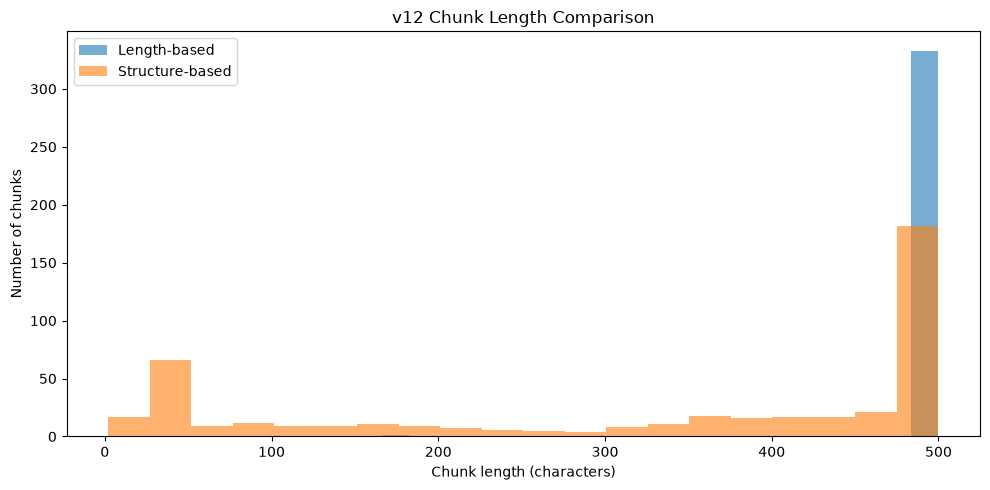

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

results = []

for name, chunks in [
    ("길이 기반", v12_length_chunks),
    ("구조 기반", v12_structure_chunks)
]:
    sizes = [len(chunk) for chunk in chunks]

    results.append({
        "청킹 방식": name,
        "Chunk 수": len(chunks),
        "평균 길이": round(pd.Series(sizes).mean(), 1),
        "중앙값": pd.Series(sizes).median(),
        "100자 미만 Chunk": sum(size < 100 for size in sizes),
        "100자 미만 비율(%)": round(
            sum(size < 100 for size in sizes) / len(sizes) * 100, 2
        )
    })

df_v12_chunk_compare = pd.DataFrame(results)
display(df_v12_chunk_compare)

# Chunk 길이 분포
plt.figure(figsize=(10, 5))

plt.hist(
    [len(chunk) for chunk in v12_length_chunks],
    bins=20,
    alpha=0.6,
    label="Length-based"
)

plt.hist(
    [len(chunk) for chunk in v12_structure_chunks],
    bins=20,
    alpha=0.6,
    label="Structure-based"
)

plt.xlabel("Chunk length (characters)")
plt.ylabel("Number of chunks")
plt.title("v12 Chunk Length Comparison")
plt.legend()
plt.tight_layout()
plt.show()

#### 분석 결과 및 해석

v12 대표문서에 길이 기반과 구조 기반 청킹을 적용하고,
생성된 Chunk의 길이를 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성된 Chunk | 334개 | 454개 |
| 평균 길이 | 499.0자 | 329.8자 |
| 중앙값 | 500자 | 409.5자 |
| 100자 미만 Chunk | 0개 | 103개 |
| 100자 미만 비율 | 0% | 22.69% |

길이 기반 청킹은 대부분의 Chunk가 500자에 가까웠다.

반면 구조 기반 청킹은 제목 경로와 요구사항 ID를 고려하여
500자에 도달하기 전에도 내용을 나누도록 설계하였다.

그 결과 길이 기반보다 더 많은 Chunk가 생성되었으며,
100자 미만의 짧은 Chunk도 103개 확인되었다.

이번 결과를 통해 다음과 같은 차이를 확인하였다.

- 길이 기반은 Chunk 길이를 일정하게 유지하기 쉽다.
- 구조 기반은 문서의 경계를 고려하지만 짧은 Chunk가 생길 수 있다.

다만 현재 실험은 글자 수 기준이며,
두 방식의 Overlap 설정도 다르다.

따라서 Chunk 길이 분포만으로
어떤 방식의 검색 성능이 더 좋은지 판단할 수 없다.

다음 단계에서는 요구사항 경계가
두 방식에서 얼마나 유지되는지 비교한다.

### 9.20 요구사항 경계 유지 비교

RFP 문서에는 서로 다른 요구사항이 포함되어 있다.

문서를 나눌 때 여러 요구사항이 하나의 Chunk에 섞이면
검색 결과에서 어떤 요구사항을 설명하는지
구분하기 어려울 수 있다.

따라서 이번에는 두 청킹 방식에서
서로 다른 요구사항 ID가 2개 이상 포함된 Chunk를 확인한다.

다만 여러 ID가 함께 등장한다고 해서
잘못된 청킹이라고 단정하지 않는다.

In [85]:
import pandas as pd

def analyze_requirement_boundaries(chunks, method):
    multiple_id_chunks = 0
    id_included_chunks = 0
    total_id_kinds = set()

    for chunk in chunks:
        ids = get_v12_requirement_ids(chunk)

        total_id_kinds.update(ids)

        if ids:
            id_included_chunks += 1

        if len(ids) >= 2:
            multiple_id_chunks += 1

    return {
        "청킹 방식": method,
        "전체 Chunk": len(chunks),
        "ID 포함 Chunk": id_included_chunks,
        "서로 다른 ID 2개 이상 Chunk": multiple_id_chunks,
        "ID 포함 Chunk 중 비율(%)": round(
            multiple_id_chunks / id_included_chunks * 100, 2
        ) if id_included_chunks else 0
    }


boundary_results = [
    analyze_requirement_boundaries(
        v12_length_chunks, "길이 기반"
    ),
    analyze_requirement_boundaries(
        v12_structure_chunks, "구조 기반"
    )
]

df_boundary_compare = pd.DataFrame(boundary_results)

display(df_boundary_compare)

,청킹 방식,전체 Chunk,ID 포함 Chunk,서로 다른 ID 2개 이상 Chunk,ID 포함 Chunk 중 비율(%)
0,길이 기반,334,157,38,24.20
1,구조 기반,454,157,20,12.74


#### 분석 결과 및 해석

v12 대표문서에서 서로 다른 요구사항 ID가
하나의 Chunk에 함께 포함되는 경우를 비교하였다.

| 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 전체 Chunk | 334개 | 454개 |
| ID 포함 Chunk | 157개 | 157개 |
| 서로 다른 ID가 2개 이상 포함된 Chunk | 38개 | 20개 |
| ID 포함 Chunk 중 비율 | 24.20% | 12.74% |

구조 기반 청킹에서는 서로 다른 요구사항 ID가
하나의 Chunk에 함께 등장하는 비율이 더 낮았다.

이는 제목 경로와 요구사항 ID를 고려해 나누는 방식이
요구사항을 구분하는 데 도움이 될 가능성을 보여준다.

반면 구조 기반 청킹에서는
100자 미만의 짧은 Chunk가 103개 생성되었다.

따라서 구조 기반은 요구사항 경계를 고려하는 데 장점이 있지만,
짧은 Chunk가 생성되는 문제도 함께 고려해야 한다.

다만 여러 ID가 함께 등장한다고 해서
잘못된 청킹이라고 단정할 수는 없다.

이번 결과는 요구사항 ID의 분포를 비교한 것이며,
실제 요구사항의 소속 정확도나 검색 성능을 의미하지 않는다.

### 9.21 v12 청킹 비교 실험 종합 결론

v12 대표문서의 Record 413개를 대상으로
길이 기반과 구조 기반 청킹을 직접 구현하고 비교하였다.

| 비교 항목 | 길이 기반 | 구조 기반 |
|---|---:|---:|
| 생성 Chunk | 334개 | 454개 |
| 평균 길이 | 499.0자 | 329.8자 |
| 최대 길이 | 500자 | 500자 |
| 100자 미만 Chunk | 0개 | 103개 |
| 100자 미만 비율 | 0% | 22.69% |
| 서로 다른 ID가 2개 이상 포함된 Chunk | 38개 | 20개 |
| ID 포함 Chunk 중 여러 ID 등장 비율 | 24.20% | 12.74% |
| 원본 ID 종류 누락 | 0종 | 0종 |

#### 주요 발견점

**1. 길이 기반 청킹의 특징**

길이 기반은 대부분의 Chunk가 500자에 가까워
일정한 길이를 유지하는 데 유리했다.

하지만 제목이나 요구사항의 경계를 고려하지 않기 때문에
서로 다른 요구사항이 하나의 Chunk에 포함될 가능성이 있었다.

**2. 구조 기반 청킹의 특징**

구조 기반은 제목 경로와 요구사항 ID를 고려해
관련 내용을 나누도록 설계하였다.

그 결과 서로 다른 요구사항 ID가 함께 등장하는 비율이
길이 기반보다 낮게 나타났다.

반면 100자 미만 Chunk가 103개 생성되어
일부 Chunk의 내용이 짧아지는 문제가 확인되었다.

**3. 원문 및 요구사항 ID 검증**

두 방식 모두 입력 텍스트가
설정한 검증 기준에 따라 전달되었다.

또한 원본에서 확인된 요구사항 ID 155종이
두 청킹 결과에서 모두 발견되었다.

다만 두 방식에서 연결 입력의 정규식 ID 집합에 없던 ID가
각각 1종씩 추가로 인식되어
청킹 경계에 따른 ID 인식 차이가 확인되었다.

#### 종합 판단

이번 실험에서는 구조 기반 청킹이
요구사항 ID의 경계를 고려하는 데 유리할 가능성을 확인하였다.

하지만 짧은 Chunk가 증가하고,
두 방식의 Overlap 조건이 다르다는 한계가 있다.

따라서 이번 결과는 구조 기반 청킹의
적용 가능성을 뒷받침하는 근거로 활용하되,
검색 성능이 더 우수하다는 결론으로 해석하지 않는다.

**이번 실험은 v12 대표문서 1개에
직접 구현한 비교용 청킹 방식을 적용한 결과이다.**

실제 팀의 v12 청킹 결과와 동일한 것은 아니며,
최종 방식 선정에는 추가적인 검색 평가가 필요하다.

**2026-10-19 추가 검증:** 마지막 절에서 두 추가 인식 모두 원래 3자리 숫자의 1자리 접두부가 Chunk 끝에서 잘려 정규식에 인식된 사례로 확인했다. 원본 검색용 입력의 문자가 새로 생성된 것은 아니다. 원본 HWP/PDF의 실제 ID 존재 여부를 검증한 결과와는 구분한다.

직접 구현한 비교 실험과 별도로 실제 팀 청킹 모듈도 확인하였다. 팀 모듈은 토큰 길이와 문서 구조를 함께 고려하며, 구조 기반 청킹에서 제목·표·원본 위치 연결 정보를 처리한다. 자세한 검증 결과는 10장에 구분하여 기록하였다.


## 10. 공개 전 최종 실행 검증 — 기존 비교 결과와 분리

2026-10-19 Desktop 최신 212셀에 마지막 계약 검사 1셀을 추가했다. 의존성을 준비한 격리 Python 3.13.5의 새 Jupyter 커널 한 개에서 **전체 213셀의 코드 75개를 위에서 아래로 모두 실행**했다. 오류 셀과 생략한 팀 비교는 없다. 기존 Native 245/579개, v12 334/454개 Chunk와 주요 길이·ID·표 검증 수치를 재현했다.

기존 분석의 저장 출력·두 그래프를 보존하고 수치를 새 실행과 대조했다. 설정 코드와 맞지 않았던 과거 설정 출력 5개는 실제 새 출력으로 갱신했다. ID/팀 진단 표 두 개는 생략 표시가 없는 새 출력으로 갱신했으며 HTML 셀 값은 이전과 동일하다. 셀 번호는 0부터 센다. 기존 출력의 실행 번호는 역사 기록이므로 현재 실행 순서를 나타내지 않는다. 실제 순서 실행 검증은 별도 실행 노트북으로 확인했다.

### 10.1 추가 ID의 원본 좌표 대응

각 Chunk를 연결 입력의 정확한 좌표에 대응하고, 추가 인식된 문자열의 뒤에 숫자가 더 이어지는지 확인한다. 실제 ID 문자열이나 문서명은 출력하지 않는다.


In [73]:
# 신규 진단: 기존 변수와 결과를 변경하지 않는다.
import re
import hashlib
import json
import pandas as pd

review_pattern = re.compile(r"\b([A-Z]{2,6})\s*[-－]\s*(\d{1,4})\b")
review_source = "\n".join(r.get("search_text") or "" for r in v12_selected_records)
review_source_matches = list(review_pattern.finditer(review_source))
review_source_ids = {f"{m[1]}-{m[2]}" for m in review_source_matches}
review_rows = []
for review_method, review_chunks in [("길이 기반", v12_length_chunks), ("구조 기반", v12_structure_chunks)]:
    review_cursor = 0
    for review_index, review_chunk in enumerate(review_chunks):
        # 길이 기반은 고정 창의 정확한 좌표, 구조 기반은 입력에서 순서대로 정확히 대응한다.
        if review_method == "길이 기반":
            review_start = review_index * (CHUNK_SIZE - CHUNK_OVERLAP)
        else:
            review_start = review_source.find(review_chunk, review_cursor)
        assert review_start >= 0
        assert review_source[review_start:review_start + len(review_chunk)] == review_chunk
        review_cursor = review_start + len(review_chunk)
        for review_match in review_pattern.finditer(review_chunk):
            review_id = f"{review_match[1]}-{review_match[2]}"
            if review_id in review_source_ids:
                continue
            review_a = review_start + review_match.start()
            review_z = review_start + review_match.end()
            review_owners = [m for m in review_source_matches if m.start() == review_a and m.end() >= review_z]
            review_full = review_owners[0] if len(review_owners) == 1 else None
            review_next_is_digit = review_z < len(review_source) and review_source[review_z].isdigit()
            review_partial = bool(review_full and review_full.end() > review_z and review_next_is_digit)
            review_rows.append({
                "방식": review_method,
                "Chunk 번호(0부터)": review_index,
                "입력 시작 좌표": review_a,
                "Chunk 끝에서 인식": review_match.end() == len(review_chunk),
                "입력에서 다음 문자는 숫자": review_next_is_digit,
                "인식 숫자 길이": len(review_match[2]),
                "입력 전체 ID 숫자 길이": len(review_full[2]) if review_full else None,
                "원본 문자 그대로 대응": True,
                "판정": "숫자 접두부 부분 인식" if review_partial else "추가 원문 검토 필요",
            })
review_id_diagnostics = pd.DataFrame(review_rows)
display(review_id_diagnostics)
print("이 진단은 검색용 입력의 경계를 검증합니다. 원본 HWP/PDF에 해당 요구사항이 실제 존재하는지는 별도 원문 검토 대상입니다.")
print("Native 대표 입력 SHA-256:", hashlib.sha256(json.dumps(selected_elements, sort_keys=True, ensure_ascii=False).encode()).hexdigest())
print("v12 대표 입력 SHA-256:", hashlib.sha256(json.dumps(v12_selected_records, sort_keys=True, ensure_ascii=False).encode()).hexdigest())


,방식,Chunk 번호(0부터),입력 시작 좌표,Chunk 끝에서 인식,입력에서 다음 문자는 숫자,인식 숫자 길이,입력 전체 ID 숫자 길이,원본 문자 그대로 대응,판정
0,길이 기반,30,13995,True,True,1,3,True,숫자 접두부 부분 인식
1,구조 기반,25,9926,True,True,1,3,True,숫자 접두부 부분 인식


이 진단은 검색용 입력의 경계를 검증합니다. 원본 HWP/PDF에 해당 요구사항이 실제 존재하는지는 별도 원문 검토 대상입니다.
Native 대표 입력 SHA-256: e1ad3c7099d39cb31e633875abcdaa44727c474cc17f4b1c8d2bdff678c294d5
v12 대표 입력 SHA-256: 6ee9ef8f5d5e9a54e05bd11b91b320753e0c1ccb8427b17a4c2559a50222c99f


두 추가 인식 모두 입력의 같은 위치에 원래 3자리 숫자 ID가 있었고, Chunk의 마지막에서는 숫자 1자리만 남았다. 정규식의 `\b`는 문자열 끝에서도 성립해 그 숫자 접두부를 별개 ID로 인식했다. 길이 기반 Chunk 30, 구조 기반 Chunk 25(0부터)의 사례다. 따라서 155→156은 실제 요구사항 생성 수가 아니다. 단순히 정규식 끝에 숫자 부정 탐색을 추가해도 잘린 Chunk 바깥 문자를 볼 수 없으므로, 확정 ID는 원본 좌표 또는 원래 ID 메타데이터로 검증해야 한다. 기존 정규식/청킹을 바꾸어 옛 실험값을 대체하지 않았다.

### 10.2 실제 팀 청킹 모듈 — Native 대표문서의 별도 비교군

확인한 소스 위치는 외부 실험 자료 루트 기준 `original_sources/team_src/rfp_assistant/retrieval/chunking.py`다. `RFP_TEAM_SRC`에는 `rfp_assistant`가 들어 있는 소스 루트를 지정한다. 함수 계약은 `build_profile(elements: list[dict], extraction_id: str, profile: str) -> (chunks, inventory)`다. 입력은 동일 추출 그룹의 정렬된 Element이며 `element_id`, `kind`, `raw_text`, `location.section_path`, 표의 `rows/cols/cells` 등을 필요로 한다. 순서는 호출자가 제공한다. 반환 Chunk는 `payload`, `body`, token_count, spans, linked, requirement_key 등을 가진다.

같은 Native 1,699개 Element를 복사하여 수정 없이 전달했다. 팀 코드는 raw_text를 사용하고 실제 목차를 제외하며 heading 추가·표 헤더 반복·병합 셀·token 창 처리를 한다. 기존 실험은 search_text와 별도 표 재구성을 사용하므로 동일 텍스트 전처리의 통제 비교는 아니다. `structural`의 target/hard/overlap은 700/800/64 token이고 `fixed-512-64`는 512/64 token이다. 두 팀 profile도 크기가 같지 않아 우열을 판단하는 대조 실험은 아니다. 아래 Chunk 수를 기존 500자 표에 섞지 않는다.

이전 검토에서는 팀 호출을 별도 환경에서 수행했다. 이번 최종 검증에서는 pandas/IPython과 팀 의존성을 같은 격리 환경에 준비하여 아래 셀 그대로 전체 노트북과 함께 실행했다. 초기 rfp-rag 환경은 psycopg 누락으로 실패했고, 기존 gate-python 환경에서는 로컬 o200k_base 캐시를 지정해 실행했다. 네트워크 다운로드·검색·임베딩·DB 호출·Generation은 수행하지 않았다. 새 환경에는 모듈의 간접 import 의존성(예: psycopg, 설정 관련 패키지, numpy)과 tiktoken이 필요하다. `TIKTOKEN_CACHE_DIR`로 기존 캐시를 지정하면 다운로드 없이 실행할 수 있다. import와 tokenizer가 가능한 환경에서 새 커널을 사용한다.


In [74]:
# 신규 별도 비교군: 기존 500자 비교용 알고리즘의 결과에 섞지 않는다.
import os
import sys
import copy
import importlib
import hashlib
from pathlib import Path
import pandas as pd

review_team_src = os.environ.get("RFP_TEAM_SRC")
if not review_team_src:
    print("팀 모듈 미실행: RFP_TEAM_SRC를 rfp_assistant 패키지가 있는 소스 루트로 설정하세요.")
else:
    # 새 커널에서 실행하여 다른 버전의 rfp_assistant가 이미 import된 상태를 피한다.
    if "rfp_assistant" in sys.modules:
        raise RuntimeError("새 커널에서 RFP_TEAM_SRC를 설정한 뒤 실행하세요.")
    sys.dont_write_bytecode = True
    sys.path.insert(0, str(Path(review_team_src).expanduser().resolve()))
    review_team = importlib.import_module("rfp_assistant.retrieval.chunking")
    review_loaded = Path(review_team.__file__).resolve()
    if not review_loaded.is_relative_to(Path(review_team_src).expanduser().resolve()):
        raise RuntimeError("설정한 소스와 실제 import 모듈의 경로가 다릅니다.")
    review_expected_sha = "2d8119daa2d234d504ce2d287bbb8f3aba11386fe13a6b325bdb4707ef89df5a"
    if hashlib.sha256(review_loaded.read_bytes()).hexdigest() != review_expected_sha:
        raise RuntimeError("기록한 비교 대상과 다른 팀 소스입니다. 버전을 확인하세요.")
    review_team_input = copy.deepcopy(selected_elements)
    review_input_ids = {e["extraction_id"] for e in review_team_input}
    assert len(review_input_ids) == 1
    review_extraction_id = next(iter(review_input_ids))
    review_elements_by_id = {e["element_id"]: e for e in review_team_input}
    review_team_rows = []
    for review_profile in ("structural", "fixed-512-64"):
        review_team_chunks, review_inventory = review_team.build_profile(
            review_team_input, review_extraction_id, review_profile
        )
        review_bad_spans = 0
        for review_c in review_team_chunks:
            for review_span in review_c["spans"]:
                review_e = review_elements_by_id.get(review_span["element_id"])
                if review_e is None:
                    review_bad_spans += 1
                elif "start" in review_span:
                    review_bad_spans += not (0 <= review_span["start"] < review_span["end"] <= len(review_e["raw_text"]))
                elif "rows" in review_span:
                    review_bad_spans += any(not 0 <= row < review_e["table"]["rows"] for row in review_span["rows"])
                else:
                    review_bad_spans += 1
        review_team_rows.append({
            "비교군": review_profile,
            "입력 Element": len(review_team_input),
            "Chunk 수": len(review_team_chunks),
            "최대 payload token": max((c["token_count"] for c in review_team_chunks), default=0),
            "요구사항 inventory 행": len(review_inventory),
            "span 참조·범위 오류": review_bad_spans,
            "본문에 search_text 사용": False,
        })
    review_team_results = pd.DataFrame(review_team_rows)
    display(review_team_results)
    print("모듈 버전:", review_team.CHUNKER_VERSION)
    print("실제 structural 설정(target, hard, overlap token):", review_team.structural_limits())
    print("토크나이저:", review_team.TOKENIZER)
    print("chunking.py SHA-256:", hashlib.sha256(review_loaded.read_bytes()).hexdigest())
    print("경로 공개 없이 소스 해시와 실제 모듈 선택을 기록했습니다.")


,비교군,입력 Element,Chunk 수,최대 payload token,요구사항 inventory 행,span 참조·범위 오류,본문에 search_text 사용
0,structural,1699,347,789,96,0,False
1,fixed-512-64,1699,157,512,96,0,False


모듈 버전: structural-7-uniform
실제 structural 설정(target, hard, overlap token): (700, 800, 64)
토크나이저: o200k_base
chunking.py SHA-256: 2d8119daa2d234d504ce2d287bbb8f3aba11386fe13a6b325bdb4707ef89df5a
경로 공개 없이 소스 해시와 실제 모듈 선택을 기록했습니다.


### 10.3 검증 범위와 재현 증거

팀 `structural` 347개(최대 789 token), `fixed-512-64` 157개(최대 512 token), 각 inventory 96행이었다. 선택 Element ID 참조와 prose start/end·table row 범위 검사에서 오류는 0건이었다. 이는 span 본문 의미 대응·모든 표 fragment 좌표·전체 원문 보존 인증·요구사항 소속 정확도 검증이 아니다. v12 Record를 팀 입력으로 임의 변환하지 않았으며 **v12 대표문서에 대한 팀 모듈 재실행 비교는 추가하지 않았다**.

- Native elements 파일 SHA-256: `c6edfdb540083c9291a9a1765b5485928653af5a2bce426bbbeffab71e56bf8b`
- v12 records 파일 SHA-256: `fe92d899b8b3109ad25158e545b60d564edc1b73f78b7feb5c4b2e088b751b24`
- 선택 입력 목록의 정렬 JSON SHA-256은 10.1 출력에 기록했다. JSON 직렬화 기준은 ensure_ascii=False, sort_keys=True다.
- 팀 실행 Python: `3.13.5`, tiktoken: `0.14.0`. 실제 팀 소스 SHA-256·설정·토크나이저는 10.2 출력에 기록했다.

기존 두 그래프의 PNG는 그대로 보존했다. 각 hist의 자동 bin 경계가 같다고 보장되지 않아 막대 높이의 정밀한 직접 비교보다 수치 표를 우선한다. 향후 같은 입력 표현·token 예산·Overlap·표/목차 정책을 통제하고, 별도 평가 질문과 정답 근거로 검색 품질을 측정해야 최종 전략을 선택할 수 있다.


### 최종 보완과 실행 환경

저장소 Ruff 복잡도 제한(C901 ≤8)을 맞추기 위해 비교용 셀 60·102의 행 렌더링/본문 결합/구역 시작 처리를 작은 함수로 분리했다. 알고리즘의 조건과 출력 순서는 유지했다. 원래 함수와 대표 1,699개 Element·표 175개를 100/500/800자 제한에서 대조하여 전체 Chunk 문자열 목록이 일치함을 확인했다. 팀 청킹 소스는 변경하지 않았다.

마지막 셀은 team profile별 token_count 재계산, extraction_id, 참조 Element의 section_path, requirement_key의 원본 참조 텍스트 내 존재, 표 fragment 좌표, linked 및 inventory 참조를 확인한다. 두 profile 모두 검사 오류 0이었다. 이는 메타데이터의 구조적 일관성 검사이며 실제 요구사항 소속의 의미 정확도를 인증하지 않는다.

전체 실행에서 누락 import/미정의 변수/셀 순서 오류는 없었다. 필요한 외부 파일·팀 소스 트리가 없으면 동일 실행은 불가능하다. 커널 종료 시 운영체제의 프로세스 목록 접근 제한(psutil/sysctl) 경고가 실행 호스트 로그에 있었으나, 코드 75개 실행은 모두 완료되었고 노트북 오류 출력은 0이다.

| 패키지 | 최종 검증 버전 |
|---|---|
| python | 3.13.5 |
| pandas | 2.2.3 |
| matplotlib | 3.10.0 |
| ipython | 8.30.0 |
| ipykernel | 6.29.5 |
| numpy | 2.1.3 |
| pydantic | 2.10.3 |
| pydantic-settings | 2.6.1 |
| python-dotenv | 1.1.0 |
| psycopg | 3.3.6 |
| psycopg-pool | 3.3.3 |
| pgvector | 0.5.1 |
| tiktoken | 0.14.0 |
| nbclient | 0.10.2 |
| nbformat | 5.10.4 |


In [75]:
# 실제 팀 결과의 토큰 수·소속·span fragment를 별도로 검증한다.
assert review_team_src, "RFP_TEAM_SRC가 없어 팀 검증이 생략되었습니다."
review_contract_rows = []
for review_p in ("structural", "fixed-512-64"):
    review_before_input = copy.deepcopy(selected_elements)
    review_cs, review_inv = review_team.build_profile(
        copy.deepcopy(selected_elements), review_extraction_id, review_p
    )
    review_map = {e["element_id"]: e for e in selected_elements}
    review_chunk_ids = {c["chunk_id"] for c in review_cs}
    review_errors = {"token": 0, "extraction": 0, "section": 0, "requirement": 0, "fragment": 0, "linked": 0, "inventory": 0}
    for review_c in review_cs:
        review_errors["token"] += review_team.count_tokens(review_c["payload"]) != review_c["token_count"]
        review_errors["extraction"] += review_c["extraction_id"] != review_extraction_id
        review_refs = [review_map[sp["element_id"]] for sp in review_c["spans"]]
        review_errors["section"] += review_c["section_path"] not in [e["location"].get("section_path", []) for e in review_refs]
        review_codes = set(review_team.CODE_RE.findall("\n".join(e["raw_text"] for e in review_refs)))
        review_errors["requirement"] += bool(review_c["requirement_key"] and review_c["requirement_key"] not in review_codes)
        review_errors["linked"] += any(k not in review_chunk_ids for k in review_c["linked"])
        for review_sp in review_c["spans"]:
            if "fragment" not in review_sp:
                continue
            review_f = review_sp["fragment"]
            review_rows_by_id = dict(review_team.table_rows(review_map[review_sp["element_id"]]))
            review_line = review_rows_by_id.get(review_f["row"])
            review_errors["fragment"] += review_line is None or not 0 <= review_f["start"] < review_f["end"] <= len(review_line)
    review_errors["inventory"] += sum(x["element_id"] not in review_map for x in review_inv)
    assert selected_elements == review_before_input
    assert not any(review_errors.values()), review_errors
    assert max(c["token_count"] for c in review_cs) <= (800 if review_p == "structural" else 512)
    review_contract_rows.append({"profile": review_p, **review_errors, "input_unchanged": True})
display(pd.DataFrame(review_contract_rows))
print("구조적 참조·범위와 메타데이터 대응 검사입니다. 원문 의미의 소속 정확도 인증은 아닙니다.")


,profile,token,extraction,section,requirement,fragment,linked,inventory,input_unchanged
0,structural,0,0,0,0,0,0,0,True
1,fixed-512-64,0,0,0,0,0,0,0,True


구조적 참조·범위와 메타데이터 대응 검사입니다. 원문 의미의 소속 정확도 인증은 아닙니다.
